
================ NSGA-II RAW FILE CHECK ================
 dataset                  policy         target_case  seed                                                                                                                                                                                                                                                                                         path
jarvis18             NSGA-II QBC bandgap_bulkmodulus     0                       C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\growing_EA_2obj_qbc_only\jarvis18\bandgap_bulkmodulus\0\jarvis18_bandgap_bulkmodulusgrowing_EA_2obj_qbc_only_rf0.csv
jarvis18             NSGA-II QBC bandgap_bulkmodulus     1                       C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\growing_EA_2obj_qbc_only\ja

C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3396851400.py:1024: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3396851400.py:1024: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3396851400.py:1024: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3396851400.py:1024: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.

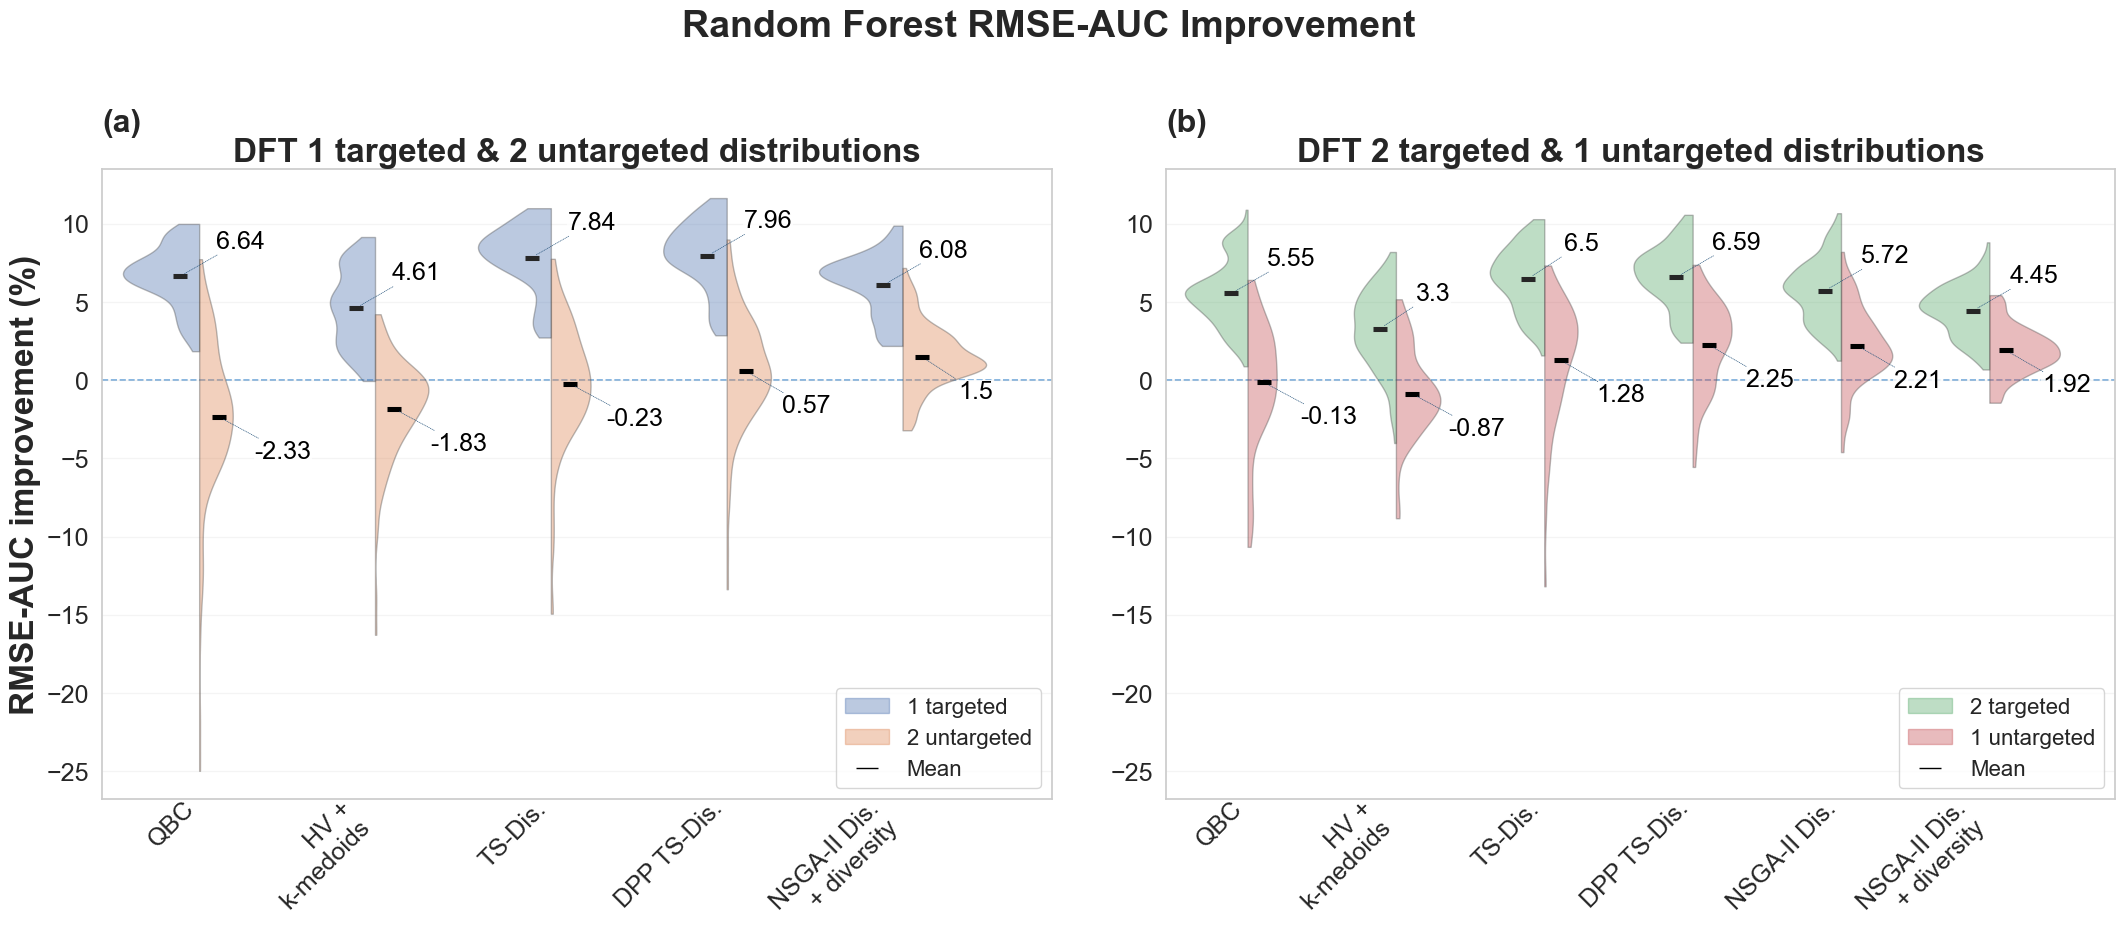


Saved figure: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_RF_Joint_Representative_QBC_Case_UntargetedFirst\DFT_RF_ALL_RAW_CASES_violin_only_ordered_untargeted.png
Saved violin plotting dataframe: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_RF_Joint_Representative_QBC_Case_UntargetedFirst\dft_rf_violin_ALL_RAW_CASES_plot_data.csv


In [4]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
INPUT_ROOT = BASE_ROOT / "plots" / "rmse_auc_improvement_DFT"
OUTPUT_ROOT = BASE_ROOT / "plots" / "DFT_RF_Joint_Representative_QBC_Case_UntargetedFirst"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "DFT_RF_ALL_RAW_CASES_violin_only_ordered_untargeted.png"
OUTPUT_SELECTED_CASE = OUTPUT_ROOT / "selected_joint_representative_qbc_case_untargeted_first.csv"
OUTPUT_CASE_SUMMARY = OUTPUT_ROOT / "joint_representative_qbc_case_summary_all_cases_untargeted_first.csv"
OUTPUT_TOP_PLOT_DATA = OUTPUT_ROOT / "dft_rf_violin_ALL_RAW_CASES_plot_data.csv"
SEEDS = range(5)
MODEL = "rf"
MODEL_DISPLAY = "Random Forest"
# =============================================================================
# DFT outcomes and case definitions
# =============================================================================
# Canonical property -> accepted raw RMSE column names.
# Some DFT runs save formation energy as rmse_eform, others as rmse_e_form.
RMSE_METRIC_ALIASES = {
    "e_form": ["rmse_eform", "rmse_e_form"],
    "bulk_modulus": ["rmse_bulk_modulus"],
    "bandgap": ["rmse_bandgap"],
}
PROPERTY_LABELS = {
    "e_form": "Formation energy",
    "bulk_modulus": "Bulk modulus",
    "bandgap": "Band gap",
}
PROPERTY_YLABELS = {
    "e_form": "RMSE [eV/atom]",
    "bulk_modulus": "RMSE [GPa]",
    "bandgap": "RMSE [eV]",
}
# For panel selection we index by canonical property name.
PROPERTY_TO_METRIC = {
    "e_form": "e_form",
    "bulk_modulus": "bulk_modulus",
    "bandgap": "bandgap",
}
ALL_PROPERTIES = ["e_form", "bulk_modulus", "bandgap"]
TARGET_CASES = {
    "e_form": {"e_form"},
    "bulk_modulus": {"bulk_modulus"},
    "bandgap": {"bandgap"},
    "eform_bulk_modulus": {"e_form", "bulk_modulus"},
    "bandgap_eform": {"bandgap", "e_form"},
    "bandgap_bulkmodulus": {"bandgap", "bulk_modulus"},
}
ONE_TARGET_CASES = {"e_form", "bulk_modulus", "bandgap"}
DATASET_ALIASES = {
    "mp18": ["mp18", "mp_18", "mp-18", "mp2018", "mp_2018", "mp-2018"],
    "mp21": ["mp21", "mp_21", "mp-21", "mp2021", "mp_2021", "mp-2021"],
    "jarvis18": ["jarvis18", "jarvis_18", "jarvis-18", "jarvis2018", "jarvis_2018", "jarvis-2018"],
    "jarvis22": ["jarvis22", "jarvis_22", "jarvis-22", "jarvis2022", "jarvis_2022", "jarvis-2022"],
}
# =============================================================================
# Policies and display configuration
# =============================================================================
# Original internal keys retain compatibility with existing filenames/data.
POLICY_ORDER = [
    "QBC",
    "HV + k-medoids",
    "TS-QBC",
    "DPP-TS-QBC",
    "NSGA-II QBC",
    "NSGA-II QBC + diversity",
]
ONE_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
TWO_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
ONE_TARGET_RMSE_POLICY_ORDER = POLICY_ORDER + ["Random"]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
    "HV": "HV",
    "Random": "Random",
}
CASE_COLORS = {
    "1 targeted": "#4c72b0",
    "2 untargeted": "#dd8452",
    "2 targeted": "#55a868",
    "1 untargeted": "#c44e52",
}
POLICY_COLORS = {
    "QBC": "tab:gray",
    "HV": "tab:orange",
    "HV + k-medoids": "tab:orange",
    "TS-QBC": "tab:green",
    "DPP-TS-QBC": "tab:green",
    "NSGA-II QBC": "tab:red",
    "NSGA-II QBC + diversity": "tab:red",
    "Random": "tab:blue",
}
POLICY_LINESTYLES = {
    "QBC": "-",
    "HV": "-",
    "HV + k-medoids": "dotted",
    "TS-QBC": "-",
    "DPP-TS-QBC": "dotted",
    "NSGA-II QBC": "-",
    "NSGA-II QBC + diversity": "dotted",
    "Random": "-",
}
# =============================================================================
# General helpers
# =============================================================================
def _norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())
def canonicalize_policy(value):
    if pd.isna(value):
        return np.nan
    raw = str(value).strip()
    key = _norm(raw)
    if "growdisagreementhvtopmkmedoids" in key or "hvkmedoids" in key:
        return "HV + k-medoids"
    if "growdisagreementhv" in key and "kmedoids" not in key:
        return "HV"
    if "dpptsqbc" in key:
        return "DPP-TS-QBC"
    if "tsqbc" in key and "dpptsqbc" not in key:
        return "TS-QBC"
    if "nsgaii" in key and "qbc" in key and "divers" in key:
        return "NSGA-II QBC + diversity"
    if (
        "groweadeltadiversity" in key
        or "growingeadeltadiversity" in key
        or (("growea" in key or "growingea" in key) and "divers" in key)
        or "groweaqbc1objwithdiversity" in key
        or "growingeaqbc1objwithdiversity" in key
        or "groweaqbc1objwithdiversityfrom3outcomes" in key
        or "growingeaqbc1objwithdiversityfrom3outcomes" in key
    ):
        return "NSGA-II QBC + diversity"
    if "nsgaii" in key and "qbc" in key:
        return "NSGA-II QBC"
    if (
        (("growea" in key or "growingea" in key) and "divers" not in key)
        or "groweaqbc1obj" in key
        or "growingeaqbc1obj" in key
        or "growingea2objqbconly" in key
    ):
        return "NSGA-II QBC"
    qbc_aliases = {
        "qbc", "1qbc", "2qbc", "3qbc",
        "growqbc", "growingqbc", "grow2qbc", "growing2qbc",
    }
    if key in qbc_aliases or "grow2qbc" in key:
        return "QBC"
    if "random" in key:
        return "Random"
    aliases = {
        "hv": "HV",
        "hvkmedoids": "HV + k-medoids",
        "nsgaiiqbc": "NSGA-II QBC",
        "nsgaiiqbcdiversity": "NSGA-II QBC + diversity",
        "tsqbc": "TS-QBC",
        "dpptsqbc": "DPP-TS-QBC",
    }
    return aliases.get(key, raw)
def identify_dataset(text):
    normalized = _norm(text)
    for dataset, aliases in DATASET_ALIASES.items():
        for alias in aliases:
            if _norm(alias) in normalized:
                return dataset
    return None
def identify_seed_and_model(path):
    path = Path(path)
    match = re.search(r"(?:_|-|\s)(rf|xgb)(\d*)\.csv$", path.name, flags=re.IGNORECASE)
    if not match:
        return None, None
    model = match.group(1).lower()
    digits = match.group(2)
    if digits != "":
        return model, int(digits)
    if path.parent.name.isdigit():
        return model, int(path.parent.name)
    for parent in path.parents:
        if parent.name.isdigit():
            return model, int(parent.name)
    return model, None
def identify_target_case(text):
    compact = _norm(text)
    ordered = [
        ("eform_bulk_modulus", ["eformbulkmodulus"]),
        ("bandgap_bulkmodulus", ["bandgapbulkmodulus"]),
        ("bandgap_eform", ["bandgapeform"]),
        ("bulk_modulus", ["bulkmodulus"]),
        ("bandgap", ["bandgap"]),
        ("e_form", ["eform"]),
    ]
    for target, aliases in ordered:
        if any(_norm(alias) in compact for alias in aliases):
            return target
    return None
def is_plain_qbc_file(path):
    path = Path(path)
    compact_name = _norm(path.name)
    compact_parts = {_norm(part) for part in path.parts}
    full_compact = _norm(str(path))
    if "dpptsqbc" in full_compact or "tsqbc" in full_compact or "nsgaii" in full_compact:
        return False
    if "grow2qbc" in compact_parts or "qbc" in compact_parts:
        return True
    if "grow2qbc" in compact_name or "growing2qbc" in compact_name:
        return True
    return re.search(
        r"(?:^|[_\-])qbc[_\-](?:rf|xgb)\d*\.csv$",
        path.name,
        flags=re.IGNORECASE,
    ) is not None
def load_curve(path):
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        return None
    df = df.copy()
    df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
    return df
def normalized_rmse_auc(df, metric):
    if df is None or metric not in df.columns:
        return None
    curve = (
        df[["train_percent", metric]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
        .groupby("train_percent", as_index=False)[metric]
        .mean()
        .sort_values("train_percent")
    )
    if len(curve) < 2:
        return None
    x = curve["train_percent"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    auc = np.trapezoid(y, x)
    return {"mean_rmse_auc": float(auc / width)}
def resolve_metric_column(df, canonical_property):
    """
    Return the first matching raw RMSE column for a canonical property.
    Example:
      canonical_property='e_form' -> rmse_eform or rmse_e_form
    """
    aliases = RMSE_METRIC_ALIASES.get(canonical_property, [])
    for col in aliases:
        if col in df.columns:
            return col
    return None
def normalized_rmse_auc_for_property(df, canonical_property):
    metric_col = resolve_metric_column(df, canonical_property)
    if metric_col is None:
        return None
    return normalized_rmse_auc(df, metric_col)
def find_matching_random(random_index, dataset, model, seed, target_case):
    if random_index.empty:
        return None
    candidates = random_index.loc[
        (random_index["dataset"] == dataset)
        & (random_index["model"] == model)
        & (random_index["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    exact = candidates.loc[candidates["target_case"] == target_case]
    if not exact.empty:
        return exact.iloc[0]["path"]
    all_case = candidates.loc[candidates["target_case"] == "all"]
    if not all_case.empty:
        return all_case.iloc[0]["path"]
    if len(candidates) == 1:
        return candidates.iloc[0]["path"]
    return candidates.iloc[0]["path"]
# =============================================================================
# Build TOP violin dataframe DIRECTLY from ALL raw DFT AL files
# =============================================================================
#
# No precomputed DFT_rmse_auc_improvement_by_seed_rf.csv is used for the
# violin panels.
#
# Every violin observation is calculated independently for one:
#
#     dataset x target_case x policy x seed x property
#
# using:
#
#     100 * (1 - policy_RMSE_AUC / random_RMSE_AUC)
#
# The top violin plots therefore aggregate ALL available raw DFT cases from:
#
#     datasets:
#         MP18, MP21, JARVIS18, JARVIS22
#
#     one-target campaigns:
#         e_form, bulk_modulus, bandgap
#
#     two-target campaigns:
#         eform_bulk_modulus, bandgap_eform, bandgap_bulkmodulus
#
#     seeds:
#         0, 1, 2, 3, 4
#
#     properties:
#         formation energy, bulk modulus, band gap
#
# Nothing is averaged before the observations are passed to seaborn.
# =============================================================================
def detect_all_raw_policy(path):
    """
    Detect acquisition policy for both one-target and two-target DFT raw files.
    """
    path = Path(path)
    full = _norm(str(path))
    name = _norm(path.name)
    stem = _norm(path.stem)
    if "random" in full:
        return "Random"
    # DPP-TS before TS/QBC.
    if "dpptsqbc" in full:
        return "DPP-TS-QBC"
    if "tsqbc" in full and "dpptsqbc" not in full:
        return "TS-QBC"
    # HV + k-medoids before plain HV.
    if (
        "growdisagreementhvtopmkmedoids" in full
        or "hvkmedoids" in full
    ):
        return "HV + k-medoids"
    if (
        "growdisagreementhv" in full
        and "kmedoids" not in full
    ):
        return "HV"
    # NSGA-II / EA with diversity.
    #
    # Handle both historical folder families:
    #     grow_EA_...
    #     growing_EA_...
    #
    # Normalization removes underscores, e.g.
    #     growing_EA_2obj_qbc_only -> growingea2objqbconly
    #
    # Diversity variants are classified first.
    if (
        "groweaqbc1objwithdiversityfrom3outcomes" in full
        or "growingeaqbc1objwithdiversityfrom3outcomes" in full
        or "groweaqbc1objwithdiversity" in full
        or "growingeaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or "growingeadeltadiversity" in full
        or (
            ("growea" in full or "growingea" in full)
            and "divers" in full
        )
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # NSGA-II / EA without diversity.
    #
    # Explicitly includes the actual two-target family:
    #     growing_EA_2obj_qbc_only
    if (
        "growingea2objqbconly" in full
        or "growea2objqbconly" in full
        or "groweaqbc1objfrom3outcomes" in full
        or "growingeaqbc1objfrom3outcomes" in full
        or "groweaqbc1obj" in full
        or "growingeaqbc1obj" in full
        or (
            ("growea" in full or "growingea" in full)
            and "divers" not in full
        )
        or ("nsgaii" in full and "divers" not in full)
        or stem.startswith("growea")
        or stem.startswith("growingea")
        or name.startswith("growea")
        or name.startswith("growingea")
    ):
        return "NSGA-II QBC"
    # Plain QBC, including 1-target QBC folders and grow2QBC families.
    if is_plain_qbc_file(path):
        return "QBC"
    fallback = canonicalize_policy(str(path))
    if fallback in {
        "QBC",
        "HV",
        "HV + k-medoids",
        "NSGA-II QBC",
        "NSGA-II QBC + diversity",
        "TS-QBC",
        "DPP-TS-QBC",
        "Random",
    }:
        return fallback
    return None
def discover_all_raw_dft_files():
    """
    Index every usable RF raw DFT AL CSV for the violin calculation.
    """
    if not DATA_ROOT.exists():
        raise FileNotFoundError(
            f"Raw AL folder does not exist:\n{DATA_ROOT}"
        )
    rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        dataset = identify_dataset(str(path))
        if dataset not in DATASET_ALIASES:
            continue
        policy = detect_all_raw_policy(path)
        if policy is None:
            continue
        target_case = identify_target_case(str(path))
        # Generic Random files often do not encode a target case.
        if policy == "Random":
            target_case_out = (
                target_case if target_case in TARGET_CASES else "all"
            )
        else:
            if target_case not in TARGET_CASES:
                continue
            target_case_out = target_case
        rows.append(
            {
                "dataset": dataset,
                "model": model,
                "seed": int(seed),
                "policy": policy,
                "target_case": target_case_out,
                "path": Path(path),
            }
        )
    index_df = pd.DataFrame(rows)
    if index_df.empty:
        raise RuntimeError(
            "No raw RF DFT AL files were discovered."
        )
    # Prevent the exact same path from entering more than once.
    index_df = index_df.drop_duplicates(
        subset=["dataset", "model", "seed", "policy", "target_case", "path"]
    ).reset_index(drop=True)
    # Explicit diagnostic for NSGA-II file discovery.
    nsga_diag = index_df.loc[
        index_df["policy"].isin(
            ["NSGA-II QBC", "NSGA-II QBC + diversity"]
        )
    ].copy()
    print(
        "\n================ NSGA-II RAW FILE CHECK ================"
    )
    if nsga_diag.empty:
        print("WARNING: no NSGA-II raw files were detected.")
    else:
        print(
            nsga_diag[
                ["dataset", "policy", "target_case", "seed", "path"]
            ]
            .sort_values(
                ["dataset", "policy", "target_case", "seed"]
            )
            .to_string(index=False)
        )
    print(
        "\n================ ALL RAW DFT FILE INDEX ================"
    )
    print(
        index_df[
            ["dataset", "policy", "target_case", "seed", "path"]
        ]
        .sort_values(
            ["dataset", "policy", "target_case", "seed"]
        )
        .to_string(index=False)
    )
    return index_df
def find_matching_random_all_cases(
    index_df,
    dataset,
    seed,
    target_case,
):
    """
    Match Random by dataset and seed.
    Prefer a target-case-specific Random file when available, otherwise use
    the generic/all Random file.
    """
    candidates = index_df.loc[
        (index_df["policy"] == "Random")
        & (index_df["dataset"] == dataset)
        & (index_df["model"] == MODEL)
        & (index_df["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    exact = candidates.loc[
        candidates["target_case"] == target_case
    ]
    if not exact.empty:
        return exact.iloc[0]["path"]
    generic = candidates.loc[
        candidates["target_case"] == "all"
    ]
    if not generic.empty:
        return generic.iloc[0]["path"]
    return candidates.iloc[0]["path"]
def build_top_plot_dataframe():
    """
    Build ALL top-row violin observations directly from raw RF DFT AL data.
    One dataframe row corresponds to one:
        dataset x target campaign x policy x seed x property
    raw RMSE-AUC improvement observation.
    """
    file_index = discover_all_raw_dft_files()
    policy_index = file_index.loc[
        file_index["policy"] != "Random"
    ].copy()
    rows = []
    for file_row in policy_index.itertuples(index=False):
        target_case = file_row.target_case
        if target_case not in TARGET_CASES:
            continue
        targeted_properties = TARGET_CASES[target_case]
        n_targets = len(targeted_properties)
        if n_targets not in {1, 2}:
            continue
        random_path = find_matching_random_all_cases(
            index_df=file_index,
            dataset=file_row.dataset,
            seed=file_row.seed,
            target_case=target_case,
        )
        if random_path is None:
            print(
                "WARNING: no matching Random raw file | "
                f"dataset={file_row.dataset}, "
                f"seed={file_row.seed}, "
                f"target_case={target_case}"
            )
            continue
        policy_df = load_curve(file_row.path)
        random_df = load_curve(random_path)
        if policy_df is None or random_df is None:
            continue
        for property_id, property_name in PROPERTY_LABELS.items():
            policy_auc = normalized_rmse_auc_for_property(
                policy_df,
                property_id,
            )
            random_auc = normalized_rmse_auc_for_property(
                random_df,
                property_id,
            )
            if policy_auc is None or random_auc is None:
                continue
            random_value = random_auc["mean_rmse_auc"]
            if np.isclose(
                random_value,
                0.0,
                atol=1e-15,
                rtol=0.0,
            ):
                print(
                    "WARNING: Random RMSE-AUC is zero; skipping | "
                    f"dataset={file_row.dataset}, "
                    f"policy={file_row.policy}, "
                    f"target_case={target_case}, "
                    f"seed={file_row.seed}, "
                    f"property={property_id}"
                )
                continue
            improvement = 100.0 * (
                1.0
                - policy_auc["mean_rmse_auc"]
                / random_value
            )
            case_type = (
                "targeted"
                if property_id in targeted_properties
                else "untargeted"
            )
            if n_targets == 1:
                axis_name = (
                    "1 targeted"
                    if case_type == "targeted"
                    else "2 untargeted"
                )
            else:
                axis_name = (
                    "2 targeted"
                    if case_type == "targeted"
                    else "1 untargeted"
                )
            rows.append(
                {
                    "dataset": file_row.dataset,
                    "model": MODEL,
                    "policy": file_row.policy,
                    "target_case": target_case,
                    "n_targets": n_targets,
                    "property": property_id,
                    "property_name": property_name,
                    "case_type": case_type,
                    "axis": axis_name,
                    "seed": int(file_row.seed),
                    "rmse_auc_improvement_percent": improvement,
                    "policy_rmse_auc":
                        policy_auc["mean_rmse_auc"],
                    "random_rmse_auc":
                        random_auc["mean_rmse_auc"],
                    "policy_file": str(file_row.path),
                    "random_file": str(random_path),
                }
            )
    plot_df = pd.DataFrame(rows)
    if plot_df.empty:
        raise RuntimeError(
            "No raw DFT RMSE-AUC improvement observations were built."
        )
    # Only requested acquisition policies.
    plot_df = plot_df.loc[
        plot_df["policy"].isin(POLICY_ORDER)
    ].copy()
    # --------------------------------------------------------------
    # Diagnostics: show exactly what enters each violin.
    # --------------------------------------------------------------
    print(
        "\n================ ALL RAW VIOLIN COUNTS ================"
    )
    counts = (
        plot_df.groupby(
            ["axis", "policy"],
            observed=True,
        )
        .size()
        .rename("n_raw_observations")
        .reset_index()
    )
    print(counts.to_string(index=False))
    print(
        "\n================ RAW COUNTS BY DATASET ================"
    )
    dataset_counts = (
        plot_df.groupby(
            ["axis", "policy", "dataset"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print(dataset_counts.to_string(index=False))
    print(
        "\n================ RAW COUNTS BY PROPERTY ================"
    )
    property_counts = (
        plot_df.groupby(
            ["axis", "policy", "property_name"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print(property_counts.to_string(index=False))
    print(
        "\nThe violin KDE receives these rows directly; "
        "no dataset/campaign/property averaging is performed beforehand."
    )
    return plot_df
# =============================================================================
# Selection:
# FIRST untargeted closeness, THEN targeted closeness.
# =============================================================================
def select_joint_representative_qbc_case_untargeted_first(plot_df):
    qbc_rows = plot_df.loc[
        (plot_df["policy"] == "QBC")
        & (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
    ].copy()
    if qbc_rows.empty:
        raise ValueError(
            "No 1-target QBC RF rows were found. Cannot select the representative case."
        )
    targeted_case_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "targeted"]
        .groupby(["dataset", "target_case"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "targeted_mean_improvement_percent"})
    )
    untargeted_case_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "untargeted"]
        .groupby(["dataset", "target_case"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_mean_improvement_percent"})
    )
    case_summary = targeted_case_means.merge(
        untargeted_case_means,
        on=["dataset", "target_case"],
        how="inner",
    )
    if case_summary.empty:
        raise ValueError(
            "Could not build the case summary with targeted and untargeted means."
        )
    # Property-specific untargeted improvements for later display
    untargeted_property_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "untargeted"]
        .groupby(["dataset", "target_case", "property"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_property_mean_improvement_percent"})
    )
    overall_targeted_mean = float(targeted_case_means["targeted_mean_improvement_percent"].mean())
    overall_untargeted_mean = float(untargeted_case_means["untargeted_mean_improvement_percent"].mean())
    case_summary["targeted_abs_diff_to_global_mean"] = np.abs(
        case_summary["targeted_mean_improvement_percent"] - overall_targeted_mean
    )
    case_summary["untargeted_abs_diff_to_global_mean"] = np.abs(
        case_summary["untargeted_mean_improvement_percent"] - overall_untargeted_mean
    )
    case_summary["targeted_property"] = case_summary["target_case"]
    case_summary["targeted_property_name"] = case_summary["targeted_property"].map(PROPERTY_LABELS)
    case_summary["overall_targeted_mean"] = overall_targeted_mean
    case_summary["overall_untargeted_mean"] = overall_untargeted_mean
    # FIRST untargeted closeness, THEN targeted closeness
    case_summary = case_summary.sort_values(
        [
            "untargeted_abs_diff_to_global_mean",
            "targeted_abs_diff_to_global_mean",
            "dataset",
            "target_case",
        ]
    ).reset_index(drop=True)
    selected = case_summary.iloc[0].to_dict()
    # Attach the two untargeted properties and their individual improvements
    selected_dataset = selected["dataset"]
    selected_target_case = selected["target_case"]
    untargeted_details = untargeted_property_means.loc[
        (untargeted_property_means["dataset"] == selected_dataset)
        & (untargeted_property_means["target_case"] == selected_target_case)
    ].sort_values("property")
    if len(untargeted_details) != 2:
        raise ValueError(
            f"Expected 2 untargeted properties for {selected_dataset} / {selected_target_case}, "
            f"found {len(untargeted_details)}."
        )
    untargeted_details = untargeted_details.reset_index(drop=True)
    selected["untargeted_property_1"] = untargeted_details.loc[0, "property"]
    selected["untargeted_property_1_name"] = PROPERTY_LABELS[untargeted_details.loc[0, "property"]]
    selected["untargeted_property_1_mean_improvement_percent"] = untargeted_details.loc[
        0, "untargeted_property_mean_improvement_percent"
    ]
    selected["untargeted_property_2"] = untargeted_details.loc[1, "property"]
    selected["untargeted_property_2_name"] = PROPERTY_LABELS[untargeted_details.loc[1, "property"]]
    selected["untargeted_property_2_mean_improvement_percent"] = untargeted_details.loc[
        1, "untargeted_property_mean_improvement_percent"
    ]
    case_summary.to_csv(OUTPUT_CASE_SUMMARY, index=False)
    pd.DataFrame([selected]).to_csv(OUTPUT_SELECTED_CASE, index=False)
    print("\nSelected representative 1-target QBC case (untargeted first, then targeted):")
    print(pd.DataFrame([selected]).to_string(index=False))
    return selected, case_summary
# =============================================================================
# Raw file discovery for one-target RMSE curves
# =============================================================================
def detect_raw_policy(path):
    """
    Raw-policy detector for one-target DFT curves.
    This version explicitly matches the full family of one-target file patterns,
    including folder names, for example:
      - grow_EA_QBC_1Obj
      - grow_EA_QBC_1Obj_from3Outcomes
      - grow_EA_QBC_1Obj_withDiversity
      - grow_EA_QBC_1Obj_withDiversity_from3Outcomes
    """
    full = _norm(str(path))
    name = _norm(Path(path).name)
    stem = _norm(Path(path).stem)
    if "random" in full:
        return "Random"
    # HV variants
    if (
        "growdisagreementhvtopmkmedoidsonetarget" in full
        or "growdisagreementhvtopmkmedoids" in full
    ):
        return "HV + k-medoids"
    if (
        "growdisagreementhvonetarget" in full
        or "growdisagreementhvnodiversityonetarget" in full
        or ("growdisagreementhv" in full and "kmedoids" not in full)
    ):
        return "HV"
    # Thompson-sampling variants
    if (
        "growdpptsqbconetarget" in full
        or "dpptsqbc" in full
    ):
        return "DPP-TS-QBC"
    if (
        "growtsqbcnodiversityonetarget" in full
        or ("tsqbc" in full and "dpptsqbc" not in full)
    ):
        return "TS-QBC"
    # NSGA-II / EA variants: diversity first
    if (
        "groweaqbc1objwithdiversityfrom3outcomes" in full
        or "growingeaqbc1objwithdiversityfrom3outcomes" in full
        or "groweaqbc1objwithdiversity" in full
        or "growingeaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or "growingeadeltadiversity" in full
        or (
            ("growea" in full or "growingea" in full)
            and ("withdiversity" in full or "divers" in full)
        )
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # NSGA-II / EA without diversity
    if (
        "groweaqbc1objfrom3outcomes" in full
        or "growingeaqbc1objfrom3outcomes" in full
        or "groweaqbc1obj" in full
        or "growingeaqbc1obj" in full
        or "growingea2objqbconly" in full
        or (
            ("growea" in full or "growingea" in full)
            and "withdiversity" not in full
            and "divers" not in full
        )
        or "nsgaiiqbc" in full
        or ("nsgaii" in full and "divers" not in full)
        or stem.startswith("growea")
        or stem.startswith("growingea")
        or name.startswith("growea")
        or name.startswith("growingea")
    ):
        return "NSGA-II QBC"
    # Plain QBC
    if is_plain_qbc_file(path):
        return "QBC"
    # Final fallback: canonicalize the path string itself.
    fallback = canonicalize_policy(str(path))
    if fallback in {
        "QBC",
        "HV",
        "HV + k-medoids",
        "NSGA-II QBC",
        "NSGA-II QBC + diversity",
        "TS-QBC",
        "DPP-TS-QBC",
        "Random",
    }:
        return fallback
    return None
def discover_one_target_raw_indices():
    if not DATA_ROOT.exists():
        raise FileNotFoundError(f"Missing raw AL folder:\n{DATA_ROOT}")
    policy_rows = []
    random_rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        dataset = identify_dataset(str(path))
        if dataset is None:
            continue
        target_case = identify_target_case(str(path))
        policy = detect_raw_policy(path)
        if policy is None:
            continue
        if policy == "Random":
            random_rows.append({
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "target_case": target_case if target_case is not None else "all",
                "path": path,
            })
        else:
            if target_case not in ONE_TARGET_CASES:
                continue
            policy_rows.append({
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "target_case": target_case,
                "policy": policy,
                "path": path,
            })
    policy_index = pd.DataFrame(policy_rows)
    random_index = pd.DataFrame(random_rows)
    if policy_index.empty:
        raise ValueError("No one-target raw policy files were discovered.")
    return policy_index, random_index
def load_selected_case_rmse_data(selected_dataset, selected_target_case):
    policy_index, random_index = discover_one_target_raw_indices()
    data = {}
    for policy in ONE_TARGET_RMSE_POLICY_ORDER:
        frames = []
        if policy == "Random":
            for seed in SEEDS:
                random_path = find_matching_random(
                    random_index,
                    dataset=selected_dataset,
                    model=MODEL,
                    seed=seed,
                    target_case=selected_target_case,
                )
                if random_path is None:
                    continue
                df = pd.read_csv(random_path)
                if "train_ratio" not in df.columns:
                    continue
                df = df.copy()
                df["seed"] = seed
                df["policy"] = policy
                df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
                frames.append(df)
        else:
            subset = policy_index.loc[
                (policy_index["dataset"] == selected_dataset)
                & (policy_index["model"] == MODEL)
                & (policy_index["target_case"] == selected_target_case)
                & (policy_index["policy"] == policy)
            ].copy()
            if not subset.empty:
                subset = subset.sort_values("seed").drop_duplicates(
                    subset=["seed"], keep="first"
                )
            for row in subset.itertuples(index=False):
                df = pd.read_csv(row.path)
                if "train_ratio" not in df.columns:
                    continue
                df = df.copy()
                df["seed"] = row.seed
                df["policy"] = policy
                df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
                frames.append(df)
        if frames:
            data[policy] = pd.concat(frames, ignore_index=True)
    if not data:
        raise ValueError(
            f"No RMSE raw curves were loaded for dataset={selected_dataset}, "
            f"target_case={selected_target_case}."
        )
    print(f"\nLoaded RMSE policies for dataset={selected_dataset}, target_case={selected_target_case}:")
    print(sorted(data.keys()))
    # Extra diagnostic for all important policy families
    subset_diag = policy_index.loc[
        (policy_index["dataset"] == selected_dataset)
        & (policy_index["model"] == MODEL)
        & (policy_index["target_case"] == selected_target_case)
        & (policy_index["policy"].isin([
            "HV", "HV + k-medoids",
            "NSGA-II QBC", "NSGA-II QBC + diversity",
            "TS-QBC", "DPP-TS-QBC", "QBC"
        ]))
    ].copy()
    if not subset_diag.empty:
        print("\nMatched raw files for selected case:")
        print(subset_diag[["policy", "seed", "path"]].sort_values(["policy", "seed"]).to_string(index=False))
    else:
        print("\nNo raw policy files were matched for the selected case.")
    return data
def summarize_curve(df, metric):
    per_seed = (
        df.groupby(["seed", "train_percent"], as_index=False)[metric]
        .mean()
    )
    return (
        per_seed.groupby("train_percent")[metric]
        .agg(mean="mean", std="std")
        .reset_index()
        .sort_values("train_percent")
    )
# =============================================================================
# Plotting helpers
# =============================================================================
def plot_violin_panel(ax, panel_df, policy_order, case_order, title, show_ylabel):
    palette = {case_name: CASE_COLORS[case_name] for case_name in case_order}
    if not panel_df.empty:
        sns.violinplot(
            data=panel_df,
            x="policy",
            y="rmse_auc_improvement_percent",
            hue="axis",
            order=policy_order,
            hue_order=case_order,
            palette=palette,
            split=True,
            width=0.95,
            inner=None,
            cut=0,
            bw_adjust=0.8,
            gridsize=250,
            linewidth=1.0,
            saturation=1.0,
            ax=ax,
        )
        for collection in ax.collections:
            try:
                collection.set_alpha(0.38)
            except Exception:
                pass
        sns.pointplot(
            data=panel_df,
            x="policy",
            y="rmse_auc_improvement_percent",
            hue="axis",
            order=policy_order,
            hue_order=case_order,
            estimator=np.mean,
            errorbar=None,
            join=False,
            dodge=0.22,
            markers="_",
            linestyles="none",
            color="black",
            scale=1.8,
            ax=ax,
            legend=False,
            zorder=6,
        )
        # Short leader lines point from each mean marker to its value.
        for hue_index, case_name in enumerate(case_order):
            means = (panel_df.loc[panel_df["axis"] == case_name]
                     .groupby("policy")["rmse_auc_improvement_percent"].mean())
            offset = -0.11 if hue_index == 0 else 0.11  # pointplot dodge=0.22
            vertical_offset = 25 if hue_index == 0 else -25
            for i, policy in enumerate(policy_order):
                if policy not in means.index or not np.isfinite(means[policy]):
                    continue
                value = float(means[policy])
                label = f"{value:.2f}".rstrip("0").rstrip(".")
                ax.annotate(
                    label, xy=(i + offset, value), xytext=(26, vertical_offset),
                    textcoords="offset points", ha="left", va="center",
                    fontsize=18, fontweight="normal", color="black", zorder=8,
                    arrowprops=dict(arrowstyle="-", color="#24527a",linestyle=":",
                                    linewidth=.5, shrinkA=2, shrinkB=4),
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=0.4),
                )
        ax.set_xlim(-0.55, len(policy_order) - 0.15)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.axhline(0.0, linestyle="--", linewidth=1.2, color="#5b9bd5", alpha=0.85, zorder=0)
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("RMSE-AUC improvement (%)" if show_ylabel else "", fontsize=24, fontweight="bold")
    ax.grid(axis="y", alpha=0.20)
    ax.set_xticks(np.arange(len(policy_order)))
    ax.set_xticklabels(
        [DISPLAY_POLICY_LABELS[p] for p in policy_order],
        fontsize=18,
        rotation=45,
        ha="right",
    )
    ax.tick_params(axis="x", labelsize=18, pad=-8)
    ax.tick_params(axis="y", labelsize=18)
    legend_handles = [
        Patch(facecolor=CASE_COLORS[case_order[0]], edgecolor=CASE_COLORS[case_order[0]], alpha=0.38, label=case_order[0]),
        Patch(facecolor=CASE_COLORS[case_order[1]], edgecolor=CASE_COLORS[case_order[1]], alpha=0.38, label=case_order[1]),
        Line2D([0], [0], color="black", marker="_", markersize=16, linestyle="none", label="Mean"),
    ]
    ax.legend(handles=legend_handles, loc="best" if show_ylabel else "lower right",
              fontsize=16, frameon=True, title=None)
def plot_rmse_panel(ax, data, metric, title, ylabel, label_text, ylabelpad=4):
    """
    metric is the canonical property key: e_form, bulk_modulus, or bandgap.
    """
    legend_handles = {}
    summary_by_label = {}
    # Draw-order priority. NSGA-II curves are intentionally drawn above the
    # other acquisition policies because several DFT learning curves can be
    # nearly identical and otherwise one curve may hide another completely.
    POLICY_ZORDER = {
        "Random": 3.0,
        "QBC": 3.2,
        "HV": 3.3,
        "HV + k-medoids": 3.4,
        "TS-QBC": 3.5,
        "DPP-TS-QBC": 3.6,
        "NSGA-II QBC": 5.0,
        "NSGA-II QBC + diversity": 5.2,
    }
    print(f"\n--- Plotting {title} (canonical property = {metric}) ---")
    for label in ONE_TARGET_RMSE_POLICY_ORDER:
        if label not in data:
            print(f"{label}: no dataframe loaded")
            continue
        df = data[label]
        metric_col = resolve_metric_column(df, metric)
        # Explicit diagnostic: formation energy may appear either as rmse_eform
        # or rmse_e_form depending on the run family.
        if metric_col is None:
            print(
                f"{label}: canonical metric '{metric}' NOT FOUND. "
                f"Available RMSE columns = "
                f"{[c for c in df.columns if str(c).lower().startswith('rmse')]}"
            )
            continue
        metric_values = pd.to_numeric(df[metric_col], errors="coerce")
        n_finite = int(np.isfinite(metric_values.to_numpy(dtype=float)).sum())
        if n_finite == 0:
            print(f"{label}: '{metric}' exists but has no finite values")
            continue
        stats = summarize_curve(df, metric_col)
        if stats.empty:
            print(f"{label}: '{metric_col}' produced an empty summary")
            continue
        summary_by_label[label] = stats
        x = stats["train_percent"].to_numpy(dtype=float)
        mean = stats["mean"].to_numpy(dtype=float)
        std = stats["std"].fillna(0.0).to_numpy(dtype=float)
        print(
            f"{label}: plotting {len(stats)} checkpoints; "
            f"mean range = [{np.nanmin(mean):.6g}, {np.nanmax(mean):.6g}]"
        )
        color = POLICY_COLORS[label]
        linestyle = POLICY_LINESTYLES[label]
        zorder = POLICY_ZORDER.get(label, 3.0)
        # Make NSGA-II visibly distinguishable if curves overlap strongly.
        if label == "NSGA-II QBC":
            linewidth = 2.8
            marker = "o"
            markersize = 3.0
            markevery = max(1, len(x) // 12)
        elif label == "NSGA-II QBC + diversity":
            linewidth = 2.8
            marker = None
            markersize = None
            markevery = None
        elif label == "Random":
            linewidth = 2.8
            marker = None
            markersize = None
            markevery = None
        else:
            linewidth = 2.0
            marker = None
            markersize = None
            markevery = None
        line = ax.plot(
            x,
            mean,
            label=label,
            color=color,
            linewidth=linewidth,
            linestyle=linestyle,
            marker=marker,
            markersize=markersize,
            markevery=markevery,
            zorder=zorder,
        )[0]
        lower = (mean - std).astype(float)
        upper = (mean + std).astype(float)
        lower[lower <= 0] = np.nan
        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.08,
            linewidth=0,
            zorder=1,
        )
        legend_handles[label] = line
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("Training data (%)", fontsize=20, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=20, fontweight="bold", labelpad=ylabelpad)
    # Keep each y-label close to its own axis to avoid overlap across panels.
    if metric == "bulk_modulus":
        ax.yaxis.set_label_coords(-0.12, 0.5)
    elif metric == "bandgap":
        # Move farther left so the RMSE label does not overlap tick numbers.
        ax.yaxis.set_label_coords(-0.16, 0.5)
    elif metric == "e_form":
        # Move farther left so the RMSE label does not overlap tick numbers.
        ax.yaxis.set_label_coords(-0.16, 0.5)
    ax.set_xscale("log", base=16)
    ax.set_yscale("log", base=2)
    formatter = ScalarFormatter()
    formatter.set_scientific(False)
    formatter.set_useOffset(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xticks([5, 10, 20, 50, 100])
    ax.set_xticklabels(["5", "10", "20", "50", "100"])
    ax.set_xlim(5, 100)
    ax.tick_params(axis="both", labelsize=18)
    ax.grid(which="major", alpha=0.30)
    ax.grid(which="minor", alpha=0.10)
    # Tight y-limits and exactly 3 evenly spaced values on the log2 axis.
    # Geometric spacing gives equal visual spacing on a logarithmic axis.
    positive_values = []
    for stats_df in summary_by_label.values():
        vals = stats_df["mean"].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals) & (vals > 0)]
        if len(vals):
            positive_values.extend(vals.tolist())
    if positive_values:
        y_min = float(np.min(positive_values))
        y_max = float(np.max(positive_values))
        if y_min > 0 and y_max > y_min:
            # Small padding only, so the first panel does not waste vertical space.
            log2_min = np.log2(y_min)
            log2_max = np.log2(y_max)
            log2_span = log2_max - log2_min
            pad = 0.05 * log2_span
            lower = 2 ** (log2_min - pad)
            upper = 2 ** (log2_max + pad)
            # Requested fixed top y-values for each second-row panel.
            if metric == "bulk_modulus":
                upper = 35.0
                # Keep the lower end near the data minimum while respecting the
                # log scale and preserving visible variation.
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            elif metric == "bandgap":
                upper = 0.9
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            elif metric == "e_form":
                upper = 0.48
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            ax.set_ylim(lower, upper)
            tick_logs = np.linspace(np.log2(lower), np.log2(upper), 3)
            yticks = 2 ** tick_logs
            ax.set_yticks(yticks)
            tick_labels = []
            for t in yticks:
                if t >= 10:
                    tick_labels.append(f"{t:.1f}")
                elif t >= 1:
                    tick_labels.append(f"{t:.2f}")
                else:
                    tick_labels.append(f"{t:.3f}")
            ax.set_yticklabels(tick_labels)
    ax.text(
        0.96,
        0.94,
        label_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=18,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.4", alpha=0.90),
        zorder=10,
    )
    return legend_handles
# =============================================================================
# Main figure
# =============================================================================
def build_selected_case_policy_summary(plot_df, selection):
    """
    Print a compact summary for all policies in the selected 1-target case:
    - targeted improvement
    - mean untargeted improvement
    - band gap untargeted improvement
    - formation energy untargeted improvement
    """
    selected_dataset = selection["dataset"]
    selected_target_case = selection["target_case"]
    subset = plot_df.loc[
        (plot_df["dataset"] == selected_dataset)
        & (plot_df["target_case"] == selected_target_case)
        & (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
    ].copy()
    if subset.empty:
        print("\nNo policy information available for the selected case.")
        return pd.DataFrame()
    targeted_summary = (
        subset.loc[subset["case_type"] == "targeted"]
        .groupby("policy", as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "targeted_improvement_percent"})
    )
    untargeted_mean_summary = (
        subset.loc[subset["case_type"] == "untargeted"]
        .groupby("policy", as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_mean_improvement_percent"})
    )
    untargeted_property_summary = (
        subset.loc[subset["case_type"] == "untargeted"]
        .groupby(["policy", "property"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
    )
    wide = untargeted_property_summary.pivot(
        index="policy",
        columns="property",
        values="rmse_auc_improvement_percent"
    ).reset_index()
    if "bandgap" in wide.columns:
        wide = wide.rename(columns={"bandgap": "bandgap_improvement_percent"})
    if "e_form" in wide.columns:
        wide = wide.rename(columns={"e_form": "formation_energy_improvement_percent"})
    if "bulk_modulus" in wide.columns:
        wide = wide.rename(columns={"bulk_modulus": "bulk_modulus_improvement_percent"})
    summary = targeted_summary.merge(untargeted_mean_summary, on="policy", how="outer")
    summary = summary.merge(wide, on="policy", how="outer")
    ordered_policies_present = [p for p in ONE_TARGET_RMSE_POLICY_ORDER if p in summary["policy"].tolist()]
    summary["policy"] = pd.Categorical(summary["policy"], categories=ordered_policies_present, ordered=True)
    summary = summary.sort_values("policy").reset_index(drop=True)
    print("\nSelected-case RMSE-AUC improvement summary for ALL policies:")
    print(f"Dataset = {selected_dataset}, target_case = {selected_target_case}")
    print(summary.to_string(index=False))
    return summary
def order_by_untargeted_mean(panel_df, allowed_policies):
    """Sort plotted policies by the mean of all raw untargeted observations."""
    means = (panel_df.loc[panel_df["case_type"] == "untargeted"]
             .groupby("policy")["rmse_auc_improvement_percent"].mean())
    ordered = sorted(
        [p for p in allowed_policies if p in panel_df["policy"].values],
        key=lambda p: (means.get(p, float("inf")), p),
    )
    print("\nUntargeted means, left to right:")
    for policy in ordered:
        print(f"  {policy}: {means.get(policy, float('nan')):.2f}%")
    return ordered
def make_figure(plot_df, output_path):
    sns.set_theme(style="whitegrid")
    fig, (ax_violin_1, ax_violin_2) = plt.subplots(1, 2, figsize=(22, 10))
    panel_1_df = plot_df.loc[
        (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
        & (plot_df["policy"].isin(ONE_TARGET_VIOLIN_POLICY_ORDER))
    ].copy()
    order_1 = [p for p in ONE_TARGET_VIOLIN_POLICY_ORDER if p in panel_1_df["policy"].values]
    plot_violin_panel(
        ax=ax_violin_1, panel_df=panel_1_df, policy_order=order_1,
        case_order=["1 targeted", "2 untargeted"],
        title="DFT 1 targeted & 2 untargeted distributions", show_ylabel=True,
    )
    panel_2_df = plot_df.loc[
        (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 2)
        & (plot_df["policy"].isin(TWO_TARGET_VIOLIN_POLICY_ORDER))
    ].copy()
    order_2 = [p for p in TWO_TARGET_VIOLIN_POLICY_ORDER if p in panel_2_df["policy"].values]
    plot_violin_panel(
        ax=ax_violin_2, panel_df=panel_2_df, policy_order=order_2,
        case_order=["2 targeted", "1 untargeted"],
        title="DFT 2 targeted & 1 untargeted distributions", show_ylabel=False,
    )
    # Match the right panel's y-axis range and tick values to the left panel.
    y_min, y_max = ax_violin_1.get_ylim()
    five_unit_ticks = np.arange(np.ceil(y_min / 5) * 5, y_max + 1e-9, 5)
    ax_violin_1.set_yticks(five_unit_ticks)
    ax_violin_2.set_ylim(y_min, y_max)
    ax_violin_2.set_yticks(five_unit_ticks)
    ax_violin_2.tick_params(axis="y", labelleft=True)
    for ax, label in [(ax_violin_1, "(a)"), (ax_violin_2, "(b)")]:
        ax.text(0.0, 1.05, label, transform=ax.transAxes,
                fontsize=23, fontweight="bold", va="bottom", ha="left")
    fig.suptitle("Random Forest RMSE-AUC Improvement", fontsize=27, fontweight="bold", y=0.99)
    fig.subplots_adjust(left=0.07, right=0.985, top=0.83, bottom=0.20, wspace=0.12)
    fig.savefig(output_path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("\nSaved figure:", output_path)
def main():
    plot_df = build_top_plot_dataframe()
    plot_df.to_csv(OUTPUT_TOP_PLOT_DATA, index=False)
    make_figure(plot_df=plot_df, output_path=OUTPUT_FIGURE)
    print("Saved violin plotting dataframe:", OUTPUT_TOP_PLOT_DATA)
if __name__ == "__main__":
    main()



================ NSGA-II RAW FILE CHECK ================
 dataset                  policy         target_case  seed                                                                                                                                                                                                                                                                                          path
jarvis18             NSGA-II QBC bandgap_bulkmodulus     0                       C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\growing_EA_2obj_qbc_only\jarvis18\bandgap_bulkmodulus\0\jarvis18_bandgap_bulkmodulusgrowing_EA_2obj_qbc_only_xgb0.csv
jarvis18             NSGA-II QBC bandgap_bulkmodulus     1                       C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\growing_EA_2obj_qbc_only\

C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3366084095.py:1017: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3366084095.py:1017: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3366084095.py:1017: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(
C:\Users\rafae\AppData\Local\Temp\ipykernel_39480\3366084095.py:1017: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.

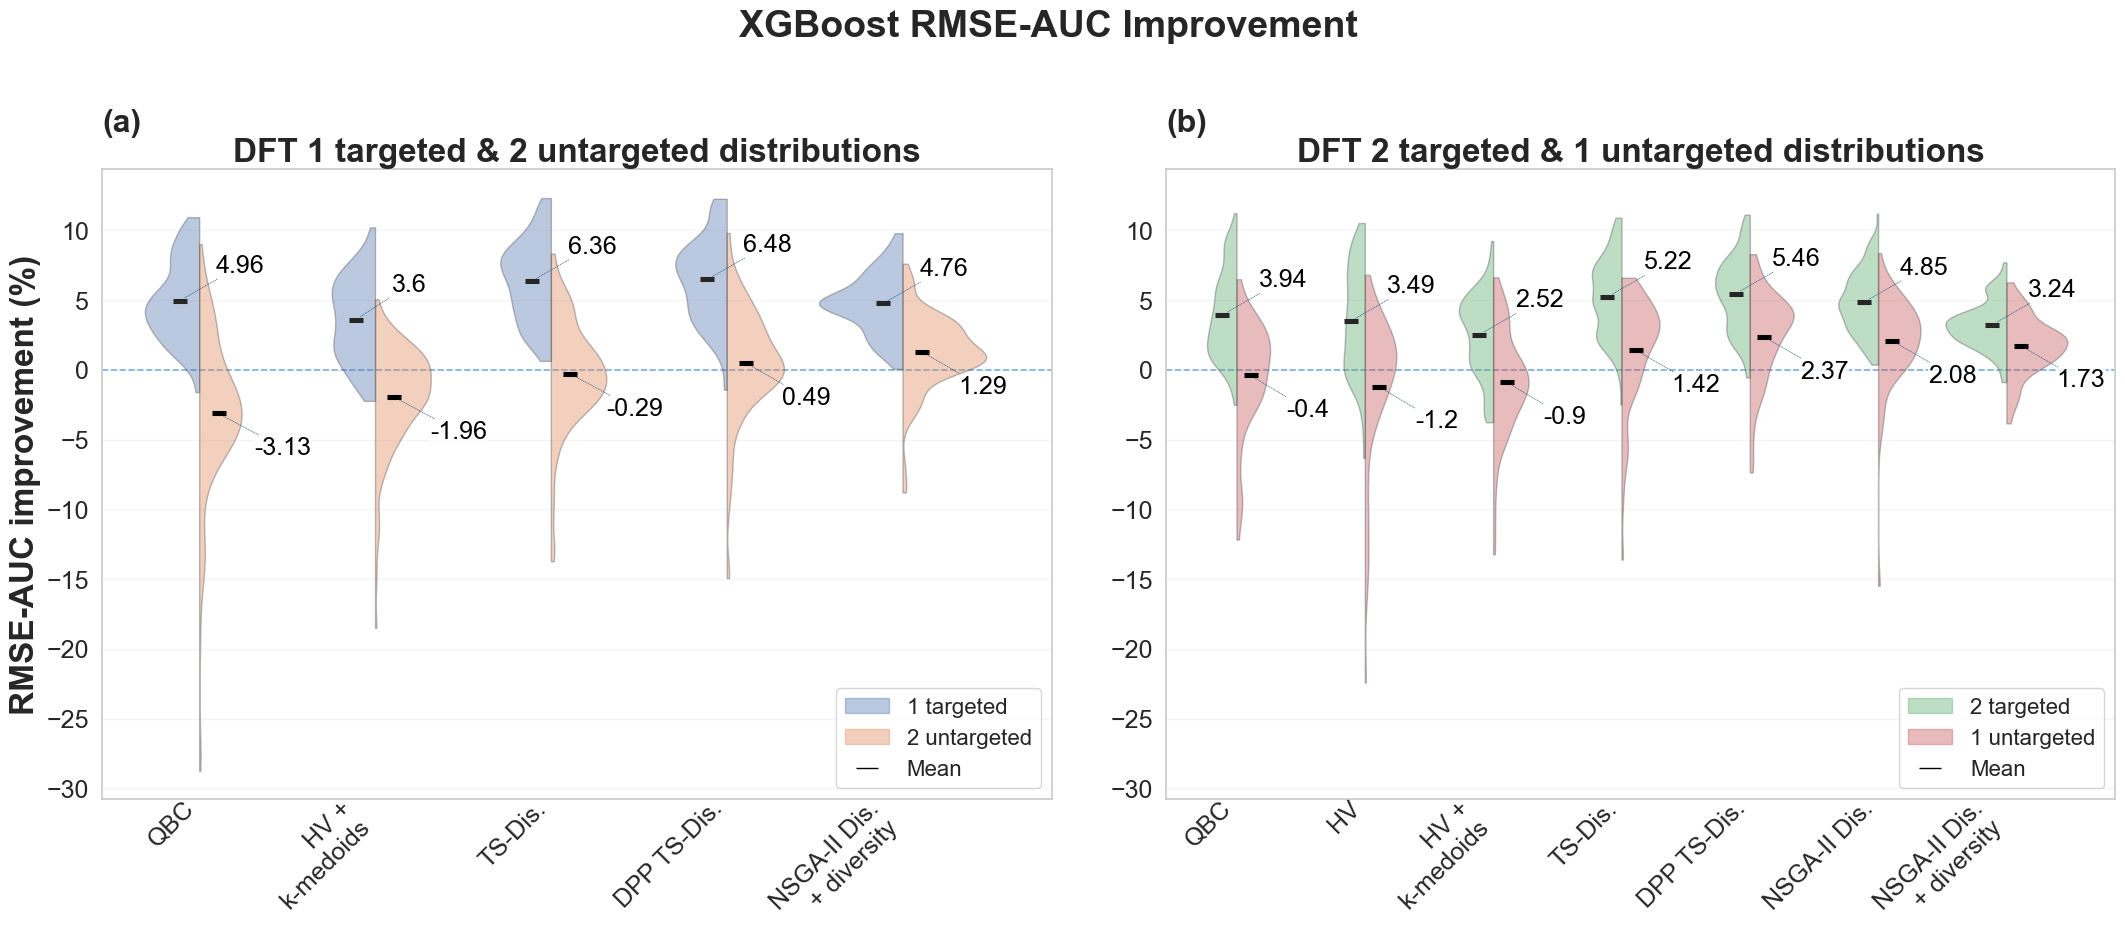


Saved figure: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_XGB_Joint_Representative_QBC_Case_UntargetedFirst\DFT_XGB_ALL_RAW_CASES_violin_only_ordered_untargeted.png
Saved violin plotting dataframe: C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_XGB_Joint_Representative_QBC_Case_UntargetedFirst\dft_xgb_violin_ALL_RAW_CASES_plot_data.csv


In [5]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
INPUT_ROOT = BASE_ROOT / "plots" / "rmse_auc_improvement_DFT"
OUTPUT_ROOT = BASE_ROOT / "plots" / "DFT_XGB_Joint_Representative_QBC_Case_UntargetedFirst"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURE = OUTPUT_ROOT / "DFT_XGB_ALL_RAW_CASES_violin_only_ordered_untargeted.png"
OUTPUT_SELECTED_CASE = OUTPUT_ROOT / "selected_joint_representative_qbc_case_untargeted_first.csv"
OUTPUT_CASE_SUMMARY = OUTPUT_ROOT / "joint_representative_qbc_case_summary_all_cases_untargeted_first.csv"
OUTPUT_TOP_PLOT_DATA = OUTPUT_ROOT / "dft_xgb_violin_ALL_RAW_CASES_plot_data.csv"
SEEDS = range(5)
MODEL = "xgb"
MODEL_DISPLAY = "XGBoost"
# =============================================================================
# DFT outcomes and case definitions
# =============================================================================
# Canonical property -> accepted raw RMSE column names.
# Some DFT runs save formation energy as rmse_eform, others as rmse_e_form.
RMSE_METRIC_ALIASES = {
    "e_form": ["rmse_eform", "rmse_e_form"],
    "bulk_modulus": ["rmse_bulk_modulus"],
    "bandgap": ["rmse_bandgap"],
}
PROPERTY_LABELS = {
    "e_form": "Formation energy",
    "bulk_modulus": "Bulk modulus",
    "bandgap": "Band gap",
}
PROPERTY_YLABELS = {
    "e_form": "RMSE [eV/atom]",
    "bulk_modulus": "RMSE [GPa]",
    "bandgap": "RMSE [eV]",
}
# For panel selection we index by canonical property name.
PROPERTY_TO_METRIC = {
    "e_form": "e_form",
    "bulk_modulus": "bulk_modulus",
    "bandgap": "bandgap",
}
ALL_PROPERTIES = ["e_form", "bulk_modulus", "bandgap"]
TARGET_CASES = {
    "e_form": {"e_form"},
    "bulk_modulus": {"bulk_modulus"},
    "bandgap": {"bandgap"},
    "eform_bulk_modulus": {"e_form", "bulk_modulus"},
    "bandgap_eform": {"bandgap", "e_form"},
    "bandgap_bulkmodulus": {"bandgap", "bulk_modulus"},
}
ONE_TARGET_CASES = {"e_form", "bulk_modulus", "bandgap"}
DATASET_ALIASES = {
    "mp18": ["mp18", "mp_18", "mp-18", "mp2018", "mp_2018", "mp-2018"],
    "mp21": ["mp21", "mp_21", "mp-21", "mp2021", "mp_2021", "mp-2021"],
    "jarvis18": ["jarvis18", "jarvis_18", "jarvis-18", "jarvis2018", "jarvis_2018", "jarvis-2018"],
    "jarvis22": ["jarvis22", "jarvis_22", "jarvis-22", "jarvis2022", "jarvis_2022", "jarvis-2022"],
}
# =============================================================================
# Policies and display configuration
# =============================================================================
# Original internal keys retain compatibility with existing filenames/data.
POLICY_ORDER = ['QBC', 'HV', 'HV + k-medoids', 'TS-QBC', 'DPP-TS-QBC', 'NSGA-II QBC', 'NSGA-II QBC + diversity']
ONE_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
TWO_TARGET_VIOLIN_POLICY_ORDER = POLICY_ORDER.copy()
ONE_TARGET_RMSE_POLICY_ORDER = POLICY_ORDER + ["Random"]
DISPLAY_POLICY_LABELS = {
    "QBC": "QBC",
    "HV + k-medoids": "HV +\nk-medoids",
    "TS-QBC": "TS-Dis.",
    "DPP-TS-QBC": "DPP TS-Dis.",
    "NSGA-II QBC": "NSGA-II Dis.",
    "NSGA-II QBC + diversity": "NSGA-II Dis.\n+ diversity",
    "HV": "HV",
    "Random": "Random",
}
CASE_COLORS = {
    "1 targeted": "#4c72b0",
    "2 untargeted": "#dd8452",
    "2 targeted": "#55a868",
    "1 untargeted": "#c44e52",
}
POLICY_COLORS = {
    "QBC": "tab:gray",
    "HV": "tab:orange",
    "HV + k-medoids": "tab:orange",
    "TS-QBC": "tab:green",
    "DPP-TS-QBC": "tab:green",
    "NSGA-II QBC": "tab:red",
    "NSGA-II QBC + diversity": "tab:red",
    "Random": "tab:blue",
}
POLICY_LINESTYLES = {
    "QBC": "-",
    "HV": "-",
    "HV + k-medoids": "dotted",
    "TS-QBC": "-",
    "DPP-TS-QBC": "dotted",
    "NSGA-II QBC": "-",
    "NSGA-II QBC + diversity": "dotted",
    "Random": "-",
}
# =============================================================================
# General helpers
# =============================================================================
def _norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())
def canonicalize_policy(value):
    if pd.isna(value):
        return np.nan
    raw = str(value).strip()
    key = _norm(raw)
    if "growdisagreementhvtopmkmedoids" in key or "hvkmedoids" in key:
        return "HV + k-medoids"
    if "growdisagreementhv" in key and "kmedoids" not in key:
        return "HV"
    if "dpptsqbc" in key:
        return "DPP-TS-QBC"
    if "tsqbc" in key and "dpptsqbc" not in key:
        return "TS-QBC"
    if "nsgaii" in key and "qbc" in key and "divers" in key:
        return "NSGA-II QBC + diversity"
    if (
        "groweadeltadiversity" in key
        or "growingeadeltadiversity" in key
        or (("growea" in key or "growingea" in key) and "divers" in key)
        or "groweaqbc1objwithdiversity" in key
        or "growingeaqbc1objwithdiversity" in key
        or "groweaqbc1objwithdiversityfrom3outcomes" in key
        or "growingeaqbc1objwithdiversityfrom3outcomes" in key
    ):
        return "NSGA-II QBC + diversity"
    if "nsgaii" in key and "qbc" in key:
        return "NSGA-II QBC"
    if (
        (("growea" in key or "growingea" in key) and "divers" not in key)
        or "groweaqbc1obj" in key
        or "growingeaqbc1obj" in key
        or "growingea2objqbconly" in key
    ):
        return "NSGA-II QBC"
    qbc_aliases = {
        "qbc", "1qbc", "2qbc", "3qbc",
        "growqbc", "growingqbc", "grow2qbc", "growing2qbc",
    }
    if key in qbc_aliases or "grow2qbc" in key:
        return "QBC"
    if "random" in key:
        return "Random"
    aliases = {
        "hv": "HV",
        "hvkmedoids": "HV + k-medoids",
        "nsgaiiqbc": "NSGA-II QBC",
        "nsgaiiqbcdiversity": "NSGA-II QBC + diversity",
        "tsqbc": "TS-QBC",
        "dpptsqbc": "DPP-TS-QBC",
    }
    return aliases.get(key, raw)
def identify_dataset(text):
    normalized = _norm(text)
    for dataset, aliases in DATASET_ALIASES.items():
        for alias in aliases:
            if _norm(alias) in normalized:
                return dataset
    return None
def identify_seed_and_model(path):
    path = Path(path)
    match = re.search(r"(?:_|-|\s)(rf|xgb)(\d*)\.csv$", path.name, flags=re.IGNORECASE)
    if not match:
        return None, None
    model = match.group(1).lower()
    digits = match.group(2)
    if digits != "":
        return model, int(digits)
    if path.parent.name.isdigit():
        return model, int(path.parent.name)
    for parent in path.parents:
        if parent.name.isdigit():
            return model, int(parent.name)
    return model, None
def identify_target_case(text):
    compact = _norm(text)
    ordered = [
        ("eform_bulk_modulus", ["eformbulkmodulus"]),
        ("bandgap_bulkmodulus", ["bandgapbulkmodulus"]),
        ("bandgap_eform", ["bandgapeform"]),
        ("bulk_modulus", ["bulkmodulus"]),
        ("bandgap", ["bandgap"]),
        ("e_form", ["eform"]),
    ]
    for target, aliases in ordered:
        if any(_norm(alias) in compact for alias in aliases):
            return target
    return None
def is_plain_qbc_file(path):
    path = Path(path)
    compact_name = _norm(path.name)
    compact_parts = {_norm(part) for part in path.parts}
    full_compact = _norm(str(path))
    if "dpptsqbc" in full_compact or "tsqbc" in full_compact or "nsgaii" in full_compact:
        return False
    if "grow2qbc" in compact_parts or "qbc" in compact_parts:
        return True
    if "grow2qbc" in compact_name or "growing2qbc" in compact_name:
        return True
    return re.search(
        r"(?:^|[_\-])qbc[_\-](?:rf|xgb)\d*\.csv$",
        path.name,
        flags=re.IGNORECASE,
    ) is not None
def load_curve(path):
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        return None
    df = df.copy()
    df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
    return df
def normalized_rmse_auc(df, metric):
    if df is None or metric not in df.columns:
        return None
    curve = (
        df[["train_percent", metric]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
        .groupby("train_percent", as_index=False)[metric]
        .mean()
        .sort_values("train_percent")
    )
    if len(curve) < 2:
        return None
    x = curve["train_percent"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    auc = np.trapezoid(y, x)
    return {"mean_rmse_auc": float(auc / width)}
def resolve_metric_column(df, canonical_property):
    """
    Return the first matching raw RMSE column for a canonical property.
    Example:
      canonical_property='e_form' -> rmse_eform or rmse_e_form
    """
    aliases = RMSE_METRIC_ALIASES.get(canonical_property, [])
    for col in aliases:
        if col in df.columns:
            return col
    return None
def normalized_rmse_auc_for_property(df, canonical_property):
    metric_col = resolve_metric_column(df, canonical_property)
    if metric_col is None:
        return None
    return normalized_rmse_auc(df, metric_col)
def find_matching_random(random_index, dataset, model, seed, target_case):
    if random_index.empty:
        return None
    candidates = random_index.loc[
        (random_index["dataset"] == dataset)
        & (random_index["model"] == model)
        & (random_index["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    exact = candidates.loc[candidates["target_case"] == target_case]
    if not exact.empty:
        return exact.iloc[0]["path"]
    all_case = candidates.loc[candidates["target_case"] == "all"]
    if not all_case.empty:
        return all_case.iloc[0]["path"]
    if len(candidates) == 1:
        return candidates.iloc[0]["path"]
    return candidates.iloc[0]["path"]
# =============================================================================
# Build TOP violin dataframe DIRECTLY from ALL raw DFT AL files
# =============================================================================
#
# No precomputed DFT_rmse_auc_improvement_by_seed_rf.csv is used for the
# violin panels.
#
# Every violin observation is calculated independently for one:
#
#     dataset x target_case x policy x seed x property
#
# using:
#
#     100 * (1 - policy_RMSE_AUC / random_RMSE_AUC)
#
# The top violin plots therefore aggregate ALL available raw DFT cases from:
#
#     datasets:
#         MP18, MP21, JARVIS18, JARVIS22
#
#     one-target campaigns:
#         e_form, bulk_modulus, bandgap
#
#     two-target campaigns:
#         eform_bulk_modulus, bandgap_eform, bandgap_bulkmodulus
#
#     seeds:
#         0, 1, 2, 3, 4
#
#     properties:
#         formation energy, bulk modulus, band gap
#
# Nothing is averaged before the observations are passed to seaborn.
# =============================================================================
def detect_all_raw_policy(path):
    """
    Detect acquisition policy for both one-target and two-target DFT raw files.
    """
    path = Path(path)
    full = _norm(str(path))
    name = _norm(path.name)
    stem = _norm(path.stem)
    if "random" in full:
        return "Random"
    # DPP-TS before TS/QBC.
    if "dpptsqbc" in full:
        return "DPP-TS-QBC"
    if "tsqbc" in full and "dpptsqbc" not in full:
        return "TS-QBC"
    # HV + k-medoids before plain HV.
    if (
        "growdisagreementhvtopmkmedoids" in full
        or "hvkmedoids" in full
    ):
        return "HV + k-medoids"
    if (
        "growdisagreementhv" in full
        and "kmedoids" not in full
    ):
        return "HV"
    # NSGA-II / EA with diversity.
    #
    # Handle both historical folder families:
    #     grow_EA_...
    #     growing_EA_...
    #
    # Normalization removes underscores, e.g.
    #     growing_EA_2obj_qbc_only -> growingea2objqbconly
    #
    # Diversity variants are classified first.
    if (
        "groweaqbc1objwithdiversityfrom3outcomes" in full
        or "growingeaqbc1objwithdiversityfrom3outcomes" in full
        or "groweaqbc1objwithdiversity" in full
        or "growingeaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or "growingeadeltadiversity" in full
        or (
            ("growea" in full or "growingea" in full)
            and "divers" in full
        )
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # NSGA-II / EA without diversity.
    #
    # Explicitly includes the actual two-target family:
    #     growing_EA_2obj_qbc_only
    if (
        "growingea2objqbconly" in full
        or "growea2objqbconly" in full
        or "groweaqbc1objfrom3outcomes" in full
        or "growingeaqbc1objfrom3outcomes" in full
        or "groweaqbc1obj" in full
        or "growingeaqbc1obj" in full
        or (
            ("growea" in full or "growingea" in full)
            and "divers" not in full
        )
        or ("nsgaii" in full and "divers" not in full)
        or stem.startswith("growea")
        or stem.startswith("growingea")
        or name.startswith("growea")
        or name.startswith("growingea")
    ):
        return "NSGA-II QBC"
    # Plain QBC, including 1-target QBC folders and grow2QBC families.
    if is_plain_qbc_file(path):
        return "QBC"
    fallback = canonicalize_policy(str(path))
    if fallback in {
        "QBC",
        "HV",
        "HV + k-medoids",
        "NSGA-II QBC",
        "NSGA-II QBC + diversity",
        "TS-QBC",
        "DPP-TS-QBC",
        "Random",
    }:
        return fallback
    return None
def discover_all_raw_dft_files():
    """
    Index every usable RF raw DFT AL CSV for the violin calculation.
    """
    if not DATA_ROOT.exists():
        raise FileNotFoundError(
            f"Raw AL folder does not exist:\n{DATA_ROOT}"
        )
    rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        dataset = identify_dataset(str(path))
        if dataset not in DATASET_ALIASES:
            continue
        policy = detect_all_raw_policy(path)
        if policy is None:
            continue
        target_case = identify_target_case(str(path))
        # Generic Random files often do not encode a target case.
        if policy == "Random":
            target_case_out = (
                target_case if target_case in TARGET_CASES else "all"
            )
        else:
            if target_case not in TARGET_CASES:
                continue
            target_case_out = target_case
        rows.append(
            {
                "dataset": dataset,
                "model": model,
                "seed": int(seed),
                "policy": policy,
                "target_case": target_case_out,
                "path": Path(path),
            }
        )
    index_df = pd.DataFrame(rows)
    if index_df.empty:
        raise RuntimeError(
            "No raw XGBoost DFT AL files were discovered."
        )
    # Prevent the exact same path from entering more than once.
    index_df = index_df.drop_duplicates(
        subset=["dataset", "model", "seed", "policy", "target_case", "path"]
    ).reset_index(drop=True)
    # Explicit diagnostic for NSGA-II file discovery.
    nsga_diag = index_df.loc[
        index_df["policy"].isin(
            ["NSGA-II QBC", "NSGA-II QBC + diversity"]
        )
    ].copy()
    print(
        "\n================ NSGA-II RAW FILE CHECK ================"
    )
    if nsga_diag.empty:
        print("WARNING: no NSGA-II raw files were detected.")
    else:
        print(
            nsga_diag[
                ["dataset", "policy", "target_case", "seed", "path"]
            ]
            .sort_values(
                ["dataset", "policy", "target_case", "seed"]
            )
            .to_string(index=False)
        )
    print(
        "\n================ ALL RAW DFT FILE INDEX ================"
    )
    print(
        index_df[
            ["dataset", "policy", "target_case", "seed", "path"]
        ]
        .sort_values(
            ["dataset", "policy", "target_case", "seed"]
        )
        .to_string(index=False)
    )
    return index_df
def find_matching_random_all_cases(
    index_df,
    dataset,
    seed,
    target_case,
):
    """
    Match Random by dataset and seed.
    Prefer a target-case-specific Random file when available, otherwise use
    the generic/all Random file.
    """
    candidates = index_df.loc[
        (index_df["policy"] == "Random")
        & (index_df["dataset"] == dataset)
        & (index_df["model"] == MODEL)
        & (index_df["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    exact = candidates.loc[
        candidates["target_case"] == target_case
    ]
    if not exact.empty:
        return exact.iloc[0]["path"]
    generic = candidates.loc[
        candidates["target_case"] == "all"
    ]
    if not generic.empty:
        return generic.iloc[0]["path"]
    return candidates.iloc[0]["path"]
def build_top_plot_dataframe():
    """
    Build ALL top-row violin observations directly from raw XGBoost DFT AL data.
    One dataframe row corresponds to one:
        dataset x target campaign x policy x seed x property
    raw RMSE-AUC improvement observation.
    """
    file_index = discover_all_raw_dft_files()
    policy_index = file_index.loc[
        file_index["policy"] != "Random"
    ].copy()
    rows = []
    for file_row in policy_index.itertuples(index=False):
        target_case = file_row.target_case
        if target_case not in TARGET_CASES:
            continue
        targeted_properties = TARGET_CASES[target_case]
        n_targets = len(targeted_properties)
        if n_targets not in {1, 2}:
            continue
        random_path = find_matching_random_all_cases(
            index_df=file_index,
            dataset=file_row.dataset,
            seed=file_row.seed,
            target_case=target_case,
        )
        if random_path is None:
            print(
                "WARNING: no matching Random raw file | "
                f"dataset={file_row.dataset}, "
                f"seed={file_row.seed}, "
                f"target_case={target_case}"
            )
            continue
        policy_df = load_curve(file_row.path)
        random_df = load_curve(random_path)
        if policy_df is None or random_df is None:
            continue
        for property_id, property_name in PROPERTY_LABELS.items():
            policy_auc = normalized_rmse_auc_for_property(
                policy_df,
                property_id,
            )
            random_auc = normalized_rmse_auc_for_property(
                random_df,
                property_id,
            )
            if policy_auc is None or random_auc is None:
                continue
            random_value = random_auc["mean_rmse_auc"]
            if np.isclose(
                random_value,
                0.0,
                atol=1e-15,
                rtol=0.0,
            ):
                print(
                    "WARNING: Random RMSE-AUC is zero; skipping | "
                    f"dataset={file_row.dataset}, "
                    f"policy={file_row.policy}, "
                    f"target_case={target_case}, "
                    f"seed={file_row.seed}, "
                    f"property={property_id}"
                )
                continue
            improvement = 100.0 * (
                1.0
                - policy_auc["mean_rmse_auc"]
                / random_value
            )
            case_type = (
                "targeted"
                if property_id in targeted_properties
                else "untargeted"
            )
            if n_targets == 1:
                axis_name = (
                    "1 targeted"
                    if case_type == "targeted"
                    else "2 untargeted"
                )
            else:
                axis_name = (
                    "2 targeted"
                    if case_type == "targeted"
                    else "1 untargeted"
                )
            rows.append(
                {
                    "dataset": file_row.dataset,
                    "model": MODEL,
                    "policy": file_row.policy,
                    "target_case": target_case,
                    "n_targets": n_targets,
                    "property": property_id,
                    "property_name": property_name,
                    "case_type": case_type,
                    "axis": axis_name,
                    "seed": int(file_row.seed),
                    "rmse_auc_improvement_percent": improvement,
                    "policy_rmse_auc":
                        policy_auc["mean_rmse_auc"],
                    "random_rmse_auc":
                        random_auc["mean_rmse_auc"],
                    "policy_file": str(file_row.path),
                    "random_file": str(random_path),
                }
            )
    plot_df = pd.DataFrame(rows)
    if plot_df.empty:
        raise RuntimeError(
            "No raw DFT RMSE-AUC improvement observations were built."
        )
    # Only requested acquisition policies.
    plot_df = plot_df.loc[
        plot_df["policy"].isin(POLICY_ORDER)
    ].copy()
    # --------------------------------------------------------------
    # Diagnostics: show exactly what enters each violin.
    # --------------------------------------------------------------
    print(
        "\n================ ALL RAW VIOLIN COUNTS ================"
    )
    counts = (
        plot_df.groupby(
            ["axis", "policy"],
            observed=True,
        )
        .size()
        .rename("n_raw_observations")
        .reset_index()
    )
    print(counts.to_string(index=False))
    print(
        "\n================ RAW COUNTS BY DATASET ================"
    )
    dataset_counts = (
        plot_df.groupby(
            ["axis", "policy", "dataset"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print(dataset_counts.to_string(index=False))
    print(
        "\n================ RAW COUNTS BY PROPERTY ================"
    )
    property_counts = (
        plot_df.groupby(
            ["axis", "policy", "property_name"],
            observed=True,
        )
        .size()
        .rename("n")
        .reset_index()
    )
    print(property_counts.to_string(index=False))
    print(
        "\nThe violin KDE receives these rows directly; "
        "no dataset/campaign/property averaging is performed beforehand."
    )
    return plot_df
# =============================================================================
# Selection:
# FIRST untargeted closeness, THEN targeted closeness.
# =============================================================================
def select_joint_representative_qbc_case_untargeted_first(plot_df):
    qbc_rows = plot_df.loc[
        (plot_df["policy"] == "QBC")
        & (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
    ].copy()
    if qbc_rows.empty:
        raise ValueError(
            "No 1-target QBC XGBoost rows were found. Cannot select the representative case."
        )
    targeted_case_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "targeted"]
        .groupby(["dataset", "target_case"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "targeted_mean_improvement_percent"})
    )
    untargeted_case_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "untargeted"]
        .groupby(["dataset", "target_case"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_mean_improvement_percent"})
    )
    case_summary = targeted_case_means.merge(
        untargeted_case_means,
        on=["dataset", "target_case"],
        how="inner",
    )
    if case_summary.empty:
        raise ValueError(
            "Could not build the case summary with targeted and untargeted means."
        )
    # Property-specific untargeted improvements for later display
    untargeted_property_means = (
        qbc_rows.loc[qbc_rows["case_type"] == "untargeted"]
        .groupby(["dataset", "target_case", "property"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_property_mean_improvement_percent"})
    )
    overall_targeted_mean = float(targeted_case_means["targeted_mean_improvement_percent"].mean())
    overall_untargeted_mean = float(untargeted_case_means["untargeted_mean_improvement_percent"].mean())
    case_summary["targeted_abs_diff_to_global_mean"] = np.abs(
        case_summary["targeted_mean_improvement_percent"] - overall_targeted_mean
    )
    case_summary["untargeted_abs_diff_to_global_mean"] = np.abs(
        case_summary["untargeted_mean_improvement_percent"] - overall_untargeted_mean
    )
    case_summary["targeted_property"] = case_summary["target_case"]
    case_summary["targeted_property_name"] = case_summary["targeted_property"].map(PROPERTY_LABELS)
    case_summary["overall_targeted_mean"] = overall_targeted_mean
    case_summary["overall_untargeted_mean"] = overall_untargeted_mean
    # FIRST untargeted closeness, THEN targeted closeness
    case_summary = case_summary.sort_values(
        [
            "untargeted_abs_diff_to_global_mean",
            "targeted_abs_diff_to_global_mean",
            "dataset",
            "target_case",
        ]
    ).reset_index(drop=True)
    selected = case_summary.iloc[0].to_dict()
    # Attach the two untargeted properties and their individual improvements
    selected_dataset = selected["dataset"]
    selected_target_case = selected["target_case"]
    untargeted_details = untargeted_property_means.loc[
        (untargeted_property_means["dataset"] == selected_dataset)
        & (untargeted_property_means["target_case"] == selected_target_case)
    ].sort_values("property")
    if len(untargeted_details) != 2:
        raise ValueError(
            f"Expected 2 untargeted properties for {selected_dataset} / {selected_target_case}, "
            f"found {len(untargeted_details)}."
        )
    untargeted_details = untargeted_details.reset_index(drop=True)
    selected["untargeted_property_1"] = untargeted_details.loc[0, "property"]
    selected["untargeted_property_1_name"] = PROPERTY_LABELS[untargeted_details.loc[0, "property"]]
    selected["untargeted_property_1_mean_improvement_percent"] = untargeted_details.loc[
        0, "untargeted_property_mean_improvement_percent"
    ]
    selected["untargeted_property_2"] = untargeted_details.loc[1, "property"]
    selected["untargeted_property_2_name"] = PROPERTY_LABELS[untargeted_details.loc[1, "property"]]
    selected["untargeted_property_2_mean_improvement_percent"] = untargeted_details.loc[
        1, "untargeted_property_mean_improvement_percent"
    ]
    case_summary.to_csv(OUTPUT_CASE_SUMMARY, index=False)
    pd.DataFrame([selected]).to_csv(OUTPUT_SELECTED_CASE, index=False)
    print("\nSelected representative 1-target QBC case (untargeted first, then targeted):")
    print(pd.DataFrame([selected]).to_string(index=False))
    return selected, case_summary
# =============================================================================
# Raw file discovery for one-target RMSE curves
# =============================================================================
def detect_raw_policy(path):
    """
    Raw-policy detector for one-target DFT curves.
    This version explicitly matches the full family of one-target file patterns,
    including folder names, for example:
      - grow_EA_QBC_1Obj
      - grow_EA_QBC_1Obj_from3Outcomes
      - grow_EA_QBC_1Obj_withDiversity
      - grow_EA_QBC_1Obj_withDiversity_from3Outcomes
    """
    full = _norm(str(path))
    name = _norm(Path(path).name)
    stem = _norm(Path(path).stem)
    if "random" in full:
        return "Random"
    # HV variants
    if (
        "growdisagreementhvtopmkmedoidsonetarget" in full
        or "growdisagreementhvtopmkmedoids" in full
    ):
        return "HV + k-medoids"
    if (
        "growdisagreementhvonetarget" in full
        or "growdisagreementhvnodiversityonetarget" in full
        or ("growdisagreementhv" in full and "kmedoids" not in full)
    ):
        return "HV"
    # Thompson-sampling variants
    if (
        "growdpptsqbconetarget" in full
        or "dpptsqbc" in full
    ):
        return "DPP-TS-QBC"
    if (
        "growtsqbcnodiversityonetarget" in full
        or ("tsqbc" in full and "dpptsqbc" not in full)
    ):
        return "TS-QBC"
    # NSGA-II / EA variants: diversity first
    if (
        "groweaqbc1objwithdiversityfrom3outcomes" in full
        or "growingeaqbc1objwithdiversityfrom3outcomes" in full
        or "groweaqbc1objwithdiversity" in full
        or "growingeaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or "growingeadeltadiversity" in full
        or (
            ("growea" in full or "growingea" in full)
            and ("withdiversity" in full or "divers" in full)
        )
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # NSGA-II / EA without diversity
    if (
        "groweaqbc1objfrom3outcomes" in full
        or "growingeaqbc1objfrom3outcomes" in full
        or "groweaqbc1obj" in full
        or "growingeaqbc1obj" in full
        or "growingea2objqbconly" in full
        or (
            ("growea" in full or "growingea" in full)
            and "withdiversity" not in full
            and "divers" not in full
        )
        or "nsgaiiqbc" in full
        or ("nsgaii" in full and "divers" not in full)
        or stem.startswith("growea")
        or stem.startswith("growingea")
        or name.startswith("growea")
        or name.startswith("growingea")
    ):
        return "NSGA-II QBC"
    # Plain QBC
    if is_plain_qbc_file(path):
        return "QBC"
    # Final fallback: canonicalize the path string itself.
    fallback = canonicalize_policy(str(path))
    if fallback in {
        "QBC",
        "HV",
        "HV + k-medoids",
        "NSGA-II QBC",
        "NSGA-II QBC + diversity",
        "TS-QBC",
        "DPP-TS-QBC",
        "Random",
    }:
        return fallback
    return None
def discover_one_target_raw_indices():
    if not DATA_ROOT.exists():
        raise FileNotFoundError(f"Missing raw AL folder:\n{DATA_ROOT}")
    policy_rows = []
    random_rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        dataset = identify_dataset(str(path))
        if dataset is None:
            continue
        target_case = identify_target_case(str(path))
        policy = detect_raw_policy(path)
        if policy is None:
            continue
        if policy == "Random":
            random_rows.append({
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "target_case": target_case if target_case is not None else "all",
                "path": path,
            })
        else:
            if target_case not in ONE_TARGET_CASES:
                continue
            policy_rows.append({
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "target_case": target_case,
                "policy": policy,
                "path": path,
            })
    policy_index = pd.DataFrame(policy_rows)
    random_index = pd.DataFrame(random_rows)
    if policy_index.empty:
        raise ValueError("No one-target raw policy files were discovered.")
    return policy_index, random_index
def load_selected_case_rmse_data(selected_dataset, selected_target_case):
    policy_index, random_index = discover_one_target_raw_indices()
    data = {}
    for policy in ONE_TARGET_RMSE_POLICY_ORDER:
        frames = []
        if policy == "Random":
            for seed in SEEDS:
                random_path = find_matching_random(
                    random_index,
                    dataset=selected_dataset,
                    model=MODEL,
                    seed=seed,
                    target_case=selected_target_case,
                )
                if random_path is None:
                    continue
                df = pd.read_csv(random_path)
                if "train_ratio" not in df.columns:
                    continue
                df = df.copy()
                df["seed"] = seed
                df["policy"] = policy
                df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
                frames.append(df)
        else:
            subset = policy_index.loc[
                (policy_index["dataset"] == selected_dataset)
                & (policy_index["model"] == MODEL)
                & (policy_index["target_case"] == selected_target_case)
                & (policy_index["policy"] == policy)
            ].copy()
            if not subset.empty:
                subset = subset.sort_values("seed").drop_duplicates(
                    subset=["seed"], keep="first"
                )
            for row in subset.itertuples(index=False):
                df = pd.read_csv(row.path)
                if "train_ratio" not in df.columns:
                    continue
                df = df.copy()
                df["seed"] = row.seed
                df["policy"] = policy
                df["train_percent"] = 100.0 * pd.to_numeric(df["train_ratio"], errors="coerce")
                frames.append(df)
        if frames:
            data[policy] = pd.concat(frames, ignore_index=True)
    if not data:
        raise ValueError(
            f"No RMSE raw curves were loaded for dataset={selected_dataset}, "
            f"target_case={selected_target_case}."
        )
    print(f"\nLoaded RMSE policies for dataset={selected_dataset}, target_case={selected_target_case}:")
    print(sorted(data.keys()))
    # Extra diagnostic for all important policy families
    subset_diag = policy_index.loc[
        (policy_index["dataset"] == selected_dataset)
        & (policy_index["model"] == MODEL)
        & (policy_index["target_case"] == selected_target_case)
        & (policy_index["policy"].isin([
            "HV", "HV + k-medoids",
            "NSGA-II QBC", "NSGA-II QBC + diversity",
            "TS-QBC", "DPP-TS-QBC", "QBC"
        ]))
    ].copy()
    if not subset_diag.empty:
        print("\nMatched raw files for selected case:")
        print(subset_diag[["policy", "seed", "path"]].sort_values(["policy", "seed"]).to_string(index=False))
    else:
        print("\nNo raw policy files were matched for the selected case.")
    return data
def summarize_curve(df, metric):
    per_seed = (
        df.groupby(["seed", "train_percent"], as_index=False)[metric]
        .mean()
    )
    return (
        per_seed.groupby("train_percent")[metric]
        .agg(mean="mean", std="std")
        .reset_index()
        .sort_values("train_percent")
    )
# =============================================================================
# Plotting helpers
# =============================================================================
def plot_violin_panel(ax, panel_df, policy_order, case_order, title, show_ylabel):
    palette = {case_name: CASE_COLORS[case_name] for case_name in case_order}
    if not panel_df.empty:
        sns.violinplot(
            data=panel_df,
            x="policy",
            y="rmse_auc_improvement_percent",
            hue="axis",
            order=policy_order,
            hue_order=case_order,
            palette=palette,
            split=True,
            width=0.95,
            inner=None,
            cut=0,
            bw_adjust=0.8,
            gridsize=250,
            linewidth=1.0,
            saturation=1.0,
            ax=ax,
        )
        for collection in ax.collections:
            try:
                collection.set_alpha(0.38)
            except Exception:
                pass
        sns.pointplot(
            data=panel_df,
            x="policy",
            y="rmse_auc_improvement_percent",
            hue="axis",
            order=policy_order,
            hue_order=case_order,
            estimator=np.mean,
            errorbar=None,
            join=False,
            dodge=0.22,
            markers="_",
            linestyles="none",
            color="black",
            scale=1.8,
            ax=ax,
            legend=False,
            zorder=6,
        )
        # Short leader lines point from each mean marker to its value.
        for hue_index, case_name in enumerate(case_order):
            means = (panel_df.loc[panel_df["axis"] == case_name]
                     .groupby("policy")["rmse_auc_improvement_percent"].mean())
            offset = -0.11 if hue_index == 0 else 0.11  # pointplot dodge=0.22
            vertical_offset = 25 if hue_index == 0 else -25
            for i, policy in enumerate(policy_order):
                if policy not in means.index or not np.isfinite(means[policy]):
                    continue
                value = float(means[policy])
                label = f"{value:.2f}".rstrip("0").rstrip(".")
                ax.annotate(
                    label, xy=(i + offset, value), xytext=(26, vertical_offset),
                    textcoords="offset points", ha="left", va="center",
                    fontsize=18, fontweight="normal", color="black", zorder=8,
                    arrowprops=dict(arrowstyle="-", color="#24527a",linestyle=":",
                                    linewidth=.5, shrinkA=2, shrinkB=4),
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=0.4),
                )
        ax.set_xlim(-0.55, len(policy_order) - 0.15)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.axhline(0.0, linestyle="--", linewidth=1.2, color="#5b9bd5", alpha=0.85, zorder=0)
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("RMSE-AUC improvement (%)" if show_ylabel else "", fontsize=24, fontweight="bold")
    ax.grid(axis="y", alpha=0.20)
    ax.set_xticks(np.arange(len(policy_order)))
    ax.set_xticklabels(
        [DISPLAY_POLICY_LABELS[p] for p in policy_order],
        fontsize=18,
        rotation=45,
        ha="right",
    )
    ax.tick_params(axis="x", labelsize=18, pad=-8)
    ax.tick_params(axis="y", labelsize=18)
    legend_handles = [
        Patch(facecolor=CASE_COLORS[case_order[0]], edgecolor=CASE_COLORS[case_order[0]], alpha=0.38, label=case_order[0]),
        Patch(facecolor=CASE_COLORS[case_order[1]], edgecolor=CASE_COLORS[case_order[1]], alpha=0.38, label=case_order[1]),
        Line2D([0], [0], color="black", marker="_", markersize=16, linestyle="none", label="Mean"),
    ]
    ax.legend(handles=legend_handles, loc="best" if show_ylabel else "lower right",
              fontsize=16, frameon=True, title=None)
def plot_rmse_panel(ax, data, metric, title, ylabel, label_text, ylabelpad=4):
    """
    metric is the canonical property key: e_form, bulk_modulus, or bandgap.
    """
    legend_handles = {}
    summary_by_label = {}
    # Draw-order priority. NSGA-II curves are intentionally drawn above the
    # other acquisition policies because several DFT learning curves can be
    # nearly identical and otherwise one curve may hide another completely.
    POLICY_ZORDER = {
        "Random": 3.0,
        "QBC": 3.2,
        "HV": 3.3,
        "HV + k-medoids": 3.4,
        "TS-QBC": 3.5,
        "DPP-TS-QBC": 3.6,
        "NSGA-II QBC": 5.0,
        "NSGA-II QBC + diversity": 5.2,
    }
    print(f"\n--- Plotting {title} (canonical property = {metric}) ---")
    for label in ONE_TARGET_RMSE_POLICY_ORDER:
        if label not in data:
            print(f"{label}: no dataframe loaded")
            continue
        df = data[label]
        metric_col = resolve_metric_column(df, metric)
        # Explicit diagnostic: formation energy may appear either as rmse_eform
        # or rmse_e_form depending on the run family.
        if metric_col is None:
            print(
                f"{label}: canonical metric '{metric}' NOT FOUND. "
                f"Available RMSE columns = "
                f"{[c for c in df.columns if str(c).lower().startswith('rmse')]}"
            )
            continue
        metric_values = pd.to_numeric(df[metric_col], errors="coerce")
        n_finite = int(np.isfinite(metric_values.to_numpy(dtype=float)).sum())
        if n_finite == 0:
            print(f"{label}: '{metric}' exists but has no finite values")
            continue
        stats = summarize_curve(df, metric_col)
        if stats.empty:
            print(f"{label}: '{metric_col}' produced an empty summary")
            continue
        summary_by_label[label] = stats
        x = stats["train_percent"].to_numpy(dtype=float)
        mean = stats["mean"].to_numpy(dtype=float)
        std = stats["std"].fillna(0.0).to_numpy(dtype=float)
        print(
            f"{label}: plotting {len(stats)} checkpoints; "
            f"mean range = [{np.nanmin(mean):.6g}, {np.nanmax(mean):.6g}]"
        )
        color = POLICY_COLORS[label]
        linestyle = POLICY_LINESTYLES[label]
        zorder = POLICY_ZORDER.get(label, 3.0)
        # Make NSGA-II visibly distinguishable if curves overlap strongly.
        if label == "NSGA-II QBC":
            linewidth = 2.8
            marker = "o"
            markersize = 3.0
            markevery = max(1, len(x) // 12)
        elif label == "NSGA-II QBC + diversity":
            linewidth = 2.8
            marker = None
            markersize = None
            markevery = None
        elif label == "Random":
            linewidth = 2.8
            marker = None
            markersize = None
            markevery = None
        else:
            linewidth = 2.0
            marker = None
            markersize = None
            markevery = None
        line = ax.plot(
            x,
            mean,
            label=label,
            color=color,
            linewidth=linewidth,
            linestyle=linestyle,
            marker=marker,
            markersize=markersize,
            markevery=markevery,
            zorder=zorder,
        )[0]
        lower = (mean - std).astype(float)
        upper = (mean + std).astype(float)
        lower[lower <= 0] = np.nan
        ax.fill_between(
            x,
            lower,
            upper,
            color=color,
            alpha=0.08,
            linewidth=0,
            zorder=1,
        )
        legend_handles[label] = line
    ax.set_title(title, fontsize=24, fontweight="bold")
    ax.set_xlabel("Training data (%)", fontsize=20, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=20, fontweight="bold", labelpad=ylabelpad)
    # Keep each y-label close to its own axis to avoid overlap across panels.
    if metric == "bulk_modulus":
        ax.yaxis.set_label_coords(-0.12, 0.5)
    elif metric == "bandgap":
        # Move farther left so the RMSE label does not overlap tick numbers.
        ax.yaxis.set_label_coords(-0.16, 0.5)
    elif metric == "e_form":
        # Move farther left so the RMSE label does not overlap tick numbers.
        ax.yaxis.set_label_coords(-0.16, 0.5)
    ax.set_xscale("log", base=16)
    ax.set_yscale("log", base=2)
    formatter = ScalarFormatter()
    formatter.set_scientific(False)
    formatter.set_useOffset(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xticks([5, 10, 20, 50, 100])
    ax.set_xticklabels(["5", "10", "20", "50", "100"])
    ax.set_xlim(5, 100)
    ax.tick_params(axis="both", labelsize=18)
    ax.grid(which="major", alpha=0.30)
    ax.grid(which="minor", alpha=0.10)
    # Tight y-limits and exactly 3 evenly spaced values on the log2 axis.
    # Geometric spacing gives equal visual spacing on a logarithmic axis.
    positive_values = []
    for stats_df in summary_by_label.values():
        vals = stats_df["mean"].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals) & (vals > 0)]
        if len(vals):
            positive_values.extend(vals.tolist())
    if positive_values:
        y_min = float(np.min(positive_values))
        y_max = float(np.max(positive_values))
        if y_min > 0 and y_max > y_min:
            # Small padding only, so the first panel does not waste vertical space.
            log2_min = np.log2(y_min)
            log2_max = np.log2(y_max)
            log2_span = log2_max - log2_min
            pad = 0.05 * log2_span
            lower = 2 ** (log2_min - pad)
            upper = 2 ** (log2_max + pad)
            # Requested fixed top y-values for each second-row panel.
            if metric == "bulk_modulus":
                upper = 35.0
                # Keep the lower end near the data minimum while respecting the
                # log scale and preserving visible variation.
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            elif metric == "bandgap":
                upper = 0.9
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            elif metric == "e_form":
                upper = 0.48
                lower = min(lower, float(np.min(positive_values)))
                if lower >= upper:
                    lower = upper / (2 ** 0.4)
            ax.set_ylim(lower, upper)
            tick_logs = np.linspace(np.log2(lower), np.log2(upper), 3)
            yticks = 2 ** tick_logs
            ax.set_yticks(yticks)
            tick_labels = []
            for t in yticks:
                if t >= 10:
                    tick_labels.append(f"{t:.1f}")
                elif t >= 1:
                    tick_labels.append(f"{t:.2f}")
                else:
                    tick_labels.append(f"{t:.3f}")
            ax.set_yticklabels(tick_labels)
    ax.text(
        0.96,
        0.94,
        label_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=18,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.4", alpha=0.90),
        zorder=10,
    )
    return legend_handles
# =============================================================================
# Main figure
# =============================================================================
def build_selected_case_policy_summary(plot_df, selection):
    """
    Print a compact summary for all policies in the selected 1-target case:
    - targeted improvement
    - mean untargeted improvement
    - band gap untargeted improvement
    - formation energy untargeted improvement
    """
    selected_dataset = selection["dataset"]
    selected_target_case = selection["target_case"]
    subset = plot_df.loc[
        (plot_df["dataset"] == selected_dataset)
        & (plot_df["target_case"] == selected_target_case)
        & (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
    ].copy()
    if subset.empty:
        print("\nNo policy information available for the selected case.")
        return pd.DataFrame()
    targeted_summary = (
        subset.loc[subset["case_type"] == "targeted"]
        .groupby("policy", as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "targeted_improvement_percent"})
    )
    untargeted_mean_summary = (
        subset.loc[subset["case_type"] == "untargeted"]
        .groupby("policy", as_index=False)["rmse_auc_improvement_percent"]
        .mean()
        .rename(columns={"rmse_auc_improvement_percent": "untargeted_mean_improvement_percent"})
    )
    untargeted_property_summary = (
        subset.loc[subset["case_type"] == "untargeted"]
        .groupby(["policy", "property"], as_index=False)["rmse_auc_improvement_percent"]
        .mean()
    )
    wide = untargeted_property_summary.pivot(
        index="policy",
        columns="property",
        values="rmse_auc_improvement_percent"
    ).reset_index()
    if "bandgap" in wide.columns:
        wide = wide.rename(columns={"bandgap": "bandgap_improvement_percent"})
    if "e_form" in wide.columns:
        wide = wide.rename(columns={"e_form": "formation_energy_improvement_percent"})
    if "bulk_modulus" in wide.columns:
        wide = wide.rename(columns={"bulk_modulus": "bulk_modulus_improvement_percent"})
    summary = targeted_summary.merge(untargeted_mean_summary, on="policy", how="outer")
    summary = summary.merge(wide, on="policy", how="outer")
    ordered_policies_present = [p for p in ONE_TARGET_RMSE_POLICY_ORDER if p in summary["policy"].tolist()]
    summary["policy"] = pd.Categorical(summary["policy"], categories=ordered_policies_present, ordered=True)
    summary = summary.sort_values("policy").reset_index(drop=True)
    print("\nSelected-case RMSE-AUC improvement summary for ALL policies:")
    print(f"Dataset = {selected_dataset}, target_case = {selected_target_case}")
    print(summary.to_string(index=False))
    return summary
def order_by_untargeted_mean(panel_df, allowed_policies):
    """Sort plotted policies by the mean of all raw untargeted observations."""
    means = (panel_df.loc[panel_df["case_type"] == "untargeted"]
             .groupby("policy")["rmse_auc_improvement_percent"].mean())
    ordered = sorted(
        [p for p in allowed_policies if p in panel_df["policy"].values],
        key=lambda p: (means.get(p, float("inf")), p),
    )
    print("\nUntargeted means, left to right:")
    for policy in ordered:
        print(f"  {policy}: {means.get(policy, float('nan')):.2f}%")
    return ordered
def make_figure(plot_df, output_path):
    sns.set_theme(style="whitegrid")
    fig, (ax_violin_1, ax_violin_2) = plt.subplots(1, 2, figsize=(22, 10))
    panel_1_df = plot_df.loc[
        (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 1)
        & (plot_df["policy"].isin(ONE_TARGET_VIOLIN_POLICY_ORDER))
    ].copy()
    order_1 = [p for p in ONE_TARGET_VIOLIN_POLICY_ORDER if p in panel_1_df["policy"].values]
    plot_violin_panel(
        ax=ax_violin_1, panel_df=panel_1_df, policy_order=order_1,
        case_order=["1 targeted", "2 untargeted"],
        title="DFT 1 targeted & 2 untargeted distributions", show_ylabel=True,
    )
    panel_2_df = plot_df.loc[
        (pd.to_numeric(plot_df["n_targets"], errors="coerce") == 2)
        & (plot_df["policy"].isin(TWO_TARGET_VIOLIN_POLICY_ORDER))
    ].copy()
    order_2 = [p for p in TWO_TARGET_VIOLIN_POLICY_ORDER if p in panel_2_df["policy"].values]
    plot_violin_panel(
        ax=ax_violin_2, panel_df=panel_2_df, policy_order=order_2,
        case_order=["2 targeted", "1 untargeted"],
        title="DFT 2 targeted & 1 untargeted distributions", show_ylabel=False,
    )
    # Match the right panel's y-axis range and tick values to the left panel.
    y_min, y_max = ax_violin_1.get_ylim()
    five_unit_ticks = np.arange(np.ceil(y_min / 5) * 5, y_max + 1e-9, 5)
    ax_violin_1.set_yticks(five_unit_ticks)
    ax_violin_2.set_ylim(y_min, y_max)
    ax_violin_2.set_yticks(five_unit_ticks)
    ax_violin_2.tick_params(axis="y", labelleft=True)
    for ax, label in [(ax_violin_1, "(a)"), (ax_violin_2, "(b)")]:
        ax.text(0.0, 1.05, label, transform=ax.transAxes,
                fontsize=23, fontweight="bold", va="bottom", ha="left")
    fig.suptitle("XGBoost RMSE-AUC Improvement", fontsize=27, fontweight="bold", y=0.99)
    fig.subplots_adjust(left=0.07, right=0.985, top=0.83, bottom=0.20, wspace=0.12)
    fig.savefig(output_path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("\nSaved figure:", output_path)
def main():
    plot_df = build_top_plot_dataframe()
    plot_df.to_csv(OUTPUT_TOP_PLOT_DATA, index=False)
    make_figure(plot_df=plot_df, output_path=OUTPUT_FIGURE)
    print("Saved violin plotting dataframe:", OUTPUT_TOP_PLOT_DATA)
if __name__ == "__main__":
    main()



PROCESSING MP21 — Random Forest

================ DISCOVERED MP21 RF FILES ================
                 policy         target_case  seed                                                                                                                                                                                                                                                                                                  path
             DPP-TS-QBC             bandgap     0                                                              C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\grow_DPP_TS_QBC_OneTarget\mp21\bandgap\0\mp21_bandgapgrow_DPP_TS_QBC_OneTarget_rf0.csv
             DPP-TS-QBC             bandgap     1                                                              C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsit

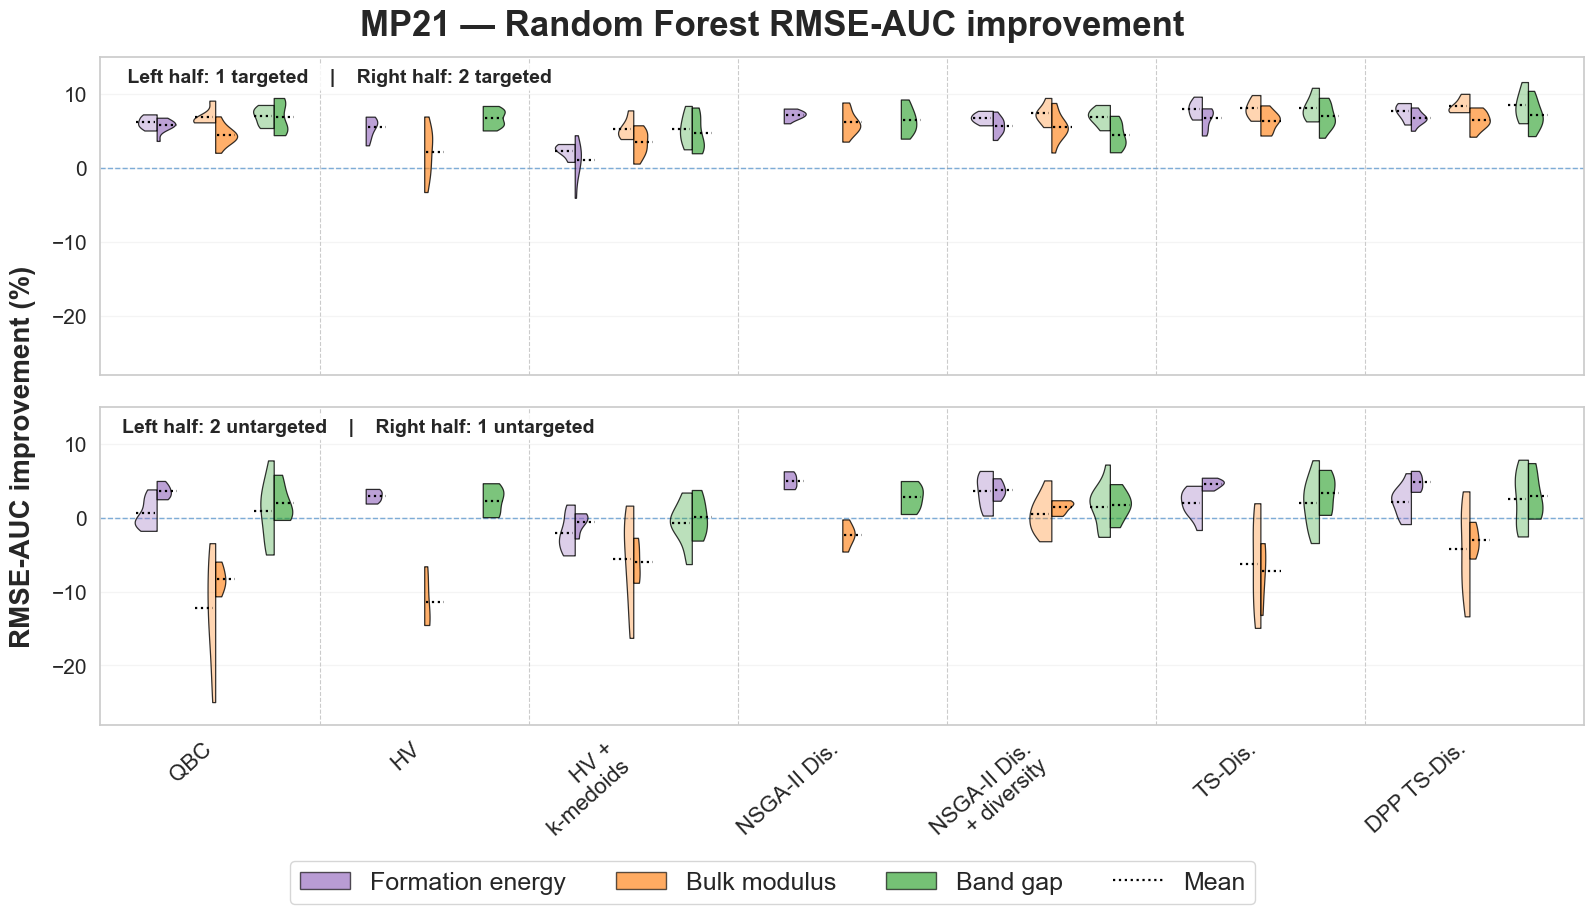


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_RF_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT MP21 Random Forest per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_RF_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT MP21 Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_RF_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING MP21 — XGBoost

================ DISCOVERED MP21 XGB FILES ================
                 policy 

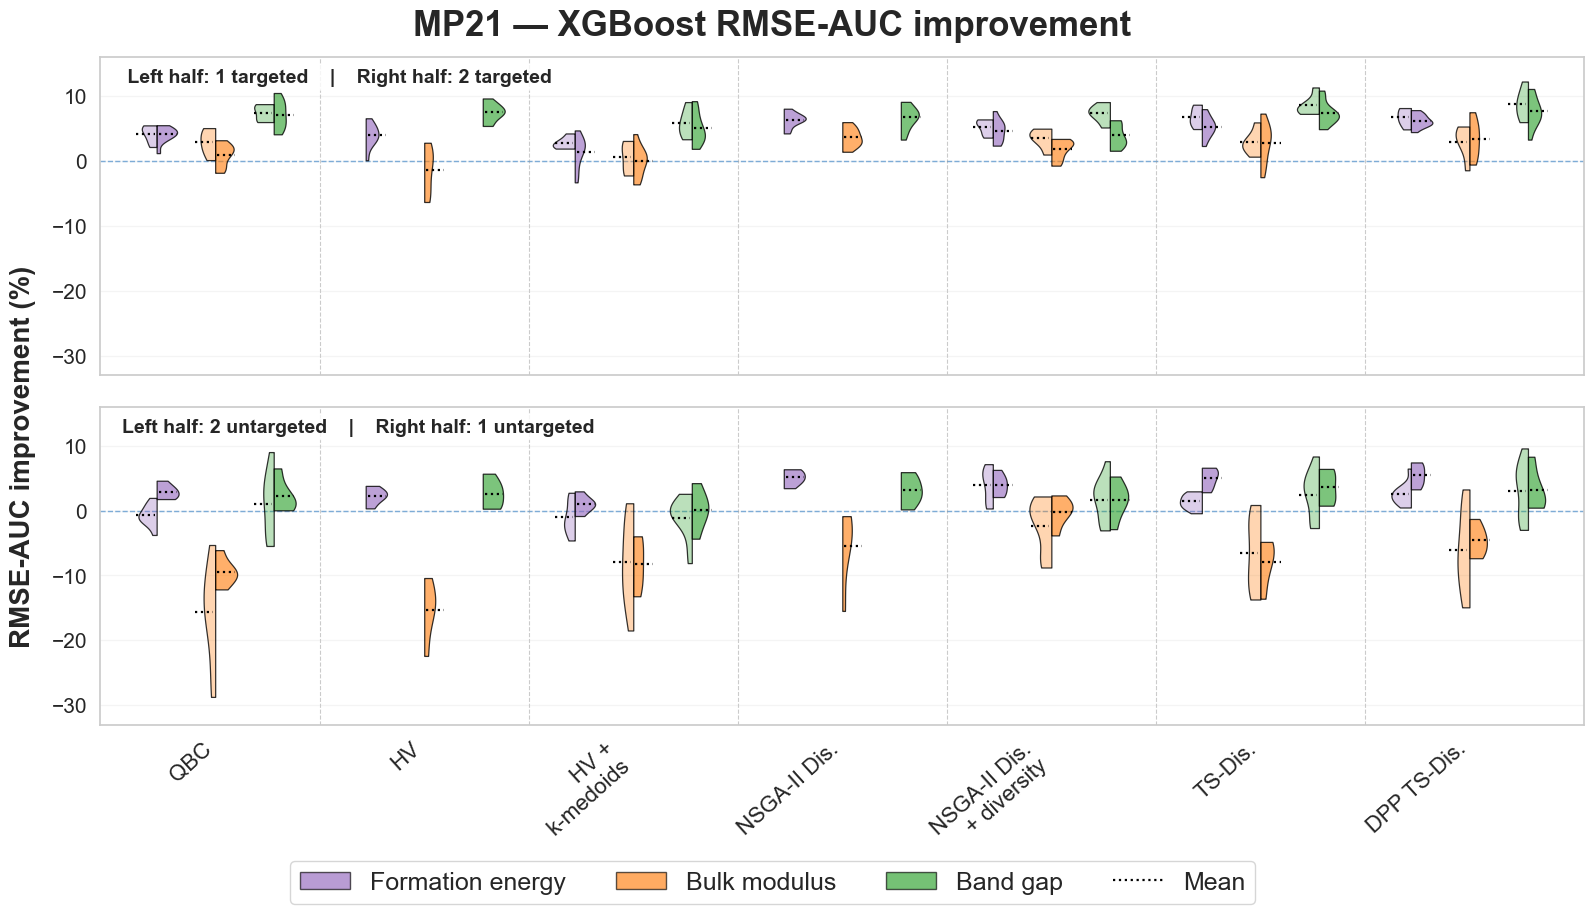


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_XGB_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT MP21 XGBoost per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_XGB_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT MP21 XGBoost mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP21\MP21_XGB_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING MP18 — Random Forest

================ DISCOVERED MP18 RF FILES ================
                 policy     

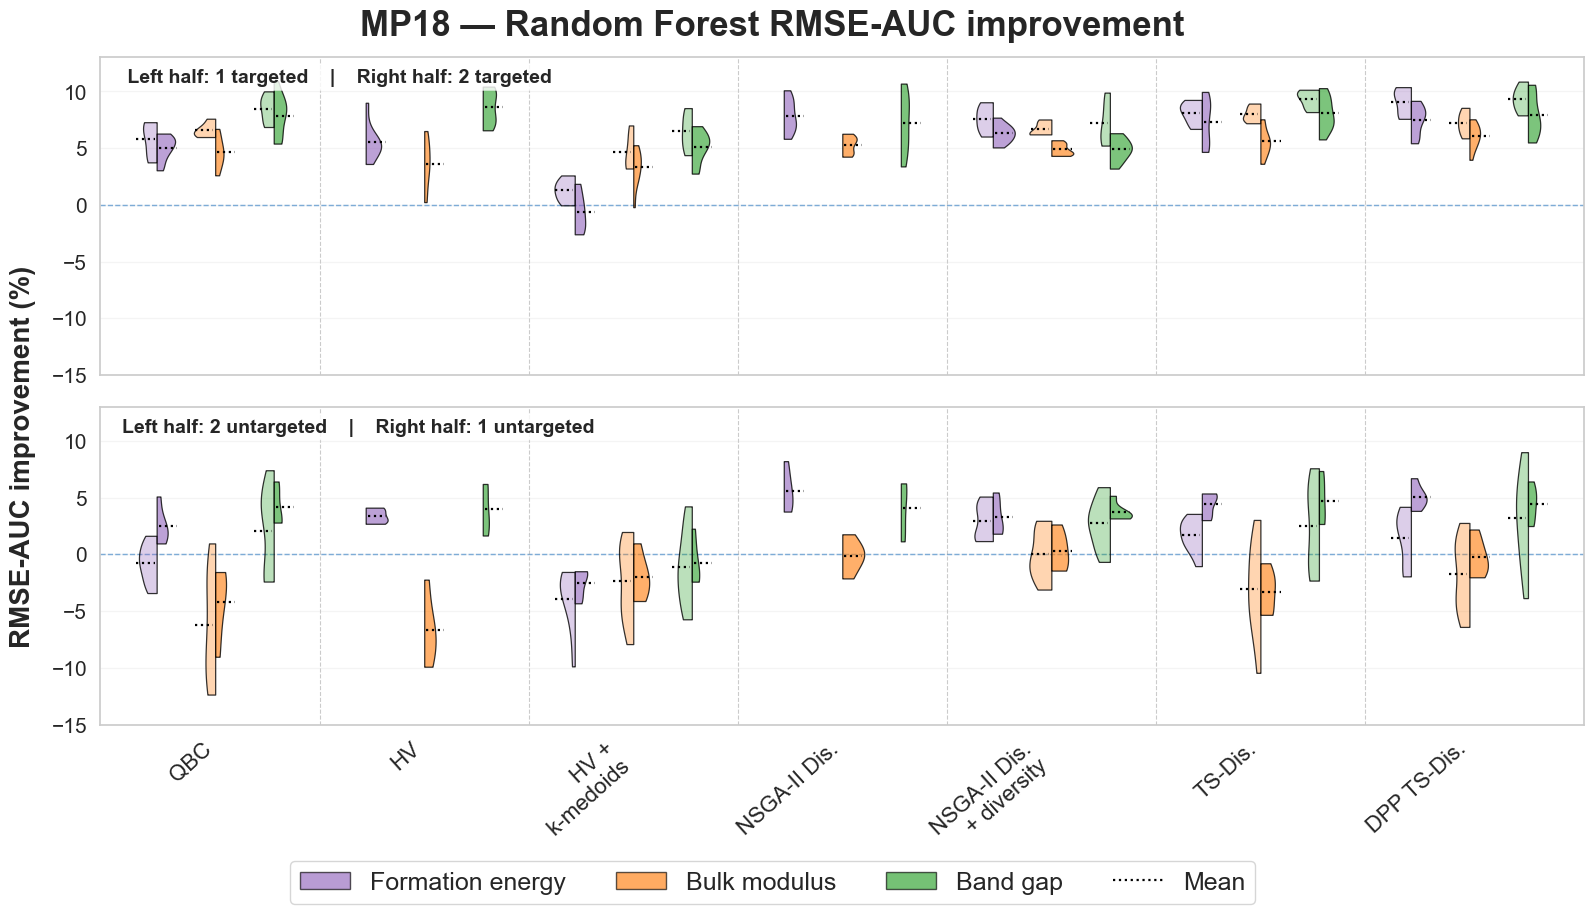


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_RF_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT MP18 Random Forest per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_RF_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT MP18 Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_RF_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING MP18 — XGBoost

================ DISCOVERED MP18 XGB FILES ================
                 policy 

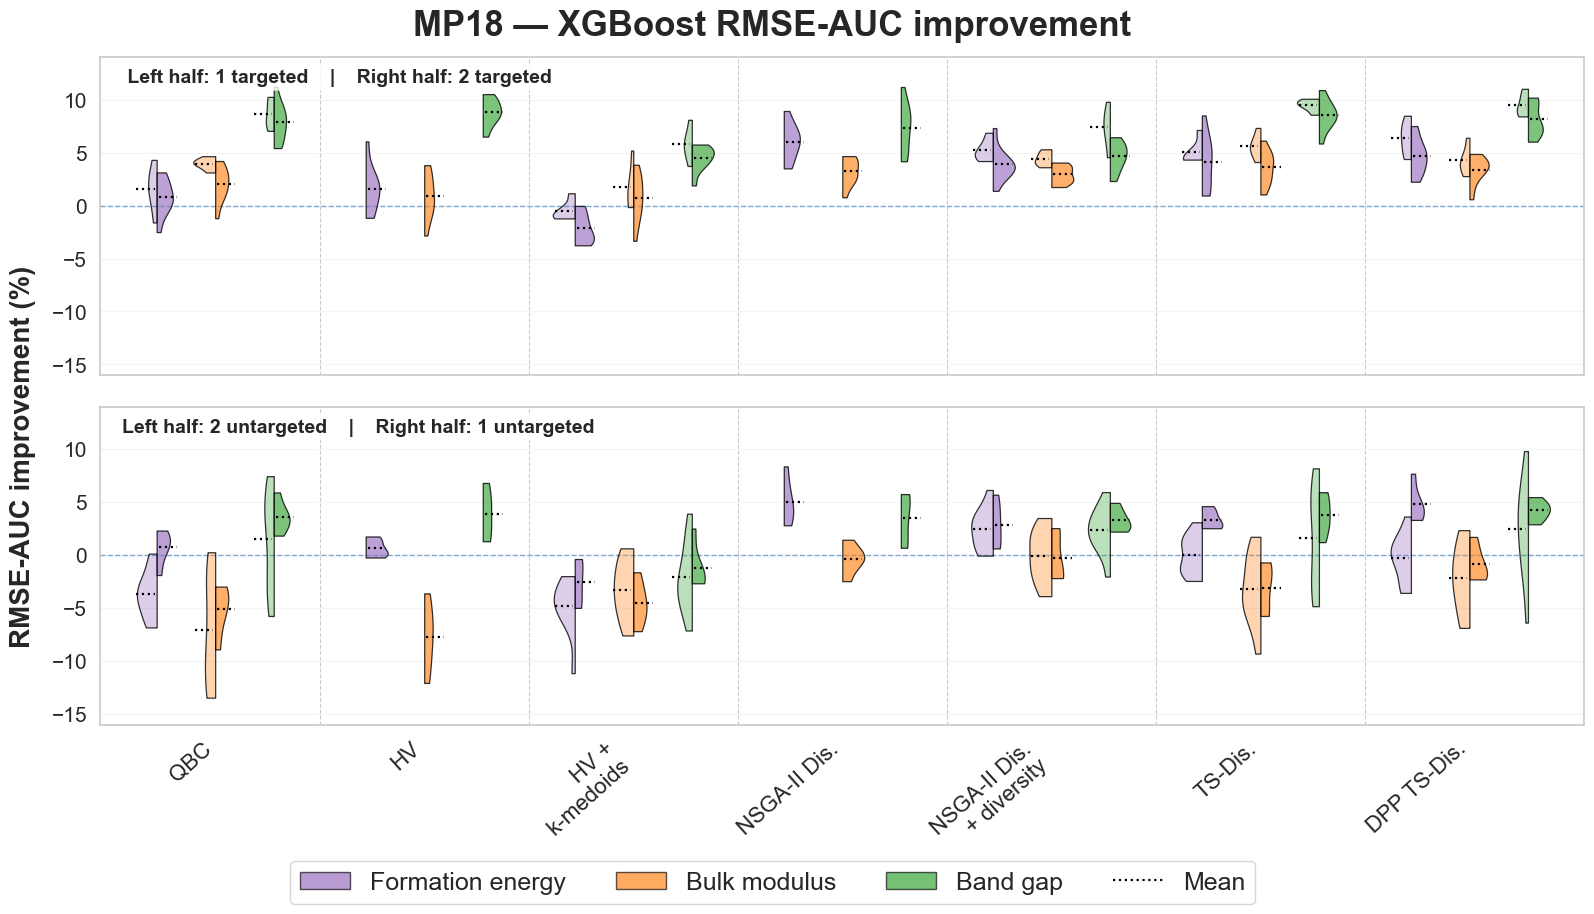


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_XGB_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT MP18 XGBoost per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_XGB_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT MP18 XGBoost mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\MP18\MP18_XGB_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING JARVIS18 — Random Forest

================ DISCOVERED JARVIS18 RF FILES ================
                 pol

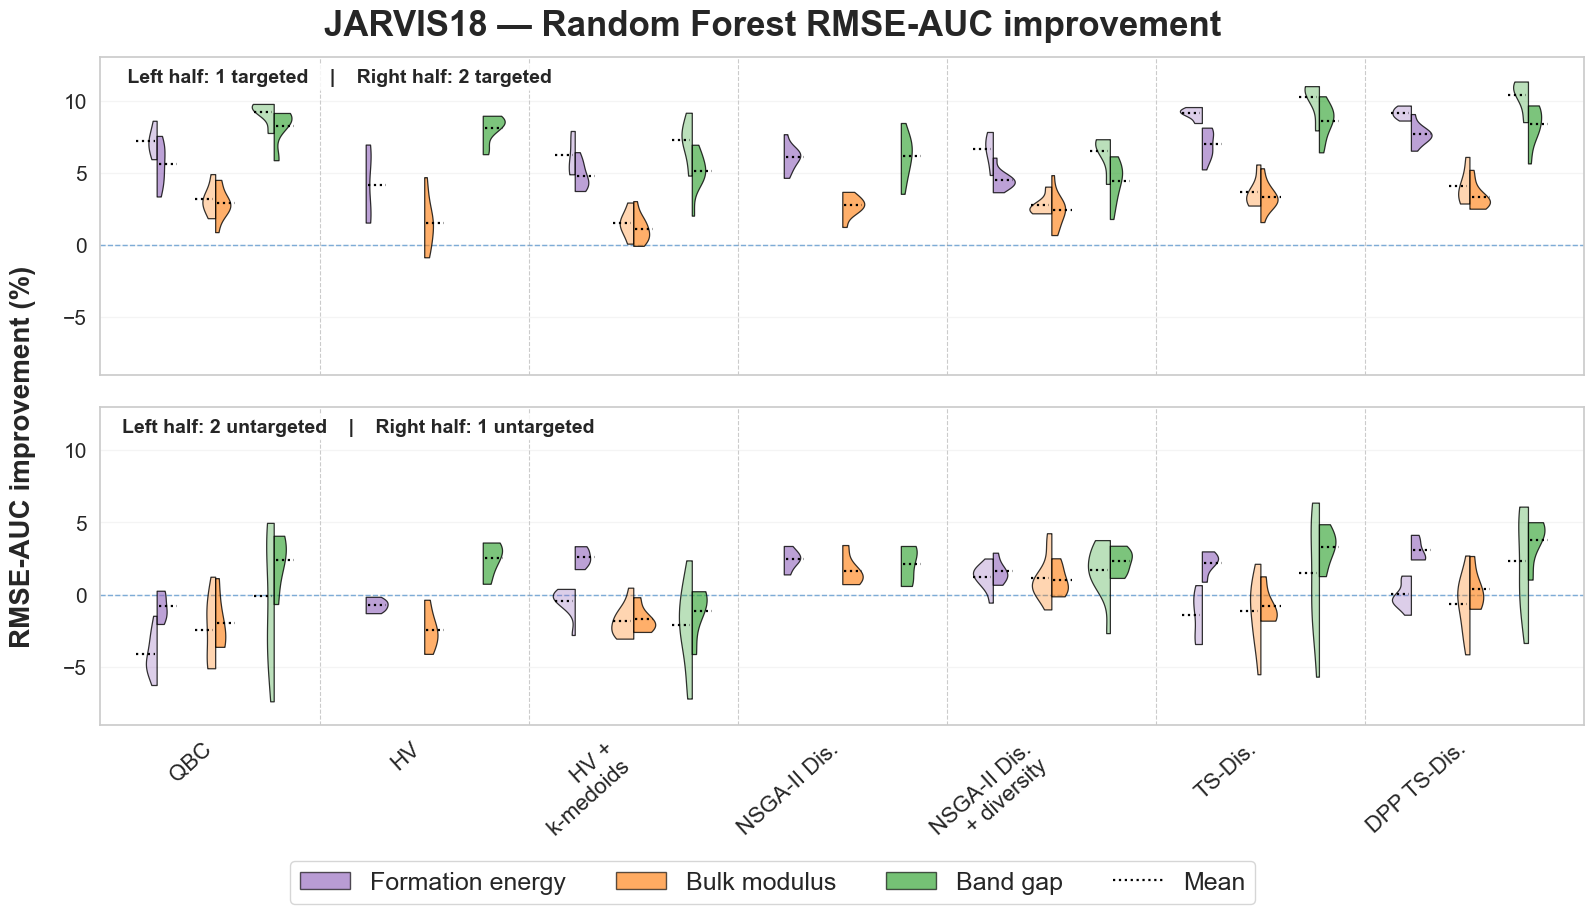


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_RF_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT JARVIS18 Random Forest per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_RF_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT JARVIS18 Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_RF_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING JARVIS18 — XGBoost

================ DISCOVERED JARVIS18 XGB FILES =

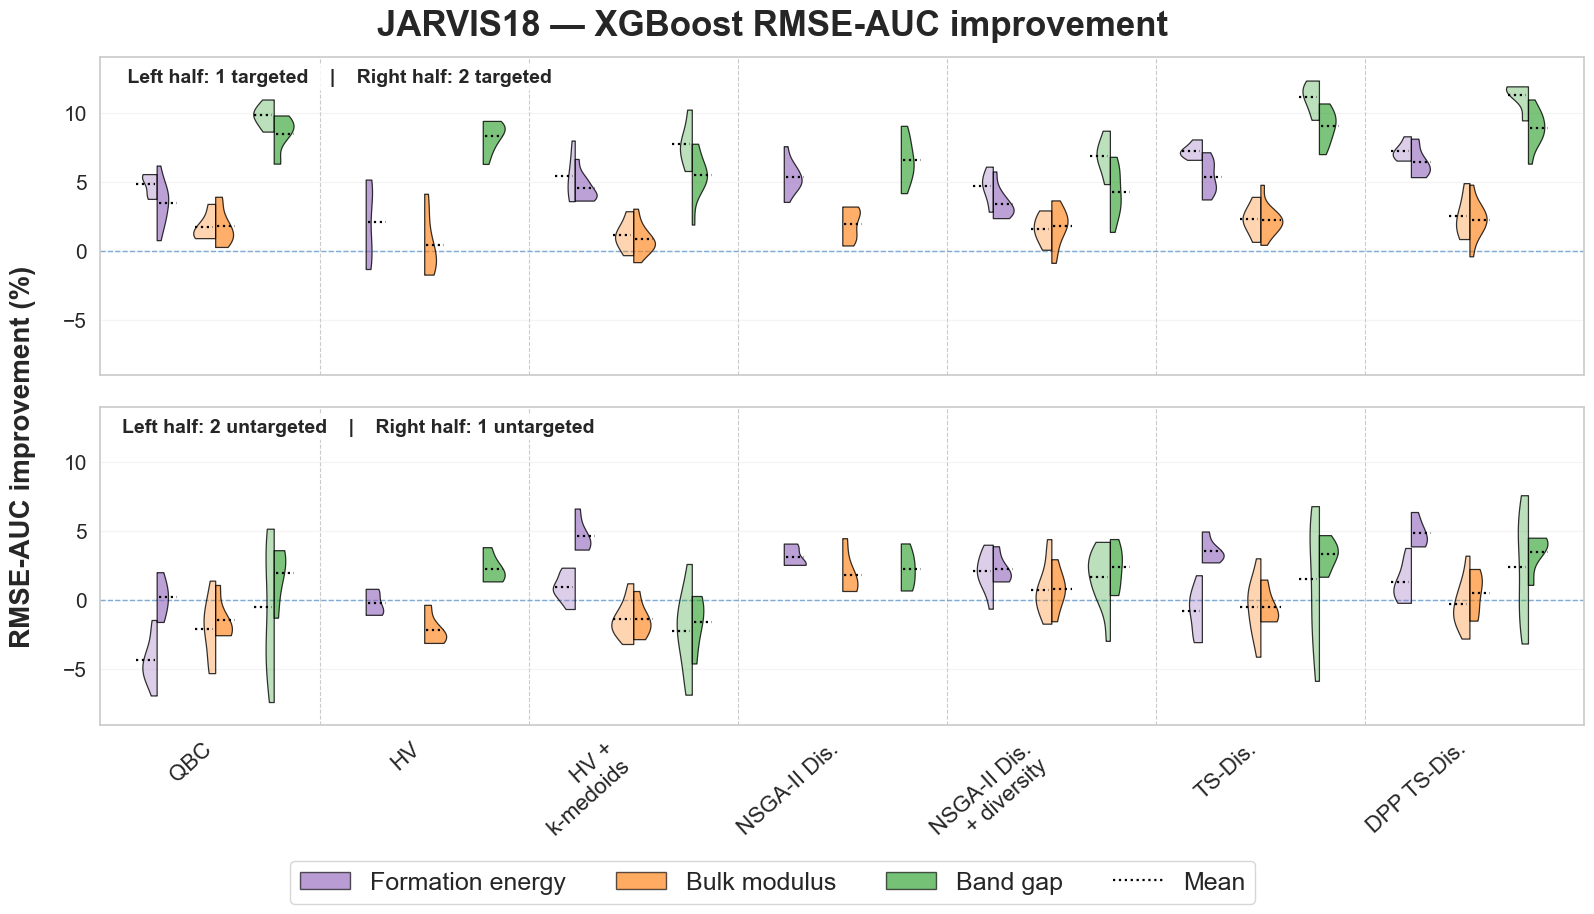


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_XGB_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT JARVIS18 XGBoost per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_XGB_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT JARVIS18 XGBoost mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS18\JARVIS18_XGB_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING JARVIS22 — Random Forest

================ DISCOVERED JARVIS22 RF FILES =====

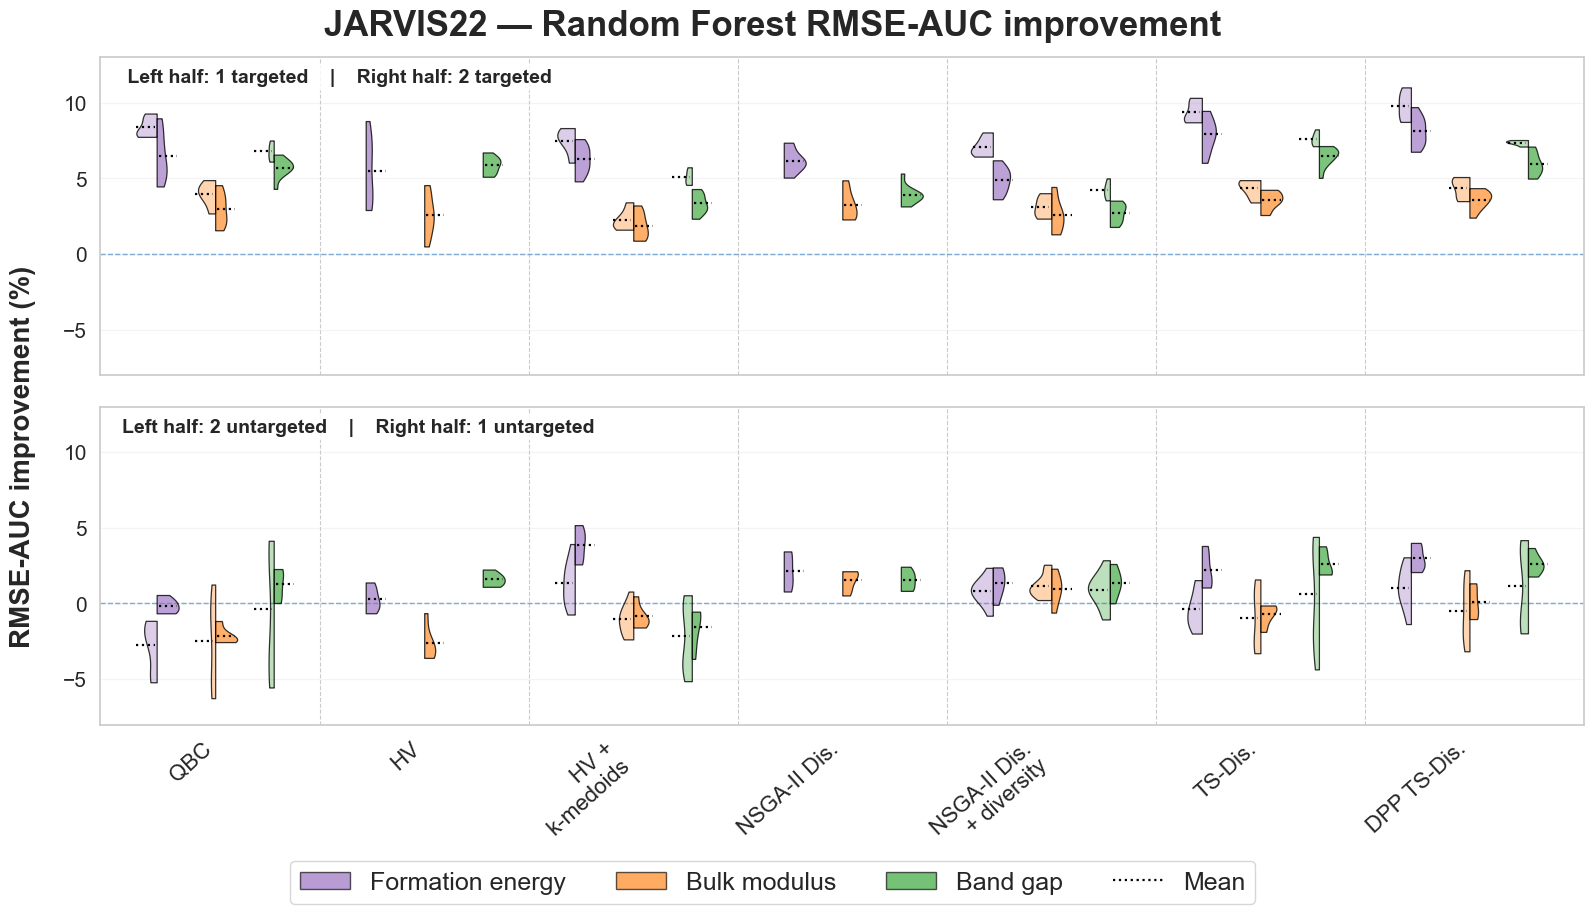


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_RF_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT JARVIS22 Random Forest per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_RF_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT JARVIS22 Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_RF_DFT_property_mean_std_count_direct_from_AL.csv

PROCESSING JARVIS22 — XGBoost

================ DISCOVERED JARVIS22 XGB FILES =

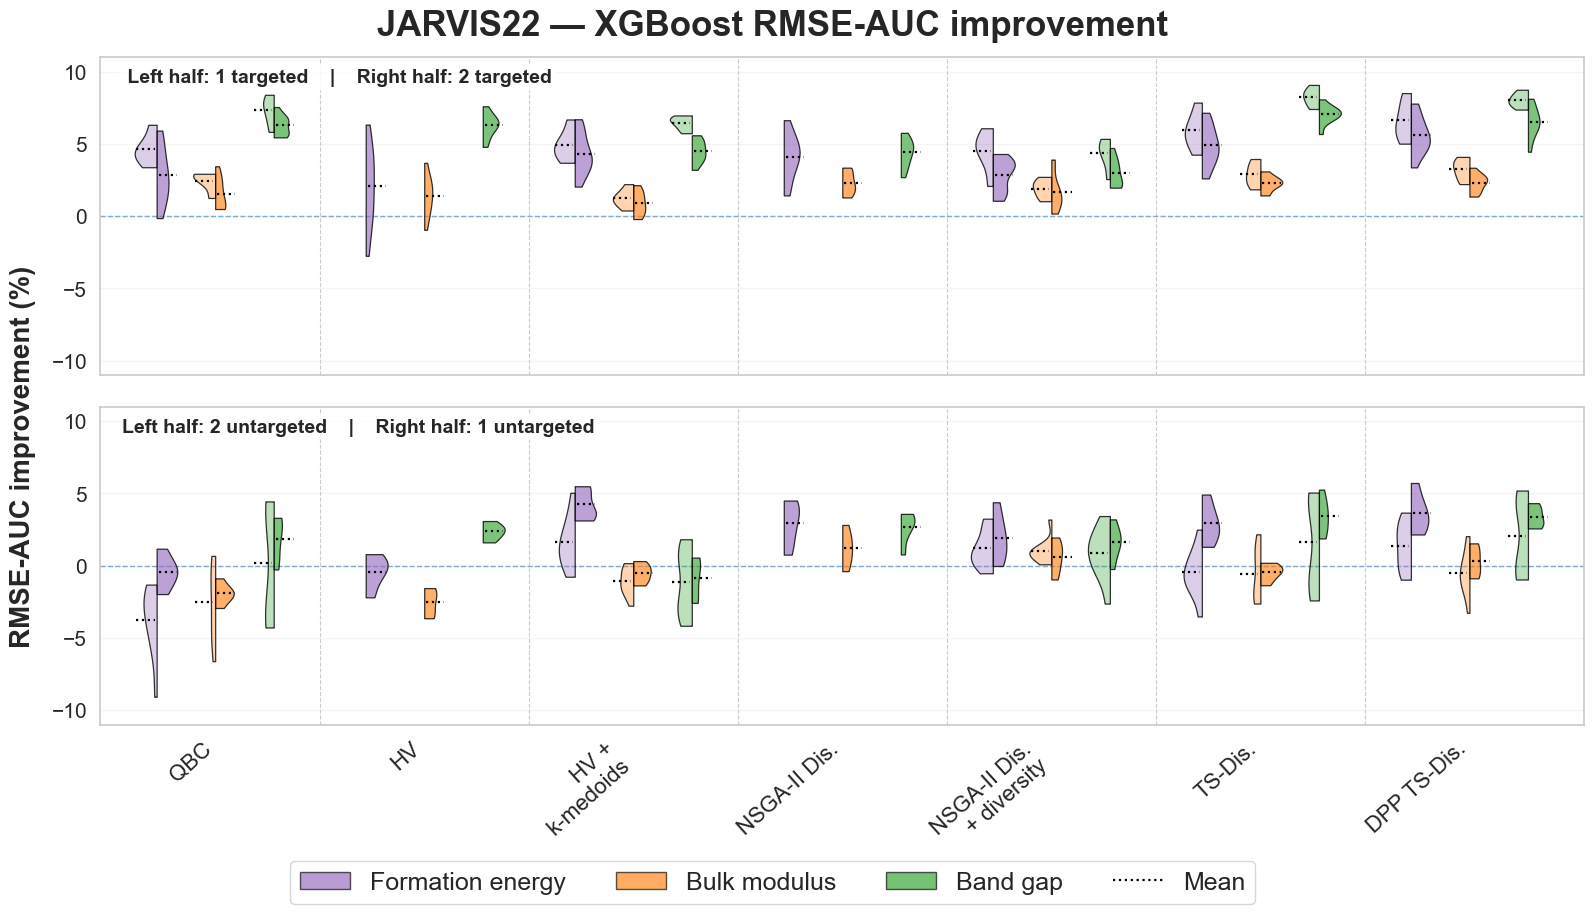


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_XGB_DFT_property_split_violins_with_HV_sns_split.png

Saved DIRECT JARVIS22 XGBoost per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_XGB_DFT_property_seed_improvements_direct_from_AL.csv

Saved DIRECT JARVIS22 XGBoost mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB\JARVIS22\JARVIS22_XGB_DFT_property_mean_std_count_direct_from_AL.csv


In [6]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
OUTPUT_BASE_ROOT = BASE_ROOT / "plots" / "DFT_Property_Mean_Direct_From_AL_RF_XGB"
OUTPUT_BASE_ROOT.mkdir(parents=True, exist_ok=True)
# Each dataset/model combination is processed independently and saved as a separate figure.
DATASETS = ["mp21", "mp18", "jarvis18", "jarvis22"]
MODELS = ["rf", "xgb"]
DATASET = None  # Assigned inside run_dataset_model().
MODEL = None    # Assigned inside run_dataset_model().
SEEDS = range(5)
# =============================================================================
# DFT properties and RMSE aliases
# =============================================================================
# Formation energy is saved with two spellings in different raw campaigns.
RMSE_METRIC_ALIASES = {
    "e_form": ["rmse_eform", "rmse_e_form"],
    "bulk_modulus": ["rmse_bulk_modulus"],
    "bandgap": ["rmse_bandgap"],
}
PROPERTY_LABELS = {
    "e_form": "Formation energy",
    "bulk_modulus": "Bulk modulus",
    "bandgap": "Band gap",
}
PROPERTY_ORDER = [
    "Formation energy",
    "Bulk modulus",
    "Band gap",
]
PROPERTY_COLORS = {
    "Formation energy": "#9467bd",
    "Bulk modulus": "#ff7f0e",
    "Band gap": "#2ca02c",
}
# Three DFT properties, separated within each policy group.
PROPERTY_X_OFFSETS = {
    "Formation energy": -0.28,
    "Bulk modulus": 0.00,
    "Band gap": +0.28,
}
VIOLIN_WIDTH = 0.21
# =============================================================================
# Target-case definitions
# =============================================================================
TARGET_CASES = {
    # 1 target
    "e_form": {"e_form"},
    "bulk_modulus": {"bulk_modulus"},
    "bandgap": {"bandgap"},
    # 2 targets
    "eform_bulk_modulus": {"e_form", "bulk_modulus"},
    "bandgap_eform": {"bandgap", "e_form"},
    "bandgap_bulkmodulus": {"bandgap", "bulk_modulus"},
}
ONE_TARGET_CASES = {
    "e_form",
    "bulk_modulus",
    "bandgap",
}
TWO_TARGET_CASES = {
    "eform_bulk_modulus",
    "bandgap_eform",
    "bandgap_bulkmodulus",
}
# =============================================================================
# Requested comparison cases
# =============================================================================
# DFT has 3 properties total:
#   1 targeted -> 2 untargeted
#   2 targeted -> 1 untargeted
AXIS_ORDER = [
    "1 targeted",
    "2 targeted",
    "2 untargeted",
    "1 untargeted",
]
# =============================================================================
# Policies
# =============================================================================
POLICY_ORDER = ['QBC', 'HV', 'HV + k-medoids', 'NSGA-II QBC', 'NSGA-II QBC + diversity', 'TS-QBC', 'DPP-TS-QBC']
DISPLAY_POLICY_LABELS = {'QBC': 'QBC', 'HV + k-medoids': 'HV +\nk-medoids', 'TS-QBC': 'TS-Dis.', 'DPP-TS-QBC': 'DPP TS-Dis.', 'NSGA-II QBC': 'NSGA-II Dis.', 'NSGA-II QBC + diversity': 'NSGA-II Dis.\n+ diversity', 'HV': 'HV', 'Random': 'Random'}
# =============================================================================
# Path / naming helpers
# =============================================================================
def _norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())
def identify_dataset(text):
    key = _norm(text)
    aliases = {
        "mp21": ["mp21", "mp2021"],
        "mp18": ["mp18", "mp2018"],
        "jarvis18": ["jarvis18", "jarvis2018"],
        "jarvis22": ["jarvis22", "jarvis2022"],
    }
    for dataset, names in aliases.items():
        if any(_norm(name) in key for name in names):
            return dataset
    return None
def identify_seed_and_model(path):
    path = Path(path)
    # Standard raw filenames end with rf, rf0, rf1, ... or xgb equivalents.
    match = re.search(
        r"(?:_|-|\s)(rf|xgb)(\d*)\.csv$",
        path.name,
        flags=re.IGNORECASE,
    )
    if match:
        model = match.group(1).lower()
        digits = match.group(2)
        if digits != "":
            return model, int(digits)
        if path.parent.name.isdigit():
            return model, int(path.parent.name)
        for parent in path.parents:
            if parent.name.isdigit():
                return model, int(parent.name)
    # Fallback to seed folder + model text anywhere in filename.
    model = None
    lower_name = path.name.lower()
    if "_rf" in lower_name or lower_name.endswith("rf.csv"):
        model = "rf"
    elif "_xgb" in lower_name or lower_name.endswith("xgb.csv"):
        model = "xgb"
    seed = None
    for parent in path.parents:
        if parent.name.isdigit():
            seed = int(parent.name)
            break
    return model, seed
def identify_target_case(text):
    key = _norm(text)
    # Two-target names must be checked before single-target names.
    ordered = [
        ("eform_bulk_modulus", ["eformbulkmodulus"]),
        ("bandgap_bulkmodulus", ["bandgapbulkmodulus"]),
        ("bandgap_eform", ["bandgapeform"]),
        ("bulk_modulus", ["bulkmodulus"]),
        ("bandgap", ["bandgap"]),
        ("e_form", ["eform"]),
    ]
    for target_case, aliases in ordered:
        if any(_norm(alias) in key for alias in aliases):
            return target_case
    return None
def is_plain_qbc_file(path):
    """
    Detect plain QBC raw files for both one-target and two-target DFT campaigns.
    Important one-target MP21 example:
        ...\al\QBC\mp21\bandgap\0\mp21_bandgap_QBC_rf.csv
    Two-target examples may instead live under grow2QBC / growing2QBC.
    """
    path = Path(path)
    full = _norm(str(path))
    name = _norm(path.name)
    parts_norm = {_norm(part) for part in path.parts}
    # Exclude QBC-containing names that belong to other acquisition policies.
    if (
        "dpptsqbc" in full
        or "tsqbc" in full
        or "nsgaii" in full
        or "growea" in full
        or "disagreementhv" in full
    ):
        return False
    # ------------------------------------------------------------------
    # Exact one-target QBC folder family:
    #   ...\al\QBC\mp21\bandgap\0\mp21_bandgap_QBC_rf.csv
    # ------------------------------------------------------------------
    if "qbc" in parts_norm:
        return True
    # Filename family:
    #   mp21_bandgap_QBC_rf.csv
    #   mp21_bandgap_QBC_rf0.csv
    # etc.
    if re.search(
        r"(?:^|[_\-])qbc[_\-](?:rf|xgb)\d*\.csv$",
        path.name,
        flags=re.IGNORECASE,
    ):
        return True
    # Existing grow-QBC families.
    if (
        "grow2qbc" in full
        or "growing2qbc" in full
        or "growqbc" in full
        or "growingqbc" in full
        or name.startswith("qbc")
    ):
        return True
    return False
def detect_policy(path):
    """
    Detect DFT acquisition policy from the complete normalized path.
    The detector intentionally handles both 1-target and 2-target naming
    families without hard-coding the exact filename for every dataset.
    """
    full = _norm(str(path))
    if "random" in full:
        return "Random"
    # ------------------------------------------------------------------
    # DPP / TS before plain QBC
    # ------------------------------------------------------------------
    if "dpptsqbc" in full:
        return "DPP-TS-QBC"
    if "tsqbc" in full and "dpptsqbc" not in full:
        return "TS-QBC"
    # ------------------------------------------------------------------
    # NSGA-II / EA with diversity
    # ------------------------------------------------------------------
    if (
        "groweaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or (("growea" in full or "growingea" in full) and "divers" in full)
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # ------------------------------------------------------------------
    # NSGA-II / EA without diversity
    # ------------------------------------------------------------------
    if (
        "groweaqbc1obj" in full
        or (("growea" in full or "growingea" in full) and "divers" not in full)
        or ("nsgaii" in full and "divers" not in full)
    ):
        return "NSGA-II QBC"
    # ------------------------------------------------------------------
    # HV + k-medoids
    # ------------------------------------------------------------------
    if (
        "growdisagreementhvtopmkmedoidstwotargets" in full
        or "growdisagreementhvtopmkmedoidsonetarget" in full
        or "growdisagreementhvtopmkmedoids" in full
        or "hvkmedoids" in full
    ):
        return "HV + k-medoids"
    # ------------------------------------------------------------------
    # HV without explicit diversity
    # ------------------------------------------------------------------
    if (
        "growdisagreementhv" in full
        and "kmedoids" not in full
    ):
        return "HV"
    # ------------------------------------------------------------------
    # Plain QBC
    # ------------------------------------------------------------------
    if is_plain_qbc_file(path):
        return "QBC"
    return None
# =============================================================================
# RMSE-AUC helpers
# =============================================================================
def resolve_metric_column(df, property_id):
    for column in RMSE_METRIC_ALIASES[property_id]:
        if column in df.columns:
            return column
    return None
def normalized_rmse_auc_from_file(path, property_id):
    """
    Return normalized RMSE-AUC from one raw AL CSV file.
    The formation-energy alias rmse_eform / rmse_e_form is resolved
    automatically.
    """
    if path is None or not Path(path).exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}")
        return None
    metric = resolve_metric_column(df, property_id)
    if metric is None:
        print(
            f"WARNING: no RMSE column for property={property_id}: {path}\n"
            f"Available RMSE columns: "
            f"{[c for c in df.columns if str(c).lower().startswith('rmse')]}"
        )
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(
        curve["train_ratio"],
        errors="coerce",
    )
    curve[metric] = pd.to_numeric(
        curve[metric],
        errors="coerce",
    )
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "metric_column": metric,
        "n_iterations": int(len(curve)),
    }
# =============================================================================
# Discover raw files for the currently selected dataset/model
# =============================================================================
def discover_raw_files():
    if not DATA_ROOT.exists():
        raise FileNotFoundError(
            f"Raw AL folder not found:\n{DATA_ROOT}"
        )
    rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        dataset = identify_dataset(str(path))
        if dataset != DATASET:
            continue
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        policy = detect_policy(path)
        if policy is None:
            continue
        target_case = identify_target_case(str(path))
        rows.append(
            {
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "policy": policy,
                "target_case": target_case,
                "path": path,
            }
        )
    index_df = pd.DataFrame(rows)
    if index_df.empty:
        raise RuntimeError(
            f"No {DATASET.upper()} {MODEL.upper()} raw AL files were discovered.\n"
            f"DATA_ROOT = {DATA_ROOT}"
        )
    print(f"\n================ DISCOVERED {DATASET.upper()} {MODEL.upper()} FILES ================")
    print(
        index_df[
            ["policy", "target_case", "seed", "path"]
        ]
        .sort_values(["policy", "target_case", "seed"])
        .to_string(index=False)
    )
    qbc_one_target = index_df.loc[
        (index_df["policy"] == "QBC")
        & (index_df["target_case"].isin(["e_form", "bulk_modulus", "bandgap"]))
    ].copy()
    print("\n================ ONE-TARGET QBC CHECK ================")
    if qbc_one_target.empty:
        print("ERROR: no one-target QBC files were detected.")
    else:
        print(
            qbc_one_target[
                ["target_case", "seed", "path"]
            ]
            .sort_values(["target_case", "seed"])
            .to_string(index=False)
        )
    return index_df
def select_random_file(index_df, seed, target_case=None):
    candidates = index_df.loc[
        (index_df["policy"] == "Random")
        & (index_df["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    # Prefer exact target-case Random if such files exist.
    if target_case is not None:
        exact = candidates.loc[
            candidates["target_case"] == target_case
        ]
        if not exact.empty:
            return exact.iloc[0]["path"]
    # Prefer a generic / all Random file.
    generic = candidates.loc[
        candidates["target_case"].isna()
    ]
    if not generic.empty:
        return generic.iloc[0]["path"]
    return candidates.iloc[0]["path"]
# =============================================================================
# Build DIRECT per-seed improvement observations
# =============================================================================
def collect_raw_improvements():
    """
    Build one observation per:
        target campaign x policy x seed x DFT property
    Improvement is calculated directly from raw AL files:
        100 * (1 - policy_RMSE_AUC / random_RMSE_AUC)
    The active DATASET and MODEL globals determine which files are used.
    """
    file_index = discover_raw_files()
    rows = []
    policy_rows = file_index.loc[
        file_index["policy"] != "Random"
    ].copy()
    # Avoid duplicate path records if a broad detector catches the same file twice.
    policy_rows = policy_rows.drop_duplicates(
        subset=["policy", "target_case", "seed", "path"]
    )
    for row in policy_rows.itertuples(index=False):
        target_case = row.target_case
        if target_case not in TARGET_CASES:
            continue
        targeted_properties = TARGET_CASES[target_case]
        n_targets = len(targeted_properties)
        if n_targets not in {1, 2}:
            continue
        random_file = select_random_file(
            file_index,
            seed=row.seed,
            target_case=target_case,
        )
        if random_file is None:
            print(
                f"WARNING: no Random file for seed={row.seed}, "
                f"target_case={target_case}"
            )
            continue
        for property_id, property_name in PROPERTY_LABELS.items():
            policy_auc = normalized_rmse_auc_from_file(
                row.path,
                property_id,
            )
            random_auc = normalized_rmse_auc_from_file(
                random_file,
                property_id,
            )
            if policy_auc is None or random_auc is None:
                continue
            if random_auc["rmse_auc"] == 0:
                continue
            case_type = (
                "targeted"
                if property_id in targeted_properties
                else "untargeted"
            )
            if n_targets == 1:
                axis_name = (
                    "1 targeted"
                    if case_type == "targeted"
                    else "2 untargeted"
                )
            else:
                axis_name = (
                    "2 targeted"
                    if case_type == "targeted"
                    else "1 untargeted"
                )
            improvement_percent = 100.0 * (
                1.0
                - policy_auc["rmse_auc"]
                / random_auc["rmse_auc"]
            )
            rows.append(
                {
                    "dataset": DATASET,
                    "model": MODEL,
                    "n_targets": n_targets,
                    "axis": axis_name,
                    "case_type": case_type,
                    "target_case": target_case,
                    "policy": row.policy,
                    "seed": row.seed,
                    "property_id": property_id,
                    "property_name": property_name,
                    "improvement_percent": improvement_percent,
                    "policy_rmse_auc": policy_auc["rmse_auc"],
                    "random_rmse_auc": random_auc["rmse_auc"],
                    "policy_file": str(row.path),
                    "random_file": str(random_file),
                    "policy_metric_column": policy_auc["metric_column"],
                    "random_metric_column": random_auc["metric_column"],
                }
            )
    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            f"No {DATASET.upper()} {MODEL.upper()} improvement observations were built."
        )
    return raw_df
# =============================================================================
# Statistics
# =============================================================================
def summarize_raw_improvements(raw_df):
    stats_df = (
        raw_df.groupby(
            [
                "dataset",
                "model",
                "axis",
                "n_targets",
                "case_type",
                "policy",
                "property_id",
                "property_name",
            ],
            as_index=False,
        )["improvement_percent"]
        .agg(
            mean_percent="mean",
            std_percent="std",
            count="count",
        )
    )
    print(f"\n================ {DATASET.upper()} {MODEL.upper()} DIRECT RAW-AL STATISTICS ================")
    for row in stats_df.itertuples(index=False):
        std_text = (
            "NaN"
            if pd.isna(row.std_percent)
            else f"{row.std_percent:.4f}"
        )
        print(
            f"{row.axis:<14} | "
            f"{row.policy:<28} | "
            f"{row.property_name:<18} | "
            f"mean={row.mean_percent:8.4f} | "
            f"std={std_text:>8} | "
            f"count={int(row.count):2d}"
        )
    return stats_df
# =============================================================================
# Plot:
# Top row:
#   left half  = 1 targeted
#   right half = 2 targeted
#
# Bottom row:
#   left half  = 2 untargeted
#   right half = 1 untargeted
# =============================================================================
PANEL_SPECS = [
    {
        "left_axis": "1 targeted",
        "right_axis": "2 targeted",
        "title": " Left half: 1 targeted    |    Right half: 2 targeted",
    },
    {
        "left_axis": "2 untargeted",
        "right_axis": "1 untargeted",
        "title": "Left half: 2 untargeted    |    Right half: 1 untargeted",
    },
]
def shift_new_violin_bodies(
    ax,
    start_collection_idx,
    x_offset,
):
    new_collections = ax.collections[start_collection_idx:]
    for coll in new_collections:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset
def draw_half_mean_line(
    ax,
    values,
    position,
    width,
    side,
):
    if len(values) == 0:
        return
    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width
    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent
    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )
def run_dataset_model(dataset, model):
    """Process one DFT dataset/model combination and save separate figure/CSV outputs."""
    global DATASET, MODEL
    DATASET = dataset.lower()
    MODEL = model.lower()
    dataset_tag = DATASET.upper()
    model_tag = MODEL.upper()
    model_name = "Random Forest" if MODEL == "rf" else "XGBoost"
    # Keep each dataset together, but separate RF and XGBoost outputs by filename.
    output_root = OUTPUT_BASE_ROOT / dataset_tag
    output_root.mkdir(parents=True, exist_ok=True)
    output_figure = output_root / f"{dataset_tag}_{model_tag}_DFT_property_split_violins_with_HV_sns_split.png"
    output_raw_cases = output_root / f"{dataset_tag}_{model_tag}_DFT_property_seed_improvements_direct_from_AL.csv"
    output_stats = output_root / f"{dataset_tag}_{model_tag}_DFT_property_mean_std_count_direct_from_AL.csv"
    print("\n" + "=" * 90)
    print(f"PROCESSING {dataset_tag} — {model_name}")
    print("=" * 90)
    raw_df = collect_raw_improvements()
    raw_df.to_csv(output_raw_cases, index=False)
    stats_df = summarize_raw_improvements(raw_df)
    stats_df.to_csv(output_stats, index=False)
    # Dataset-specific y limits. Each figure is scaled from its own observations.
    all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
    all_values = all_values[np.isfinite(all_values)]
    if len(all_values) == 0:
        global_y_lim = (-1, 1)
    else:
        global_min = float(all_values.min())
        global_max = float(all_values.max())
        global_span = max(global_max - global_min, 1.0)
        padding = max(1.0, 0.08 * global_span)
        y_min = int(np.floor(global_min - padding))
        y_max = int(np.ceil(global_max + padding))
        y_min = min(y_min, 0)
        y_max = max(y_max, 0)
        global_y_lim = (y_min, y_max)
    # Local aliases used by the unchanged plotting code below.
    OUTPUT_FIGURE = output_figure
    OUTPUT_RAW_CASES = output_raw_cases
    OUTPUT_STATS = output_stats
    GLOBAL_Y_LIM = global_y_lim
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(16.4, 9.6),
        sharex=False,
        sharey=True,
    )
    panel_df_all = raw_df.copy()
    # Hide only the one-targeted distributions; retain two-untargeted data.
    hide_1_targeted = (
        panel_df_all["axis"].eq("1 targeted")
        & panel_df_all["policy"].isin(["HV", "NSGA-II QBC"])
    )
    panel_df_all = panel_df_all.loc[~hide_1_targeted].copy()
    # Only policies that actually have data for this dataset are shown.
    available_policies = set(panel_df_all["policy"].unique())
    common_policy_order = [
        policy
        for policy in POLICY_ORDER
        if policy in available_policies
    ]
    if not common_policy_order:
        raise RuntimeError(
            f"No requested acquisition policies were available for {DATASET.upper()}."
        )
    x_positions = np.arange(
        len(common_policy_order),
        dtype=float,
    )
    common_y_min, common_y_max = GLOBAL_Y_LIM
    for row_index, panel_spec in enumerate(PANEL_SPECS):
        ax = axes[row_index]
        left_axis = panel_spec["left_axis"]
        right_axis = panel_spec["right_axis"]
        left_df = panel_df_all.loc[
            panel_df_all["axis"] == left_axis
        ].copy()
        right_df = panel_df_all.loc[
            panel_df_all["axis"] == right_axis
        ].copy()
        for property_name in PROPERTY_ORDER:
            color = PROPERTY_COLORS[property_name]
            left_prop_df = left_df.loc[
                left_df["property_name"] == property_name,
                ["policy", "improvement_percent"],
            ].copy()
            right_prop_df = right_df.loc[
                right_df["property_name"] == property_name,
                ["policy", "improvement_percent"],
            ].copy()
            left_prop_df["comparison_case"] = "left"
            right_prop_df["comparison_case"] = "right"
            prop_df = pd.concat(
                [left_prop_df, right_prop_df],
                ignore_index=True,
            )
            prop_df["policy"] = pd.Categorical(
                prop_df["policy"],
                categories=common_policy_order,
                ordered=True,
            )
            prop_df["comparison_case"] = pd.Categorical(
                prop_df["comparison_case"],
                categories=["left", "right"],
                ordered=True,
            )
            prop_df["improvement_percent"] = pd.to_numeric(
                prop_df["improvement_percent"],
                errors="coerce",
            )
            prop_df = prop_df.dropna(
                subset=["improvement_percent"]
            )
            if prop_df.empty:
                print(
                    f"WARNING: no observations for property={property_name}, "
                    f"left_axis={left_axis}, right_axis={right_axis}"
                )
                continue
            # Diagnostic for QBC after the path fix.
            if "QBC" in common_policy_order:
                qbc_left_n = int(
                    (
                        (left_prop_df["policy"] == "QBC")
                        & pd.to_numeric(
                            left_prop_df["improvement_percent"],
                            errors="coerce",
                        ).notna()
                    ).sum()
                )
                qbc_right_n = int(
                    (
                        (right_prop_df["policy"] == "QBC")
                        & pd.to_numeric(
                            right_prop_df["improvement_percent"],
                            errors="coerce",
                        ).notna()
                    ).sum()
                )
                print(
                    f"{panel_spec['title']} | {property_name} | QBC | "
                    f"left n={qbc_left_n} | right n={qbc_right_n}"
                )
            start_idx = len(ax.collections)
            sns.violinplot(
                data=prop_df,
                x="policy",
                y="improvement_percent",
                hue="comparison_case",
                order=common_policy_order,
                hue_order=["left", "right"],
                split=True,
                inner=None,
                cut=0,
                bw_adjust=1.0,
                gridsize=200,
                linewidth=1.0,
                saturation=1.0,
                palette={
                    "left": color,
                    "right": color,
                },
                width=VIOLIN_WIDTH,
                ax=ax,
            )
            shift_new_violin_bodies(
                ax,
                start_collection_idx=start_idx,
                x_offset=PROPERTY_X_OFFSETS[property_name],
            )
            # Keep the same property color on both halves; only alpha differs.
            new_collections = ax.collections[start_idx:]
            property_rgb = mcolors.to_rgb(color)
            expected_centers = (
                x_positions + PROPERTY_X_OFFSETS[property_name]
            )
            for coll in new_collections:
                try:
                    paths = coll.get_paths()
                    if not paths:
                        continue
                    verts = paths[0].vertices
                    x_mean = float(np.mean(verts[:, 0]))
                    nearest_center = float(
                        expected_centers[
                            np.argmin(
                                np.abs(expected_centers - x_mean)
                            )
                        ]
                    )
                    if x_mean < nearest_center:
                        face_rgba = (*property_rgb, 0.32)
                    else:
                        face_rgba = (*property_rgb, 0.62)
                    coll.set_alpha(None)
                    coll.set_facecolor([face_rgba])
                    coll.set_edgecolor(
                        (*mcolors.to_rgb("black"), 0.80)
                    )
                    coll.set_linewidth(0.9)
                except Exception as exc:
                    print(
                        f"WARNING: could not style violin half "
                        f"for {property_name}: {exc}"
                    )
            if ax.get_legend() is not None:
                ax.get_legend().remove()
            # Mean lines for both halves.
            for x, policy in zip(
                x_positions,
                common_policy_order,
            ):
                left_values = pd.to_numeric(
                    left_df.loc[
                        (left_df["policy"] == policy)
                        & (
                            left_df["property_name"]
                            == property_name
                        ),
                        "improvement_percent",
                    ],
                    errors="coerce",
                )
                left_values = left_values[
                    np.isfinite(left_values)
                ].to_numpy(dtype=float)
                right_values = pd.to_numeric(
                    right_df.loc[
                        (right_df["policy"] == policy)
                        & (
                            right_df["property_name"]
                            == property_name
                        ),
                        "improvement_percent",
                    ],
                    errors="coerce",
                )
                right_values = right_values[
                    np.isfinite(right_values)
                ].to_numpy(dtype=float)
                x_plot = (
                    x + PROPERTY_X_OFFSETS[property_name]
                )
                if len(left_values) > 0:
                    draw_half_mean_line(
                        ax=ax,
                        values=left_values,
                        position=x_plot,
                        width=VIOLIN_WIDTH,
                        side="left",
                    )
                if len(right_values) > 0:
                    draw_half_mean_line(
                        ax=ax,
                        values=right_values,
                        position=x_plot,
                        width=VIOLIN_WIDTH,
                        side="right",
                    )
        # -------------------------------------------------------------------------
        # Panel formatting
        # -------------------------------------------------------------------------
        ax.set_ylim(
            common_y_min,
            common_y_max,
        )
        ax.set_xlim(
            -0.55,
            len(common_policy_order) - 0.45,
        )
        ax.set_xticks(x_positions)
        if row_index == 0:
            ax.set_xticklabels([])
            ax.tick_params(
                axis="x",
                which="both",
                labelbottom=False,
            )
        else:
            ax.set_xticklabels(
                [
                    DISPLAY_POLICY_LABELS[p]
                    for p in common_policy_order
                ],
                fontsize=16,
                rotation=42,
                ha="right",
            )
        ax.tick_params(
            axis="y",
            labelsize=15,
        )
        ax.grid(
            axis="y",
            alpha=0.20,
        )
        ax.axhline(
            0.0,
            color="#5b9bd5",
            linewidth=1.0,
            linestyle="--",
            alpha=0.90,
            zorder=0,
        )
        for separator_x in (
            np.arange(
                len(common_policy_order) - 1,
                dtype=float,
            )
            + 0.5
        ):
            ax.axvline(
                separator_x,
                color="0.55",
                linewidth=0.8,
                linestyle="--",
                alpha=0.45,
                zorder=0,
            )
        y_range = common_y_max - common_y_min
        if y_range <= 8:
            tick_step = 2
        elif y_range <= 16:
            tick_step = 4
        elif y_range <= 30:
            tick_step = 5
        elif y_range <= 50:
            tick_step = 10
        else:
            tick_step = 20
        first_tick = int(
            np.ceil(
                common_y_min / tick_step
            )
            * tick_step
        )
        last_tick = int(
            np.floor(
                common_y_max / tick_step
            )
            * tick_step
        )
        yticks = np.arange(
            first_tick,
            last_tick + tick_step,
            tick_step,
            dtype=int,
        )
        if (
            common_y_min <= 0 <= common_y_max
            and 0 not in yticks
        ):
            yticks = np.sort(
                np.append(
                    yticks,
                    0,
                )
            )
        ax.set_yticks(yticks)
        ax.text(
            0.015,
            0.965,
            panel_spec["title"],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=14,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.82,
            ),
        )
        ax.set_ylabel("")
        ax.set_xlabel("")
    # =============================================================================
    # Shared labels / legend
    # =============================================================================
    fig.suptitle(
        f"{DATASET.upper()} — {model_name} RMSE-AUC improvement",
        fontsize=25,
        fontweight="bold",
        y=0.965,
    )
    fig.supylabel(
        "RMSE-AUC improvement (%)",
        fontsize=20,
        fontweight="bold",
        x=0.035,
    )
    property_handles = [
        Patch(
            facecolor=PROPERTY_COLORS[property_name],
            edgecolor="black",
            alpha=0.65,
            label=property_name,
        )
        for property_name in PROPERTY_ORDER
    ]
    property_handles += [
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.6,
            linestyle=":",
            label="Mean",
        ),
    ]
    fig.legend(
        handles=property_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=4,
        fontsize=18,
        frameon=True,
    )
    plt.subplots_adjust(
        left=0.09,
        right=0.995,
        top=0.915,
        bottom=0.22,
        hspace=0.10,
    )
    fig.savefig(
        OUTPUT_FIGURE,
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)
    print("\nSaved figure:")
    print(OUTPUT_FIGURE)
    print(f"\nSaved DIRECT {DATASET.upper()} {model_name} per-seed/case observations:")
    print(OUTPUT_RAW_CASES)
    print(f"\nSaved DIRECT {DATASET.upper()} {model_name} mean/std/count statistics:")
    print(OUTPUT_STATS)
if __name__ == "__main__":
    for dataset in DATASETS:
        for model in MODELS:
            try:
                run_dataset_model(dataset, model)
            except Exception as exc:
                model_name = "Random Forest" if model.lower() == "rf" else "XGBoost"
                print(
                    f"\nERROR while processing {dataset.upper()} — {model_name}: {exc}"
                )
                # Continue so one incomplete dataset/model combination does not
                # prevent the remaining figures from being generated.
                continue


Starting DFT plotting
Datasets: ['mp21'] | Models: ['rf', 'xgb']
Starting MP21 — RF

PROCESSING MP21 — Random Forest

================ DISCOVERED MP21 RF FILES ================
                 policy         target_case  seed                                                                                                                                                                                                                                                                                                  path
             DPP-TS-QBC             bandgap     0                                                              C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\al\grow_DPP_TS_QBC_OneTarget\mp21\bandgap\0\mp21_bandgapgrow_DPP_TS_QBC_OneTarget_rf0.csv
             DPP-TS-QBC             bandgap     1                                                              C:\Users\rafae\OneDrive\

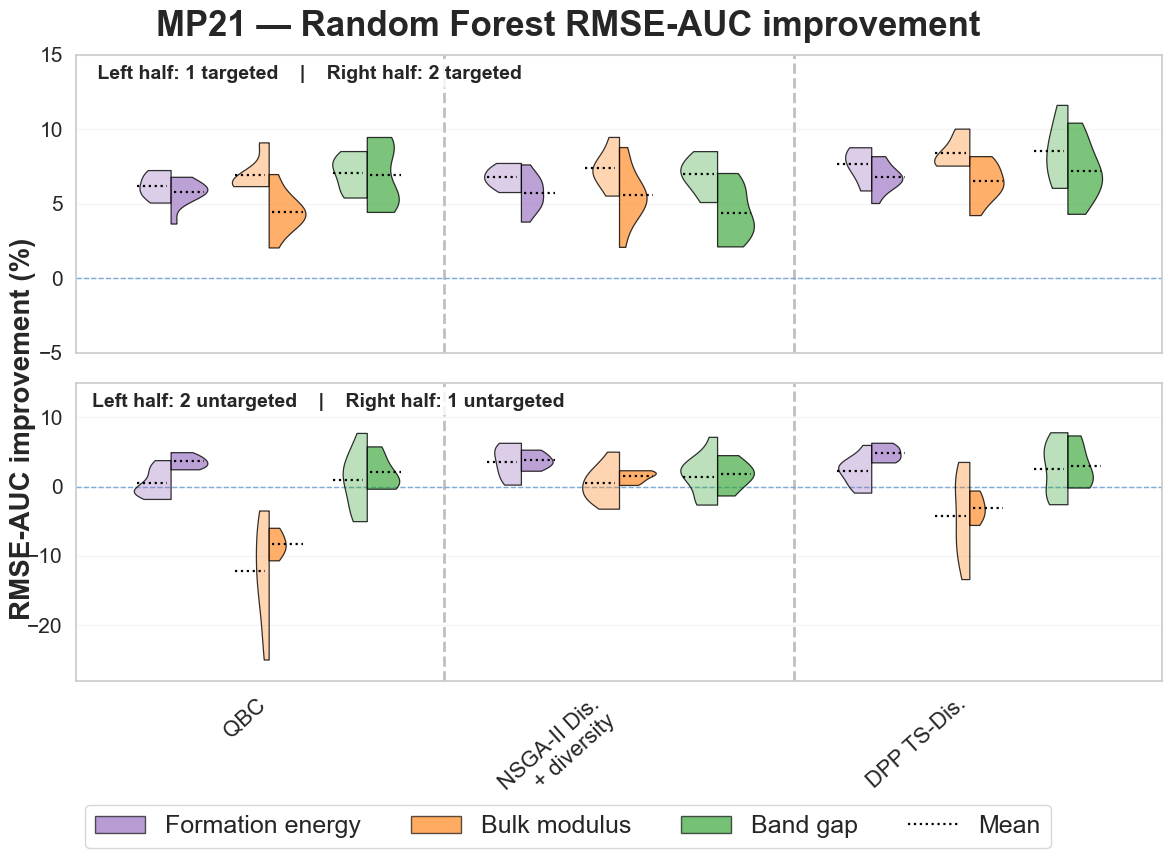


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_RF_DFT_property_split_violins_QBC_NSGAIIdiv_DPPTS_ONLY_TOP_YMIN_MINUS10.png

Saved DIRECT MP21 Random Forest per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_RF_DFT_property_seed_improvements_QBC_NSGAIIdiv_DPPTS_ONLY.csv

Saved DIRECT MP21 Random Forest mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_RF_DFT_property_mean_std_count_QBC_NSGAIIdiv_DPPTS_ONLY.csv
Finished MP

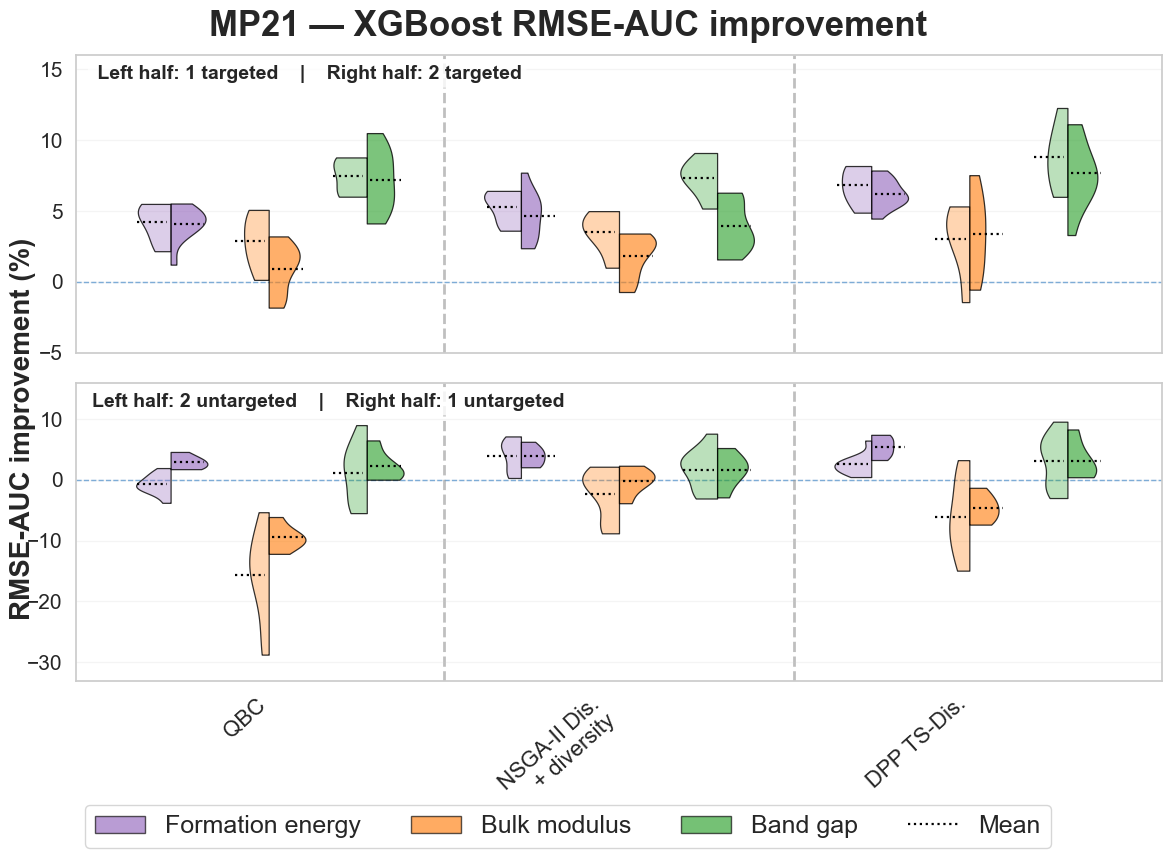


Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_XGB_DFT_property_split_violins_QBC_NSGAIIdiv_DPPTS_ONLY_TOP_YMIN_MINUS10.png

Saved DIRECT MP21 XGBoost per-seed/case observations:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_XGB_DFT_property_seed_improvements_QBC_NSGAIIdiv_DPPTS_ONLY.csv

Saved DIRECT MP21 XGBoost mean/std/count statistics:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\plots\DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES\MP21\MP21_XGB_DFT_property_mean_std_count_QBC_NSGAIIdiv_DPPTS_ONLY.csv
Finished MP21 — XGB


In [7]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
# =============================================================================
# Configuration
# =============================================================================
BASE_ROOT = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)
DATA_ROOT = BASE_ROOT / "al"
OUTPUT_BASE_ROOT = BASE_ROOT / "plots" / "DFT_Property_Mean_Direct_From_AL_RF_XGB_MP21_XGB_3POLICIES"
OUTPUT_BASE_ROOT.mkdir(parents=True, exist_ok=True)
# Each dataset/model combination is processed independently and saved as a separate figure.
DATASETS = ["mp21"]
MODELS = ["rf", "xgb"]
DATASET = None  # Assigned inside run_dataset_model().
MODEL = None    # Assigned inside run_dataset_model().
SEEDS = range(5)
# =============================================================================
# DFT properties and RMSE aliases
# =============================================================================
# Formation energy is saved with two spellings in different raw campaigns.
RMSE_METRIC_ALIASES = {
    "e_form": ["rmse_eform", "rmse_e_form"],
    "bulk_modulus": ["rmse_bulk_modulus"],
    "bandgap": ["rmse_bandgap"],
}
PROPERTY_LABELS = {
    "e_form": "Formation energy",
    "bulk_modulus": "Bulk modulus",
    "bandgap": "Band gap",
}
PROPERTY_ORDER = [
    "Formation energy",
    "Bulk modulus",
    "Band gap",
]
PROPERTY_COLORS = {
    "Formation energy": "#9467bd",
    "Bulk modulus": "#ff7f0e",
    "Band gap": "#2ca02c",
}
# Three DFT properties, separated within each policy group.
PROPERTY_X_OFFSETS = {
    "Formation energy": -0.28,
    "Bulk modulus": 0.00,
    "Band gap": +0.28,
}
VIOLIN_WIDTH = 0.21
# =============================================================================
# Target-case definitions
# =============================================================================
TARGET_CASES = {
    # 1 target
    "e_form": {"e_form"},
    "bulk_modulus": {"bulk_modulus"},
    "bandgap": {"bandgap"},
    # 2 targets
    "eform_bulk_modulus": {"e_form", "bulk_modulus"},
    "bandgap_eform": {"bandgap", "e_form"},
    "bandgap_bulkmodulus": {"bandgap", "bulk_modulus"},
}
ONE_TARGET_CASES = {
    "e_form",
    "bulk_modulus",
    "bandgap",
}
TWO_TARGET_CASES = {
    "eform_bulk_modulus",
    "bandgap_eform",
    "bandgap_bulkmodulus",
}
# =============================================================================
# Requested comparison cases
# =============================================================================
# DFT has 3 properties total:
#   1 targeted -> 2 untargeted
#   2 targeted -> 1 untargeted
AXIS_ORDER = [
    "1 targeted",
    "2 targeted",
    "2 untargeted",
    "1 untargeted",
]
# =============================================================================
# Policies
# =============================================================================
POLICY_ORDER = ['QBC', 'NSGA-II QBC + diversity', 'DPP-TS-QBC']
DISPLAY_POLICY_LABELS = {'QBC': 'QBC', 'HV + k-medoids': 'HV +\nk-medoids', 'TS-QBC': 'TS-Dis.', 'DPP-TS-QBC': 'DPP TS-Dis.', 'NSGA-II QBC': 'NSGA-II Dis.', 'NSGA-II QBC + diversity': 'NSGA-II Dis.\n+ diversity', 'Random': 'Random'}
# =============================================================================
# Path / naming helpers
# =============================================================================
def _norm(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())
def identify_dataset(text):
    key = _norm(text)
    aliases = {
        "mp21": ["mp21", "mp2021"],
        "mp18": ["mp18", "mp2018"],
        "jarvis18": ["jarvis18", "jarvis2018"],
        "jarvis22": ["jarvis22", "jarvis2022"],
    }
    for dataset, names in aliases.items():
        if any(_norm(name) in key for name in names):
            return dataset
    return None
def identify_seed_and_model(path):
    path = Path(path)
    # Standard raw filenames end with rf, rf0, rf1, ... or xgb equivalents.
    match = re.search(
        r"(?:_|-|\s)(rf|xgb)(\d*)\.csv$",
        path.name,
        flags=re.IGNORECASE,
    )
    if match:
        model = match.group(1).lower()
        digits = match.group(2)
        if digits != "":
            return model, int(digits)
        if path.parent.name.isdigit():
            return model, int(path.parent.name)
        for parent in path.parents:
            if parent.name.isdigit():
                return model, int(parent.name)
    # Fallback to seed folder + model text anywhere in filename.
    model = None
    lower_name = path.name.lower()
    if "_rf" in lower_name or lower_name.endswith("rf.csv"):
        model = "rf"
    elif "_xgb" in lower_name or lower_name.endswith("xgb.csv"):
        model = "xgb"
    seed = None
    for parent in path.parents:
        if parent.name.isdigit():
            seed = int(parent.name)
            break
    return model, seed
def identify_target_case(text):
    key = _norm(text)
    # Two-target names must be checked before single-target names.
    ordered = [
        ("eform_bulk_modulus", ["eformbulkmodulus"]),
        ("bandgap_bulkmodulus", ["bandgapbulkmodulus"]),
        ("bandgap_eform", ["bandgapeform"]),
        ("bulk_modulus", ["bulkmodulus"]),
        ("bandgap", ["bandgap"]),
        ("e_form", ["eform"]),
    ]
    for target_case, aliases in ordered:
        if any(_norm(alias) in key for alias in aliases):
            return target_case
    return None
def is_plain_qbc_file(path):
    """
    Detect plain QBC raw files for both one-target and two-target DFT campaigns.
    Important one-target MP21 example:
        ...\al\QBC\mp21\bandgap\0\mp21_bandgap_QBC_rf.csv
    Two-target examples may instead live under grow2QBC / growing2QBC.
    """
    path = Path(path)
    full = _norm(str(path))
    name = _norm(path.name)
    parts_norm = {_norm(part) for part in path.parts}
    # Exclude QBC-containing names that belong to other acquisition policies.
    if (
        "dpptsqbc" in full
        or "tsqbc" in full
        or "nsgaii" in full
        or "growea" in full
        or "disagreementhv" in full
    ):
        return False
    # ------------------------------------------------------------------
    # Exact one-target QBC folder family:
    #   ...\al\QBC\mp21\bandgap\0\mp21_bandgap_QBC_rf.csv
    # ------------------------------------------------------------------
    if "qbc" in parts_norm:
        return True
    # Filename family:
    #   mp21_bandgap_QBC_rf.csv
    #   mp21_bandgap_QBC_rf0.csv
    # etc.
    if re.search(
        r"(?:^|[_\-])qbc[_\-](?:rf|xgb)\d*\.csv$",
        path.name,
        flags=re.IGNORECASE,
    ):
        return True
    # Existing grow-QBC families.
    if (
        "grow2qbc" in full
        or "growing2qbc" in full
        or "growqbc" in full
        or "growingqbc" in full
        or name.startswith("qbc")
    ):
        return True
    return False
def detect_policy(path):
    """
    Detect DFT acquisition policy from the complete normalized path.
    The detector intentionally handles both 1-target and 2-target naming
    families without hard-coding the exact filename for every dataset.
    """
    full = _norm(str(path))
    if "random" in full:
        return "Random"
    # ------------------------------------------------------------------
    # DPP / TS before plain QBC
    # ------------------------------------------------------------------
    if "dpptsqbc" in full:
        return "DPP-TS-QBC"
    if "tsqbc" in full and "dpptsqbc" not in full:
        return "TS-QBC"
    # ------------------------------------------------------------------
    # NSGA-II / EA with diversity
    # ------------------------------------------------------------------
    if (
        "groweaqbc1objwithdiversity" in full
        or "groweadeltadiversity" in full
        or ("growea" in full and "divers" in full)
        or ("nsgaii" in full and "divers" in full)
    ):
        return "NSGA-II QBC + diversity"
    # ------------------------------------------------------------------
    # NSGA-II / EA without diversity
    # ------------------------------------------------------------------
    if (
        "groweaqbc1obj" in full
        or ("growea" in full and "divers" not in full)
        or ("nsgaii" in full and "divers" not in full)
    ):
        return "NSGA-II QBC"
    # ------------------------------------------------------------------
    # HV + k-medoids
    # ------------------------------------------------------------------
    if (
        "growdisagreementhvtopmkmedoidstwotargets" in full
        or "growdisagreementhvtopmkmedoidsonetarget" in full
        or "growdisagreementhvtopmkmedoids" in full
        or "hvkmedoids" in full
    ):
        return "HV + k-medoids"
    # ------------------------------------------------------------------
    # HV without explicit diversity
    # ------------------------------------------------------------------
    if (
        "growdisagreementhv" in full
        and "kmedoids" not in full
    ):
        return "HV"
    # ------------------------------------------------------------------
    # Plain QBC
    # ------------------------------------------------------------------
    if is_plain_qbc_file(path):
        return "QBC"
    return None
# =============================================================================
# RMSE-AUC helpers
# =============================================================================
def resolve_metric_column(df, property_id):
    for column in RMSE_METRIC_ALIASES[property_id]:
        if column in df.columns:
            return column
    return None
def normalized_rmse_auc_from_file(path, property_id):
    """
    Return normalized RMSE-AUC from one raw AL CSV file.
    The formation-energy alias rmse_eform / rmse_e_form is resolved
    automatically.
    """
    if path is None or not Path(path).exists():
        return None
    df = pd.read_csv(path)
    if "train_ratio" not in df.columns:
        print(f"WARNING: 'train_ratio' missing: {path}", flush=True)
        return None
    metric = resolve_metric_column(df, property_id)
    if metric is None:
        print(
            f"WARNING: no RMSE column for property={property_id}: {path}\n"
            f"Available RMSE columns: "
            f"{[c for c in df.columns if str(c).lower().startswith('rmse')]}"
        , flush=True)
        return None
    curve = df[["train_ratio", metric]].copy()
    curve["train_ratio"] = pd.to_numeric(
        curve["train_ratio"],
        errors="coerce",
    )
    curve[metric] = pd.to_numeric(
        curve[metric],
        errors="coerce",
    )
    curve = (
        curve.dropna()
        .groupby("train_ratio", as_index=False)[metric]
        .mean()
        .sort_values("train_ratio")
    )
    if len(curve) < 2:
        return None
    x = 100.0 * curve["train_ratio"].to_numpy(dtype=float)
    y = curve[metric].to_numpy(dtype=float)
    width = x[-1] - x[0]
    if width <= 0:
        return None
    if hasattr(np, "trapezoid"):
        area = np.trapezoid(y, x)
    else:
        area = np.trapz(y, x)
    return {
        "rmse_auc": float(area / width),
        "metric_column": metric,
        "n_iterations": int(len(curve)),
    }
# =============================================================================
# Discover raw files for the currently selected dataset/model
# =============================================================================
def discover_raw_files():
    if not DATA_ROOT.exists():
        raise FileNotFoundError(
            f"Raw AL folder not found:\n{DATA_ROOT}"
        )
    rows = []
    for path in DATA_ROOT.rglob("*.csv"):
        dataset = identify_dataset(str(path))
        if dataset != DATASET:
            continue
        model, seed = identify_seed_and_model(path)
        if model != MODEL or seed not in SEEDS:
            continue
        policy = detect_policy(path)
        if policy is None:
            continue
        target_case = identify_target_case(str(path))
        rows.append(
            {
                "dataset": dataset,
                "model": model,
                "seed": seed,
                "policy": policy,
                "target_case": target_case,
                "path": path,
            }
        )
    index_df = pd.DataFrame(rows)
    if index_df.empty:
        raise RuntimeError(
            f"No {DATASET.upper()} {MODEL.upper()} raw AL files were discovered.\n"
            f"DATA_ROOT = {DATA_ROOT}"
        )
    print(f"\n================ DISCOVERED {DATASET.upper()} {MODEL.upper()} FILES ================", flush=True)
    print(
        index_df[
            ["policy", "target_case", "seed", "path"]
        ]
        .sort_values(["policy", "target_case", "seed"])
        .to_string(index=False)
    , flush=True)
    qbc_one_target = index_df.loc[
        (index_df["policy"] == "QBC")
        & (index_df["target_case"].isin(["e_form", "bulk_modulus", "bandgap"]))
    ].copy()
    print("\n================ ONE-TARGET QBC CHECK ================", flush=True)
    if qbc_one_target.empty:
        print("ERROR: no one-target QBC files were detected.", flush=True)
    else:
        print(
            qbc_one_target[
                ["target_case", "seed", "path"]
            ]
            .sort_values(["target_case", "seed"])
            .to_string(index=False)
        , flush=True)
    return index_df
def select_random_file(index_df, seed, target_case=None):
    candidates = index_df.loc[
        (index_df["policy"] == "Random")
        & (index_df["seed"] == seed)
    ].copy()
    if candidates.empty:
        return None
    # Prefer exact target-case Random if such files exist.
    if target_case is not None:
        exact = candidates.loc[
            candidates["target_case"] == target_case
        ]
        if not exact.empty:
            return exact.iloc[0]["path"]
    # Prefer a generic / all Random file.
    generic = candidates.loc[
        candidates["target_case"].isna()
    ]
    if not generic.empty:
        return generic.iloc[0]["path"]
    return candidates.iloc[0]["path"]
# =============================================================================
# Build DIRECT per-seed improvement observations
# =============================================================================
def collect_raw_improvements():
    """
    Build one observation per:
        target campaign x policy x seed x DFT property
    Improvement is calculated directly from raw AL files:
        100 * (1 - policy_RMSE_AUC / random_RMSE_AUC)
    The active DATASET and MODEL globals determine which files are used.
    """
    file_index = discover_raw_files()
    rows = []
    policy_rows = file_index.loc[
        file_index["policy"] != "Random"
    ].copy()
    # Avoid duplicate path records if a broad detector catches the same file twice.
    policy_rows = policy_rows.drop_duplicates(
        subset=["policy", "target_case", "seed", "path"]
    )
    for row in policy_rows.itertuples(index=False):
        target_case = row.target_case
        if target_case not in TARGET_CASES:
            continue
        targeted_properties = TARGET_CASES[target_case]
        n_targets = len(targeted_properties)
        if n_targets not in {1, 2}:
            continue
        random_file = select_random_file(
            file_index,
            seed=row.seed,
            target_case=target_case,
        )
        if random_file is None:
            print(
                f"WARNING: no Random file for seed={row.seed}, "
                f"target_case={target_case}"
            , flush=True)
            continue
        for property_id, property_name in PROPERTY_LABELS.items():
            policy_auc = normalized_rmse_auc_from_file(
                row.path,
                property_id,
            )
            random_auc = normalized_rmse_auc_from_file(
                random_file,
                property_id,
            )
            if policy_auc is None or random_auc is None:
                continue
            if random_auc["rmse_auc"] == 0:
                continue
            case_type = (
                "targeted"
                if property_id in targeted_properties
                else "untargeted"
            )
            if n_targets == 1:
                axis_name = (
                    "1 targeted"
                    if case_type == "targeted"
                    else "2 untargeted"
                )
            else:
                axis_name = (
                    "2 targeted"
                    if case_type == "targeted"
                    else "1 untargeted"
                )
            improvement_percent = 100.0 * (
                1.0
                - policy_auc["rmse_auc"]
                / random_auc["rmse_auc"]
            )
            rows.append(
                {
                    "dataset": DATASET,
                    "model": MODEL,
                    "n_targets": n_targets,
                    "axis": axis_name,
                    "case_type": case_type,
                    "target_case": target_case,
                    "policy": row.policy,
                    "seed": row.seed,
                    "property_id": property_id,
                    "property_name": property_name,
                    "improvement_percent": improvement_percent,
                    "policy_rmse_auc": policy_auc["rmse_auc"],
                    "random_rmse_auc": random_auc["rmse_auc"],
                    "policy_file": str(row.path),
                    "random_file": str(random_file),
                    "policy_metric_column": policy_auc["metric_column"],
                    "random_metric_column": random_auc["metric_column"],
                }
            )
    raw_df = pd.DataFrame(rows)
    if raw_df.empty:
        raise RuntimeError(
            f"No {DATASET.upper()} {MODEL.upper()} improvement observations were built."
        )
    return raw_df
# =============================================================================
# Statistics
# =============================================================================
def summarize_raw_improvements(raw_df):
    stats_df = (
        raw_df.groupby(
            [
                "dataset",
                "model",
                "axis",
                "n_targets",
                "case_type",
                "policy",
                "property_id",
                "property_name",
            ],
            as_index=False,
        )["improvement_percent"]
        .agg(
            mean_percent="mean",
            std_percent="std",
            count="count",
        )
    )
    print(f"\n================ {DATASET.upper()} {MODEL.upper()} DIRECT RAW-AL STATISTICS ================", flush=True)
    for row in stats_df.itertuples(index=False):
        std_text = (
            "NaN"
            if pd.isna(row.std_percent)
            else f"{row.std_percent:.4f}"
        )
        print(
            f"{row.axis:<14} | "
            f"{row.policy:<28} | "
            f"{row.property_name:<18} | "
            f"mean={row.mean_percent:8.4f} | "
            f"std={std_text:>8} | "
            f"count={int(row.count):2d}"
        , flush=True)
    return stats_df
# =============================================================================
# Plot:
# Top row:
#   left half  = 1 targeted
#   right half = 2 targeted
#
# Bottom row:
#   left half  = 2 untargeted
#   right half = 1 untargeted
# =============================================================================
PANEL_SPECS = [
    {
        "left_axis": "1 targeted",
        "right_axis": "2 targeted",
        "title": " Left half: 1 targeted    |    Right half: 2 targeted",
    },
    {
        "left_axis": "2 untargeted",
        "right_axis": "1 untargeted",
        "title": "Left half: 2 untargeted    |    Right half: 1 untargeted",
    },
]
def shift_new_violin_bodies(
    ax,
    start_collection_idx,
    x_offset,
):
    new_collections = ax.collections[start_collection_idx:]
    for coll in new_collections:
        if not hasattr(coll, "get_paths"):
            continue
        for path in coll.get_paths():
            path.vertices[:, 0] += x_offset
def draw_half_mean_line(
    ax,
    values,
    position,
    width,
    side,
):
    if len(values) == 0:
        return
    mean_val = float(np.mean(values))
    half_pad = 0.01
    half_extent = 0.46 * width
    if side == "left":
        x0 = position - half_extent
        x1 = position - half_pad
    else:
        x0 = position + half_pad
        x1 = position + half_extent
    ax.hlines(
        mean_val,
        x0,
        x1,
        colors="black",
        linewidth=1.6,
        linestyles=":",
        zorder=4,
    )
def run_dataset_model(dataset, model):
    """Process one DFT dataset/model combination and save separate figure/CSV outputs."""
    global DATASET, MODEL
    DATASET = dataset.lower()
    MODEL = model.lower()
    dataset_tag = DATASET.upper()
    model_tag = MODEL.upper()
    model_name = "Random Forest" if MODEL == "rf" else "XGBoost"
    # Keep each dataset together, but separate RF and XGBoost outputs by filename.
    output_root = OUTPUT_BASE_ROOT / dataset_tag
    output_root.mkdir(parents=True, exist_ok=True)
    output_figure = output_root / f"{dataset_tag}_{model_tag}_DFT_property_split_violins_QBC_NSGAIIdiv_DPPTS_ONLY_TOP_YMIN_MINUS10.png"
    output_raw_cases = output_root / f"{dataset_tag}_{model_tag}_DFT_property_seed_improvements_QBC_NSGAIIdiv_DPPTS_ONLY.csv"
    output_stats = output_root / f"{dataset_tag}_{model_tag}_DFT_property_mean_std_count_QBC_NSGAIIdiv_DPPTS_ONLY.csv"
    print("\n" + "=" * 90, flush=True)
    print(f"PROCESSING {dataset_tag} — {model_name}", flush=True)
    print("=" * 90, flush=True)
    raw_df = collect_raw_improvements()
    # Keep the requested acquisition policies, excluding standalone HV.
    raw_df = raw_df.loc[raw_df["policy"].isin(POLICY_ORDER)].copy()
    if raw_df.empty:
        raise RuntimeError(
            f"No observations found for the requested policies in {dataset_tag} {model_tag}."
        )
    raw_df.to_csv(output_raw_cases, index=False)
    stats_df = summarize_raw_improvements(raw_df)
    stats_df.to_csv(output_stats, index=False)
    # Dataset-specific y limits. Each figure is scaled from its own observations.
    all_values = pd.to_numeric(raw_df["improvement_percent"], errors="coerce")
    all_values = all_values[np.isfinite(all_values)]
    if len(all_values) == 0:
        global_y_lim = (-1, 1)
    else:
        global_min = float(all_values.min())
        global_max = float(all_values.max())
        global_span = max(global_max - global_min, 1.0)
        padding = max(1.0, 0.08 * global_span)
        y_min = int(np.floor(global_min - padding))
        y_max = int(np.ceil(global_max + padding))
        y_min = min(y_min, 0)
        y_max = max(y_max, 0)
        global_y_lim = (y_min, y_max)
    # Local aliases used by the unchanged plotting code below.
    OUTPUT_FIGURE = output_figure
    OUTPUT_RAW_CASES = output_raw_cases
    OUTPUT_STATS = output_stats
    GLOBAL_Y_LIM = global_y_lim
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(12, 9),
        sharex=False,
        sharey=False,
    )
    panel_df_all = raw_df.copy()
    # Only policies that actually have data for this dataset are shown.
    available_policies = set(panel_df_all["policy"].unique())
    common_policy_order = [
        policy
        for policy in POLICY_ORDER
        if policy in available_policies
    ]
    if not common_policy_order:
        raise RuntimeError(
            f"No requested acquisition policies were available for {DATASET.upper()}."
        )
    x_positions = np.arange(
        len(common_policy_order),
        dtype=float,
    )
    common_y_min, common_y_max = GLOBAL_Y_LIM
    for row_index, panel_spec in enumerate(PANEL_SPECS):
        ax = axes[row_index]
        left_axis = panel_spec["left_axis"]
        right_axis = panel_spec["right_axis"]
        left_df = panel_df_all.loc[
            panel_df_all["axis"] == left_axis
        ].copy()
        right_df = panel_df_all.loc[
            panel_df_all["axis"] == right_axis
        ].copy()
        for property_name in PROPERTY_ORDER:
            color = PROPERTY_COLORS[property_name]
            left_prop_df = left_df.loc[
                left_df["property_name"] == property_name,
                ["policy", "improvement_percent"],
            ].copy()
            right_prop_df = right_df.loc[
                right_df["property_name"] == property_name,
                ["policy", "improvement_percent"],
            ].copy()
            left_prop_df["comparison_case"] = "left"
            right_prop_df["comparison_case"] = "right"
            prop_df = pd.concat(
                [left_prop_df, right_prop_df],
                ignore_index=True,
            )
            prop_df["policy"] = pd.Categorical(
                prop_df["policy"],
                categories=common_policy_order,
                ordered=True,
            )
            prop_df["comparison_case"] = pd.Categorical(
                prop_df["comparison_case"],
                categories=["left", "right"],
                ordered=True,
            )
            prop_df["improvement_percent"] = pd.to_numeric(
                prop_df["improvement_percent"],
                errors="coerce",
            )
            prop_df = prop_df.dropna(
                subset=["improvement_percent"]
            )
            if prop_df.empty:
                print(
                    f"WARNING: no observations for property={property_name}, "
                    f"left_axis={left_axis}, right_axis={right_axis}"
                , flush=True)
                continue
            # Diagnostic for QBC after the path fix.
            if "QBC" in common_policy_order:
                qbc_left_n = int(
                    (
                        (left_prop_df["policy"] == "QBC")
                        & pd.to_numeric(
                            left_prop_df["improvement_percent"],
                            errors="coerce",
                        ).notna()
                    ).sum()
                )
                qbc_right_n = int(
                    (
                        (right_prop_df["policy"] == "QBC")
                        & pd.to_numeric(
                            right_prop_df["improvement_percent"],
                            errors="coerce",
                        ).notna()
                    ).sum()
                )
                print(
                    f"{panel_spec['title']} | {property_name} | QBC | "
                    f"left n={qbc_left_n} | right n={qbc_right_n}"
                , flush=True)
            start_idx = len(ax.collections)
            sns.violinplot(
                data=prop_df,
                x="policy",
                y="improvement_percent",
                hue="comparison_case",
                order=common_policy_order,
                hue_order=["left", "right"],
                split=True,
                inner=None,
                cut=0,
                bw_adjust=1.0,
                gridsize=200,
                linewidth=1.0,
                saturation=1.0,
                palette={
                    "left": color,
                    "right": color,
                },
                width=VIOLIN_WIDTH,
                ax=ax,
            )
            shift_new_violin_bodies(
                ax,
                start_collection_idx=start_idx,
                x_offset=PROPERTY_X_OFFSETS[property_name],
            )
            # Keep the same property color on both halves; only alpha differs.
            new_collections = ax.collections[start_idx:]
            property_rgb = mcolors.to_rgb(color)
            expected_centers = (
                x_positions + PROPERTY_X_OFFSETS[property_name]
            )
            for coll in new_collections:
                try:
                    paths = coll.get_paths()
                    if not paths:
                        continue
                    verts = paths[0].vertices
                    x_mean = float(np.mean(verts[:, 0]))
                    nearest_center = float(
                        expected_centers[
                            np.argmin(
                                np.abs(expected_centers - x_mean)
                            )
                        ]
                    )
                    if x_mean < nearest_center:
                        face_rgba = (*property_rgb, 0.32)
                    else:
                        face_rgba = (*property_rgb, 0.62)
                    coll.set_alpha(None)
                    coll.set_facecolor([face_rgba])
                    coll.set_edgecolor(
                        (*mcolors.to_rgb("black"), 0.80)
                    )
                    coll.set_linewidth(0.9)
                except Exception as exc:
                    print(
                        f"WARNING: could not style violin half "
                        f"for {property_name}: {exc}"
                    , flush=True)
            if ax.get_legend() is not None:
                ax.get_legend().remove()
            # Mean lines for both halves.
            for x, policy in zip(
                x_positions,
                common_policy_order,
            ):
                left_values = pd.to_numeric(
                    left_df.loc[
                        (left_df["policy"] == policy)
                        & (
                            left_df["property_name"]
                            == property_name
                        ),
                        "improvement_percent",
                    ],
                    errors="coerce",
                )
                left_values = left_values[
                    np.isfinite(left_values)
                ].to_numpy(dtype=float)
                right_values = pd.to_numeric(
                    right_df.loc[
                        (right_df["policy"] == policy)
                        & (
                            right_df["property_name"]
                            == property_name
                        ),
                        "improvement_percent",
                    ],
                    errors="coerce",
                )
                right_values = right_values[
                    np.isfinite(right_values)
                ].to_numpy(dtype=float)
                x_plot = (
                    x + PROPERTY_X_OFFSETS[property_name]
                )
                if len(left_values) > 0:
                    draw_half_mean_line(
                        ax=ax,
                        values=left_values,
                        position=x_plot,
                        width=VIOLIN_WIDTH,
                        side="left",
                    )
                if len(right_values) > 0:
                    draw_half_mean_line(
                        ax=ax,
                        values=right_values,
                        position=x_plot,
                        width=VIOLIN_WIDTH,
                        side="right",
                    )
        # -------------------------------------------------------------------------
        # Panel formatting
        # -------------------------------------------------------------------------
        # Use a higher lower bound for the top panel only.
        panel_y_min = -5 if row_index == 0 else common_y_min
        ax.set_ylim(
            panel_y_min,
            common_y_max,
        )
        ax.set_xlim(
            -0.55,
            len(common_policy_order) - 0.45,
        )
        ax.set_xticks(x_positions)
        if row_index == 0:
            ax.set_xticklabels([])
            ax.tick_params(
                axis="x",
                which="both",
                labelbottom=False,
            )
        else:
            ax.set_xticklabels(
                [
                    DISPLAY_POLICY_LABELS[p]
                    for p in common_policy_order
                ],
                fontsize=16,
                rotation=42,
                ha="right",
            )
        ax.tick_params(
            axis="y",
            labelsize=15,
        )
        ax.grid(
            axis="y",
            alpha=0.20,
        )
        ax.axhline(
            0.0,
            color="#5b9bd5",
            linewidth=1.0,
            linestyle="--",
            alpha=0.90,
            zorder=0,
        )
        for separator_x in (
            np.arange(
                len(common_policy_order) - 1,
                dtype=float,
            )
            + 0.5
        ):
            ax.axvline(
                separator_x,
                color="0.55",
                linewidth=2.0,
                linestyle="--",
                alpha=0.55,
                zorder=0,
            )
        y_range = common_y_max - panel_y_min
        if y_range <= 8:
            tick_step = 2
        elif y_range <= 16:
            tick_step = 4
        elif y_range <= 30:
            tick_step = 5
        elif y_range <= 50:
            tick_step = 10
        else:
            tick_step = 20
        first_tick = int(
            np.ceil(
                panel_y_min / tick_step
            )
            * tick_step
        )
        last_tick = int(
            np.floor(
                common_y_max / tick_step
            )
            * tick_step
        )
        yticks = np.arange(
            first_tick,
            last_tick + tick_step,
            tick_step,
            dtype=int,
        )
        if (
            panel_y_min <= 0 <= common_y_max
            and 0 not in yticks
        ):
            yticks = np.sort(
                np.append(
                    yticks,
                    0,
                )
            )
        ax.set_yticks(yticks)
        ax.text(
            0.015,
            0.965,
            panel_spec["title"],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=14,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.82,
            ),
        )
        ax.set_ylabel("")
        ax.set_xlabel("")
    # =============================================================================
    # Shared labels / legend
    # =============================================================================
    fig.suptitle(
        f"{DATASET.upper()} — {model_name} RMSE-AUC improvement",
        fontsize=25,
        fontweight="bold",
        y=0.965,
    )
    fig.supylabel(
        "RMSE-AUC improvement (%)",
        fontsize=20,
        fontweight="bold",
        x=0.035,
    )
    property_handles = [
        Patch(
            facecolor=PROPERTY_COLORS[property_name],
            edgecolor="black",
            alpha=0.65,
            label=property_name,
        )
        for property_name in PROPERTY_ORDER
    ]
    property_handles += [
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.6,
            linestyle=":",
            label="Mean",
        ),
    ]
    fig.legend(
        handles=property_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=4,
        fontsize=18,
        frameon=True,
    )
    plt.subplots_adjust(
        left=0.09,
        right=0.995,
        top=0.915,
        bottom=0.22,
        hspace=0.10,
    )
    fig.savefig(
        OUTPUT_FIGURE,
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)
    print("\nSaved figure:", flush=True)
    print(OUTPUT_FIGURE, flush=True)
    print(f"\nSaved DIRECT {DATASET.upper()} {model_name} per-seed/case observations:", flush=True)
    print(OUTPUT_RAW_CASES, flush=True)
    print(f"\nSaved DIRECT {DATASET.upper()} {model_name} mean/std/count statistics:", flush=True)
    print(OUTPUT_STATS, flush=True)
import traceback
print("Starting DFT plotting", flush=True)
print(f"Datasets: {DATASETS} | Models: {MODELS}", flush=True)
failed_runs = []
for dataset in DATASETS:
    for model in MODELS:
        print(f"Starting {dataset.upper()} — {model.upper()}", flush=True)
        try:
            run_dataset_model(dataset, model)
            print(f"Finished {dataset.upper()} — {model.upper()}", flush=True)
        except Exception:
            failed_runs.append((dataset, model))
            print(f"ERROR: {dataset.upper()} — {model.upper()}", flush=True)
            traceback.print_exc()
print(f"Completed. Failed runs: {failed_runs}", flush=True)